# Bank Customer Churn Prediction

**Research objective:**

- Develop a **machine learning model for predicting bank customer churn** based on historical data
- Build a model with the highest possible **F1 score** (the primary quality metric), reaching at least **0.59**
- Measure **AUC-ROC** and consider it alongside the **F1 score** when evaluating model quality

**Research tasks:**

- Analyze and prepare the data: identify missing values, process categorical features, and scale numerical features.
- Split the data into training and test sets; select models using cross-validation.
- Test several machine learning algorithms and select the most effective one.
- Tune hyperparameters to improve the **F1 score**.
- Evaluate the final model on the test set and analyze both the **F1 score** and **AUC-ROC**.
- Draw conclusions and formulate business recommendations.

**Project description**

Customers have started leaving Beta Bank. Every month. Not many, but the trend is noticeable. The bank's marketing team determined that retaining existing customers is less expensive than acquiring new ones.\
The task is to predict whether a customer is likely to leave the bank in the near future. Historical data on customer behavior and contract termination are provided.\
Build a model with the **highest possible F1 score**. To complete the project successfully, the metric must reach at least **0.59**. Evaluate the **F1 score** on the test set.\
Additionally, measure **AUC-ROC** and consider it alongside the **F1 score**.

**Data source**: [https://www.kaggle.com/barelydedicated/bank-customer-churn-modeling](https://www.kaggle.com/barelydedicated/bank-customer-churn-modeling)

**Data description**

**Features**

- `RowNumber` — row index in the dataset
- `CustomerId` — unique customer identifier
- `Surname` — customer surname
- `CreditScore` — credit score
- `Geography` — country of residence
- `Gender` — gender
- `Age` — age
- `Tenure` — number of years the customer has been with the bank
- `Balance` — account balance
- `NumOfProducts` — number of bank products used by the customer
- `HasCrCard` — whether the customer has a credit card
- `IsActiveMember` — customer activity status
- `EstimatedSalary` — estimated salary

**Target feature**

- `Exited` — whether the customer left the bank

<h1>Table of Contents<span class="tocSkip"></span></h1>

<ul style="list-style-type: none;">
<li><a href="#section-1">1. Data Preparation</a><ul style="list-style-type: none;">
<li><a href="#section-1-1">1.1. Data Loading and Initial Inspection</a></li>
<li><a href="#section-1-2">1.2. Data Preprocessing</a><ul style="list-style-type: none;">
<li><a href="#section-1-2-1">1.2.1. Renaming Columns</a></li>
<li><a href="#section-1-2-2">1.2.2. Handling Missing Values</a></li>
<li><a href="#section-1-2-3">1.2.3. Converting the Column Data Type</a></li>
<li><a href="#section-1-2-4">1.2.4. Checking for Duplicates</a></li>
<li><a href="#section-1-2-5">1.2.5. Examining Unique Column Values</a></li>
<li><a href="#section-1-2-6">1.2.6. Removing Non-Informative Columns</a></li>
</ul></li>
<li><a href="#section-1-3">1.3. Data Preparation: Section Summary</a></li>
</ul></li>
<li><a href="#section-2">2. Exploratory Data Analysis</a><ul style="list-style-type: none;">
<li><a href="#section-2-1">2.1. Statistical Analysis</a></li>
<li><a href="#section-2-2">2.2. Outlier Analysis</a></li>
<li><a href="#section-2-3">2.3. Target and Feature Distributions</a></li>
<li><a href="#section-2-4">2.4. Relationships Between Variables</a><ul style="list-style-type: none;">
<li><a href="#section-2-4-1">2.4.1. General Overview of Relationships</a></li>
<li><a href="#section-2-4-2">2.4.2. Relationships Between the Target `exited` and Other Features</a></li>
<li><a href="#section-2-4-3">2.4.3. Relationships Between Predictor Features</a></li>
</ul></li>
<li><a href="#section-2-5">2.5. Exploratory Data Analysis: Section Summary</a></li>
</ul></li>
<li><a href="#section-3">3. Model Development, Training, and Architecture Selection</a><ul style="list-style-type: none;">
<li><a href="#section-3-1">3.1. Feature Preparation for Modeling</a></li>
<li><a href="#section-3-2">3.2. Creating the Training and Test Sets</a></li>
<li><a href="#section-3-3">3.3. Fold-Wise Preprocessing Within Cross-Validation</a></li>
<li><a href="#section-3-4">3.4. Training Global Models</a></li>
<li><a href="#section-3-5">3.5. Comparing Global and Regional Architectures</a></li>
<li><a href="#section-3-6">3.6. Architecture Stability Assessment Using Repeated Cross-Validation</a></li>
<li><a href="#section-3-7">3.7. Model Development, Training, and Architecture Selection: Section Summary</a></li>
</ul></li>
<li><a href="#section-4">4. Testing the Selected Architecture</a><ul style="list-style-type: none;">
<li><a href="#section-4-1">4.1. Training the Final Architecture on the Full Training Set</a></li>
<li><a href="#section-4-2">4.2. Model Quality by Country and Gender</a></li>
<li><a href="#section-4-3">4.3. Precision–Recall Analysis and Confusion Matrix</a></li>
<li><a href="#section-4-4">4.4. Final Model Interpretation</a></li>
<li><a href="#section-4-5">4.5. Comparison with a Naive Model</a></li>
<li><a href="#section-4-6">4.6. Testing the Selected Architecture: Section Summary</a></li>
</ul></li>
<li><a href="#section-5">5. Overall Conclusion</a></li>
<li><a href="#section-6">6. Appendix: Additional Materials</a></li>
</ul>

<a id="section-1"></a>

## Data Preparation

<a id="section-1-1"></a>

### Data Loading and Initial Inspection

In [1]:
# Import the libraries required for the analysis

import pandas as pd
import numpy as np 

import re

import matplotlib.pyplot as plt
import seaborn as sns          

import phik

from sklearn.model_selection import (
    train_test_split, 
    StratifiedKFold,  
    RepeatedStratifiedKFold,
    ParameterGrid,    
)

from sklearn.preprocessing import (
    StandardScaler,  
    OneHotEncoder,   
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier    
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier            

from sklearn.dummy import DummyClassifier          
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score,       
    recall_score,         
    precision_score,      
    f1_score,             
    roc_auc_score,        
    average_precision_score,
    precision_recall_curve,
    ConfusionMatrixDisplay,
    roc_curve             
)

from sklearn.utils import (
    resample,
    shuffle  
)

import random

RANDOM_STATE = 678
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

CV_SPLITS = 5

In [2]:
# Suppress LogisticRegression convergence warnings during hyperparameter search
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

In [3]:
# Load the dataset
try:
    data_clients = pd.read_csv('/datasets/Churn.csv')
except FileNotFoundError:
    data_clients = pd.read_csv('https://code.s3.yandex.net/datasets/Churn.csv')

In [4]:
data_clients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB


In [5]:
data_clients.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


**Data overview:**

The table contains **10,000 rows** and **14 columns**.\
Data types: **object (3), float64 (3), int64 (8)**. The data types are consistent with the column contents.

Column names are written in `CamelCase`. Although this is a valid naming convention, we will convert them to `snake_case` to improve readability.

**Issues identified:**

- The `Tenure` column contains missing values that need to be handled.
- **Categorical features:**
  - `Surname` can be removed because it is not a meaningful behavioral feature for churn prediction.
  - `Geography` needs to be encoded using one-hot encoding.
  - `Gender` needs to be encoded.
- `RowNumber` and `CustomerId` can be removed because they do not provide useful information to the models.
- Numerical features need to be **scaled** for models that are sensitive to feature scale, such as logistic regression.

We will address these issues in the following sections.

<a id="section-1-2"></a>

### Data Preprocessing

<a id="section-1-2-1"></a>

#### Renaming Columns

Rename the columns:

In [6]:
# Define a helper function for converting column names from CamelCase to snake_case
def camel_to_snake(text):
    return re.sub(r'(?<!^)(?=[A-Z])', '_', text).lower()

In [7]:
# Rename the columns
data_clients.columns = [camel_to_snake(col) for col in data_clients.columns]

In [8]:
data_clients.head(2)

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0


**Result**

The columns were renamed successfully.

<a id="section-1-2-2"></a>

#### Handling Missing Values

Handle the missing values.

Check the table for missing values once again:

In [9]:
data_clients.isna().sum()

row_number            0
customer_id           0
surname               0
credit_score          0
geography             0
gender                0
age                   0
tenure              909
balance               0
num_of_products       0
has_cr_card           0
is_active_member      0
estimated_salary      0
exited                0
dtype: int64

**Result**

The `tenure` column contains **909 missing values**. No missing values were found in the other columns.

Rows with missing values **should not be removed**, because they account for approximately **9%** of the dataset. Removing them could distort the data.

Missing values in `tenure` could be replaced with the **mean** or **median**. Before selecting an imputation method, we will examine how strongly `tenure` is associated with the other numerical features. If a strong relationship is found, imputation should be performed within the relevant groups rather than across the entire dataset.

In [10]:
# Calculate Pearson correlations between tenure and the other numerical features
correlations = data_clients.select_dtypes(include=['number']).corr()['tenure'].sort_values(ascending=False)
correlations

tenure              1.000000
has_cr_card         0.027232
num_of_products     0.011979
estimated_salary    0.010520
credit_score       -0.000062
row_number         -0.007322
balance            -0.007911
age                -0.013134
exited             -0.016761
customer_id        -0.021418
is_active_member   -0.032178
Name: tenure, dtype: float64

The relationship between customer tenure (`tenure`) and the other features is **extremely weak or absent**. Therefore, the overall dataset can be used to calculate the mean or median.

To determine which measure is more appropriate, examine the distribution of the column:
- If the data are strongly skewed or contain outliers, use the median.
- If the distribution is approximately normal, the mean can be used.

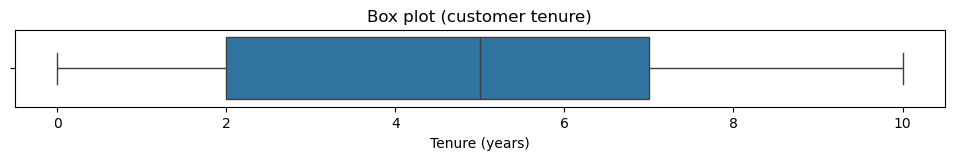

In [11]:
plt.figure(figsize=(12, 1))
sns.boxplot(x=data_clients['tenure'])
plt.title('Box plot (customer tenure)')
plt.xlabel('Tenure (years)')
plt.show()

The distribution is not normal: tenure values from **1 to 9 years** are represented approximately **uniformly**, while the boundary groups of **0 and 10 years are smaller**.
To make the final decision, we will also compare the mean and median.

In [12]:
mean_tenure = data_clients['tenure'].mean().round(3)
median_tenure = data_clients['tenure'].median()

display(f"Mean tenure: {mean_tenure}")
display(f"Median tenure: {median_tenure}")

'Mean tenure: 4.998'

'Median tenure: 5.0'

**Result**

The mean and median are almost identical. In this case, there is no meaningful difference between the two measures.

Let us also examine how customers are distributed by years of tenure:

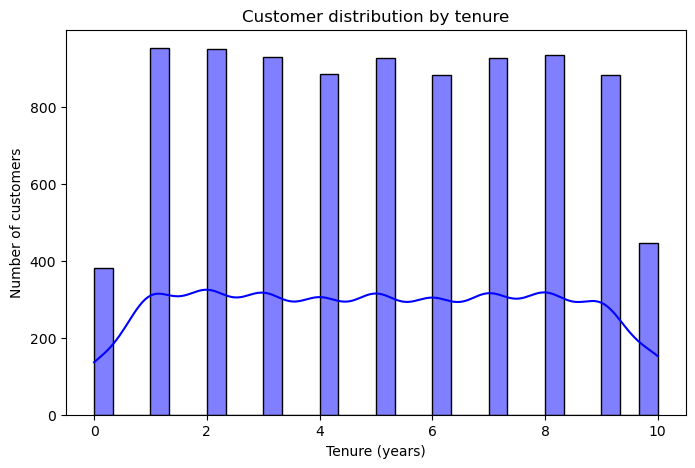

In [13]:
# Visualize the tenure distribution before missing-value imputation
plt.figure(figsize=(8, 5))
sns.histplot(data_clients['tenure'], bins=30, kde=True, color='blue')
plt.xlabel("Tenure (years)")
plt.ylabel("Number of customers")
plt.title("Customer distribution by tenure")
plt.show()

In [14]:
tenure_percent = data_clients['tenure'].value_counts(normalize=True).mul(100).round(1).reset_index()
tenure_percent.columns = ['tenure', 'percent_of_clients']
tenure_percent.sort_values(by='tenure')

,tenure,percent_of_clients
10,0.0,4.2
0,1.0,10.5
1,2.0,10.4
3,3.0,10.2
6,4.0,9.7
4,5.0,10.2
8,6.0,9.7
5,7.0,10.2
2,8.0,10.3
7,9.0,9.7


**Tenure distribution characteristics**

Most `tenure` values are represented in approximately equal proportions, while the boundary groups of **0** and **10 years** are smaller. The available data do not allow us to establish the reason for this pattern reliably, so we will treat it as a characteristic of the current sample.

**Missing-value imputation strategy for `tenure`**

If the missing values (**9%**) in `tenure` were filled with the median, the median group would almost double and the feature distribution would be noticeably distorted. Therefore, for the **subsequent exploratory analysis**, we will fill the missing values by randomly sampling from the observed `tenure` distribution, subject to the maximum tenure allowed by the customer's age. The **minimum customer age** in the dataset is **18 years**.

We will apply the following **constraint**: the customer's current age minus tenure cannot be less than **18 years**.

**Note:** Before model training, the original missing values will be restored using the `tenure_missing` indicator, and imputation will be performed again after the data are split, using only the relevant training data. This prevents information from the validation folds or the test set from being used during feature preparation.

Create a separate column that marks rows where `tenure` was originally missing. This indicator preserves the fact that a value was missing and allows us to restore the missing values before preparing the modeling data.

In [15]:
data_clients['tenure_missing'] = data_clients['tenure'].isna().astype(int) # Preserve the original tenure missingness before imputation

In [16]:
data_clients.head(2)

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,tenure_missing
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1,0
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0,0


In [17]:
display(data_clients['tenure_missing'].unique())
display(data_clients['tenure_missing'].sum())

array([0, 1])

909

**Result**

The new column was added correctly.

In [18]:
data_clients[['age', 'tenure']].describe() # Summarize age and tenure before imputation

,age,tenure
count,10000.000000,9091.000000
mean,38.921800,4.997690
std,10.487806,2.894723
min,18.000000,0.000000
25%,32.000000,2.000000
50%,37.000000,5.000000
75%,44.000000,7.000000
max,92.000000,10.000000


Create a **function** that replaces missing values with **randomly selected observed values**, while enforcing the constraint that the customer's **current age minus tenure cannot be less than 18**.

In [19]:
# Collect observed tenure values to use as the imputation pool
observed_tenure = data_clients.loc[
    data_clients['tenure'].notna(),
    'tenure'
].astype(int).to_numpy()


# Use a local seeded generator to make random imputation reproducible
tenure_rng = np.random.default_rng(RANDOM_STATE)


def random_tenure(age):
    """
    Randomly selects customer tenure from observed values while respecting the age constraint.
    """

    max_tenure = max(0, min(10, age - 18))

    allowed_values = observed_tenure[
        observed_tenure <= max_tenure
    ]

    if len(allowed_values) == 0:
        return 0

    # Randomly draw one tenure value that satisfies the age constraint
    return int(tenure_rng.choice(allowed_values))


# Identify rows whose tenure value must be imputed
missing_tenure_mask = data_clients['tenure'].isna()

# Impute only missing tenure values while respecting each customer's age constraint
data_clients.loc[missing_tenure_mask, 'tenure'] = (
    data_clients.loc[missing_tenure_mask, 'age']
    .apply(random_tenure)
)

Check the distribution of `tenure` to evaluate the imputation result.

In [20]:
data_clients[['age', 'tenure']].describe() # Verify age and tenure summary statistics after imputation

,age,tenure
count,10000.000000,10000.00000
mean,38.921800,4.99150
std,10.487806,2.89404
min,18.000000,0.00000
25%,32.000000,2.00000
50%,37.000000,5.00000
75%,44.000000,7.00000
max,92.000000,10.00000


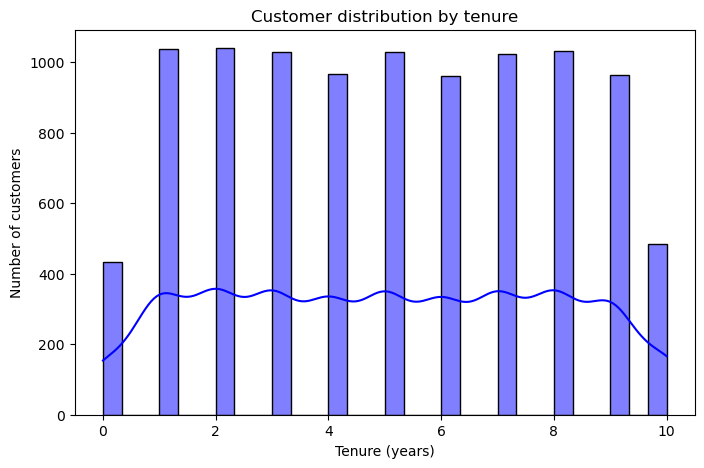

In [21]:
# Verify that imputation has preserved the overall tenure distribution
plt.figure(figsize=(8, 5))
sns.histplot(data_clients['tenure'], bins=30, kde=True, color='blue')
plt.xlabel("Tenure (years)")
plt.ylabel("Number of customers")
plt.title("Customer distribution by tenure")
plt.show()

In [22]:
data_clients['tenure'].isna().sum()

0

**Result**

After imputation, the `tenure` distribution remains close to the original distribution and no missing values remain. These values will be used in the subsequent exploratory analysis. Before model training, imputation will be repeated after the data are split.

<a id="section-1-2-3"></a>

#### Converting the Column Data Type

While examining `tenure`, we observed that it contains only **integer values**, although the column itself is not stored as an integer type.
Convert the column to an integer data type so that the table metadata represents the data more clearly.

In [23]:
# Confirm that tenure contains only integer-valued categories from 0 to 10
sorted(data_clients['tenure'].unique())

[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]

**Result**

As shown above, `tenure` contains only integer values even though the column data type is **float64**.

Convert the column to **int64**.

In [24]:
data_clients['tenure'] = data_clients['tenure'].astype(int)

In [25]:
sorted(data_clients['tenure'].unique())

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [26]:
data_clients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   row_number        10000 non-null  int64  
 1   customer_id       10000 non-null  int64  
 2   surname           10000 non-null  object 
 3   credit_score      10000 non-null  int64  
 4   geography         10000 non-null  object 
 5   gender            10000 non-null  object 
 6   age               10000 non-null  int64  
 7   tenure            10000 non-null  int32  
 8   balance           10000 non-null  float64
 9   num_of_products   10000 non-null  int64  
 10  has_cr_card       10000 non-null  int64  
 11  is_active_member  10000 non-null  int64  
 12  estimated_salary  10000 non-null  float64
 13  exited            10000 non-null  int64  
 14  tenure_missing    10000 non-null  int32  
dtypes: float64(2), int32(2), int64(8), object(3)
memory usage: 1.1+ MB


**Result**

The tables above confirm that the `tenure` data type was converted successfully.

<a id="section-1-2-4"></a>

#### Checking for Duplicates

Check the DataFrame for explicit duplicates:

In [27]:
data_clients.duplicated().sum()
# Check for completely duplicated rows

0

**Result**

No explicit duplicates were found.

We will now examine the data for potential implicit duplicates.

In [28]:
data_clients.duplicated(subset=['customer_id', 'surname', 'geography', 'gender', 'age']).sum()
# Check for repeated records using the customer identifier and core fields

0

In [29]:
data_clients.duplicated(subset=['surname', 'geography', 'gender', 'age', 'balance']).sum()
# Search for possible implicit duplicates without relying on customer_id

48

**Result**

We found **48 apparently duplicated rows**, which could suggest that the same customers were recorded under different `customer_id` values.

Examine these records in more detail.

In [30]:
duplicate_rows = data_clients[data_clients.duplicated(subset=['surname', 'geography', 'gender', 'age', 'balance'], keep = False)]
display(duplicate_rows)

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,tenure_missing
99,100,15633059,Fanucci,413,France,Male,34,8,0.0,2,0,0,6534.18,0,1
130,131,15740404,He,758,France,Female,34,3,0.0,2,1,1,124226.16,0,0
141,142,15724944,Tien,663,France,Male,34,7,0.0,2,1,1,180427.24,0,0
223,224,15733247,Stevenson,850,France,Male,33,10,0.0,1,1,0,4861.72,1,0
231,232,15627000,Freeman,610,France,Male,40,0,0.0,2,1,0,62232.60,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9366,9367,15656009,McIntyre,736,France,Female,36,6,0.0,1,1,0,70496.66,0,1
9396,9397,15763065,Palerma,700,Spain,Female,40,2,0.0,2,1,0,199753.97,0,0
9603,9604,15698927,Ritchie,675,France,Male,39,7,0.0,2,0,1,36267.21,0,0
9814,9815,15600106,Wei,631,France,Male,36,1,0.0,2,0,0,133141.34,0,0


In [31]:
duplicate_rows['balance'].unique()

array([0.])

**Result**

The records do not appear to be duplicates. They represent customers who share the same surname and also have a zero account balance.

In [32]:
data_clients.duplicated(subset=['customer_id']).sum()

0

**Result**

`customer_id` values do not repeat; each row represents a unique customer.

In [33]:
data_clients.duplicated(subset=['surname']).sum()# Count surname occurrences beyond the first occurrence

7068

In [34]:
data_clients['surname'].nunique()

2932

In [35]:
data_clients['surname'].value_counts()

surname
Smith       32
Scott       29
Martin      29
Walker      28
Brown       26
            ..
Izmailov     1
Bold         1
Bonham       1
Poninski     1
Burbidge     1
Name: count, Length: 2932, dtype: int64

**Analysis of potential implicit duplicates**

In approximately **70%** of the rows, the surname has already appeared earlier in the dataset. This is a high proportion, but it is not sufficient evidence that the records are duplicates, as confirmed by the checks across multiple columns. In addition, the bank may have replaced real surnames with fictional ones to protect customer information.

**Summary**

The checks for explicit and implicit duplicates did not identify any records that could confidently be classified as duplicates.

<a id="section-1-2-5"></a>

#### Examining Unique Column Values

Examine unique values in the remaining columns to better understand the data and detect possible errors.

In [36]:
data_clients['geography'].unique()

array(['France', 'Spain', 'Germany'], dtype=object)

In [37]:
data_clients['geography'].value_counts()

geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

**Result**

The dataset contains customers from three countries: **France, Spain, and Germany**.

In [38]:
data_clients['gender'].unique()

array(['Female', 'Male'], dtype=object)

In [39]:
data_clients['gender'].value_counts()

gender
Male      5457
Female    4543
Name: count, dtype: int64

**Result**

The `gender` column contains valid values.

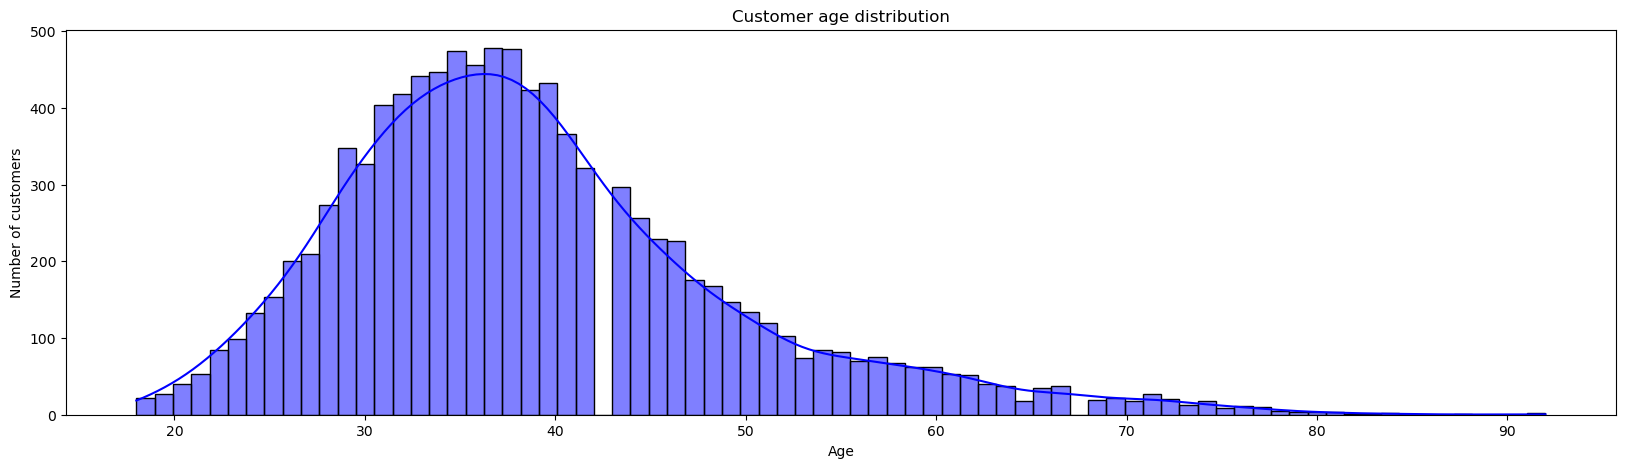

In [40]:
# Visualize the customer age distribution

plt.figure(figsize=(20, 5))
sns.histplot(data_clients['age'], bins=77, kde=True, color='blue')
plt.xlabel("Age")
plt.ylabel("Number of customers")
plt.title("Customer age distribution")
plt.show()

In [41]:
display('Minimum customer age:', data_clients['age'].min())
display('Maximum customer age:', data_clients['age'].max())

'Minimum customer age:'

18

'Maximum customer age:'

92

**Result**

The `age` column contains plausible values: there are no customers younger than **18** or older than **92**.

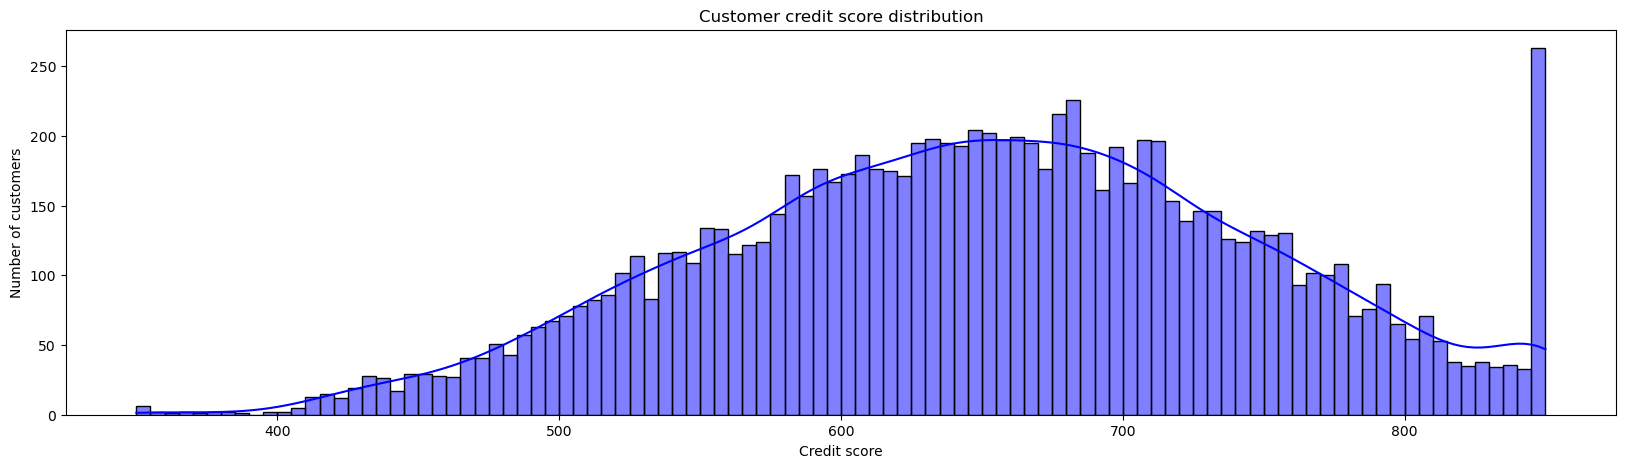

In [42]:
# Visualize the credit score distribution

plt.figure(figsize=(20, 5))
sns.histplot(data_clients['credit_score'], bins=100, kde=True, color='blue')
plt.xlabel("Credit score")
plt.ylabel("Number of customers")
plt.title("Customer credit score distribution")
plt.show()

In [43]:
display('Minimum credit score:', data_clients['credit_score'].min())
display('Maximum credit score:', data_clients['credit_score'].max())

'Minimum credit score:'

350

'Maximum credit score:'

850

In [44]:
(
    data_clients['credit_score']
    .value_counts()
    .rename_axis('credit_score')
    .reset_index(name='client_count')
    .sort_values(by='credit_score')
    .tail(5)
)

,credit_score,client_count
404,846,5
382,847,6
405,848,5
352,849,8
0,850,233


**Analysis of the `credit_score` distribution**

Overall, the values in `credit_score` appear plausible. However, the interval at the **maximum score of 850** contains an unusually large number of customers. This may indicate that **850 is the upper boundary of the scale**, so the most reliable customers receive this value even if their underlying score might have been higher on a wider scale. We may therefore be observing a **ceiling effect** that distorts the distribution among the highest-scoring customers.

Because the nature of this pattern is unknown, we will leave the feature unchanged at this stage.

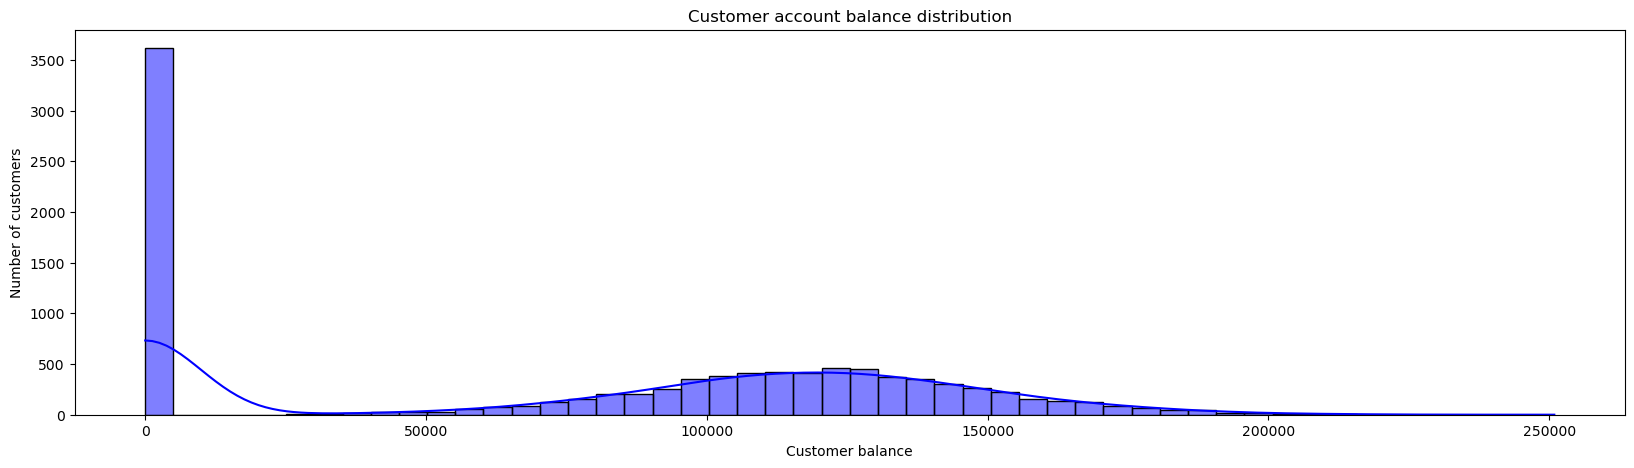

In [45]:
# Visualize the balance distribution

plt.figure(figsize=(20, 5))
sns.histplot(data_clients['balance'], bins=50, kde=True, color='blue')
plt.xlabel("Customer balance")
plt.ylabel("Number of customers")
plt.title("Customer account balance distribution")
plt.show()

In [46]:
display('Minimum balance:', data_clients['balance'].min())
display('Maximum balance:', data_clients['balance'].max())

'Minimum balance:'

0.0

'Maximum balance:'

250898.09

**Result**

A large number of customers have a **zero balance**, but the values otherwise appear plausible.

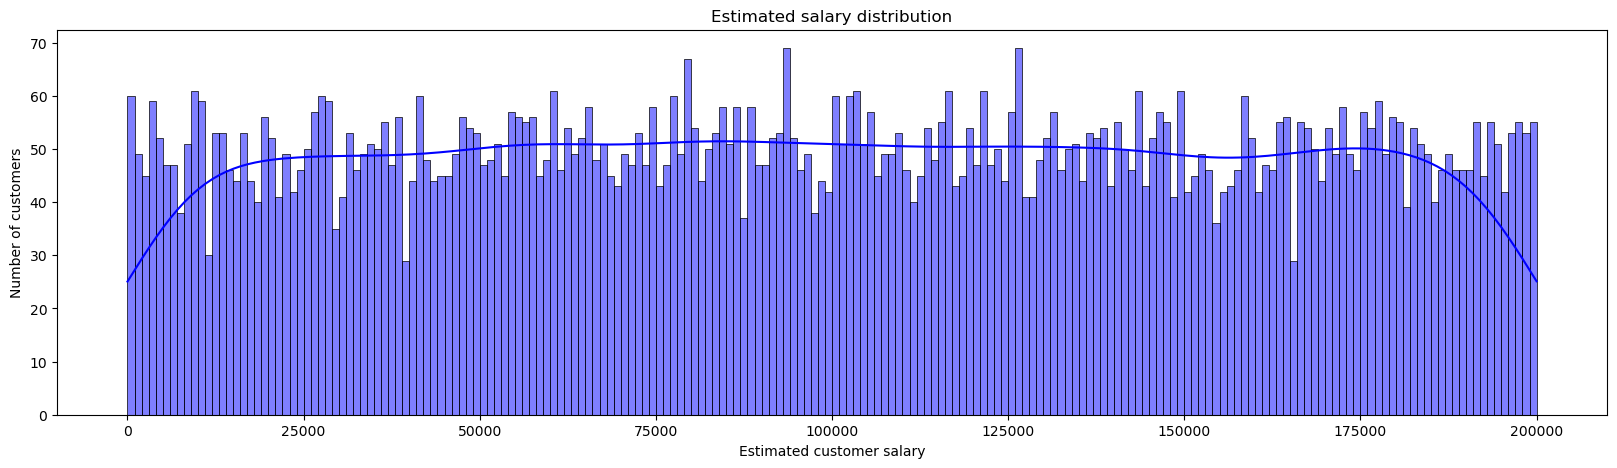

In [47]:
# Visualize the estimated salary distribution

plt.figure(figsize=(20, 5))
sns.histplot(data_clients['estimated_salary'], bins=200, kde=True, color='blue')
plt.xlabel("Estimated customer salary")
plt.ylabel("Number of customers")
plt.title("Estimated salary distribution")
plt.show()

In [48]:
display('Minimum estimated salary:', data_clients['estimated_salary'].min())
display('Maximum estimated salary:', data_clients['estimated_salary'].max())

'Minimum estimated salary:'

11.58

'Maximum estimated salary:'

199992.48

**Result**

The `estimated_salary` column contains plausible values.

In [49]:
sorted(data_clients['num_of_products'].unique())

[1, 2, 3, 4]

**Result**

Each customer uses between **1 and 4 bank products**.

In [50]:
sorted(data_clients['has_cr_card'].unique())

[0, 1]

In [51]:
sorted(data_clients['is_active_member'].unique())

[0, 1]

In [52]:
sorted(data_clients['exited'].unique())

[0, 1]

In [53]:
data_clients['row_number'].nunique()

10000

**Result**

The `num_of_products`, `has_cr_card`, `is_active_member`, `exited`, and `row_number` columns contain plausible values.

<a id="section-1-2-6"></a>

#### Removing Non-Informative Columns

Remove the columns that do not provide useful information to the models: `row_number`, `customer_id`, and `surname`.

In [54]:
data_clients_new = data_clients.drop(columns=['row_number', 'customer_id', 'surname'], errors='ignore')

In [55]:
data_clients_new.head(2)

,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,tenure_missing
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0


**Result**

The unnecessary columns were removed successfully.

<a id="section-1-3"></a>

### Data Preparation: Section Summary

**The general characteristics of the data were examined:**

- The table contains **10,000 rows** and **14 columns**.
- Data types are **object (3)**, **float64 (3)**, and **int64 (8)**, and are consistent with the column contents.

**Issues identified:**

- The `Tenure` column contains **missing values** that require treatment.
- `Surname` can be **removed**, because it is not a meaningful behavioral feature.
- `Geography` and `Gender` need to be encoded.
- `RowNumber` and `CustomerId` can be **removed**, because they do not provide useful information to the models.
- Numerical features need to be **scaled** for models that are sensitive to feature scale.

**Data preprocessing was performed:**

- Missing `tenure` values were **marked** using the `tenure_missing` indicator.
- For the **subsequent exploratory analysis**, missing `tenure` values were **filled** by sampling from the observed distribution subject to the customer's age.
- Before model training, the original missing values will be **restored** and **imputed** using only the relevant training data.
- `tenure` was converted to an **integer data type**.
- No explicit or confirmed implicit **duplicates were found**.
- **Unique column values** were examined and no invalid values were identified.
- Columns irrelevant to modeling were **removed**: `row_number`, `customer_id`, and `surname`.

<a id="section-2"></a>

## Exploratory Data Analysis

Examine the structure of the data, class and feature distributions, and relationships between variables.

<a id="section-2-1"></a>

### Statistical Analysis

Examine the data distributions numerically and visually:

In [56]:
data_clients_new[['credit_score', 'age', 'tenure', 'balance', 'num_of_products', 'has_cr_card', 'is_active_member', 'estimated_salary', 'exited']].describe()

,credit_score,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited
count,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,4.99150,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.89404,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.00000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,2.00000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.00000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.00000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.00000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


**Statistical overview of the dataset columns**

The table above shows that:

- **Credit score (`credit_score`)**:
  - mean score: **650.53**;
  - minimum: **350**, maximum: **850**;
  - standard deviation: approximately **96.65**.

- **Age (`age`)**:
  - mean customer age: approximately **39 years**;
  - range: **18–92 years**;
  - upper quartile: **44 years**.

- **Tenure (`tenure`)**:
  - mean and median tenure: approximately **5 years**;
  - range: **0–10 years**.

- **Balance (`balance`)**:
  - mean balance: **76,485.89**;
  - range: **0–250,898.09**;
  - the median is substantially higher than the first quartile because of the large separate group of customers with zero balances.

- **Number of products (`num_of_products`)**:
  - mean: **1.53 products per customer**;
  - minimum: **1**, maximum: **4**;
  - at least **75% of customers** use **no more than two products**.

- **Credit card ownership (`has_cr_card`)**:
  - **70.55%** of customers have a credit card;
  - **29.45%** do not.

- **Activity status (`is_active_member`)**:
  - **51.51%** of customers are active;
  - **48.49%** are inactive.

- **Estimated salary (`estimated_salary`)**:
  - mean: **100,090.24**;
  - range: **11.58–199,992.48**;
  - standard deviation: approximately **57,510.49**.

- **Churn (`exited`)**:
  - **20.37%** of customers left the bank;
  - **79.63%** remained.

Examine the feature distributions visually:

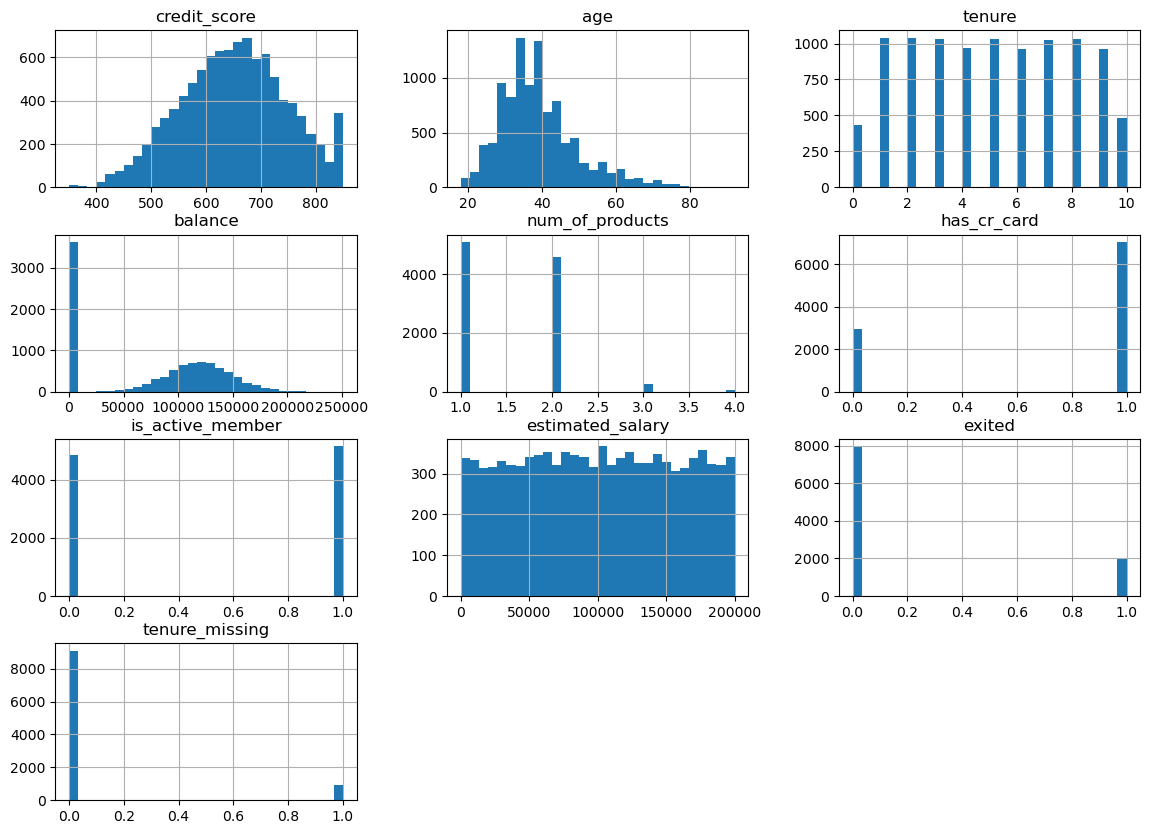

In [57]:
data_clients_new.hist(figsize=(14, 10), bins=30)
plt.show()

**Analysis of dataset column distributions**

- **Credit score (`credit_score`)**
  - The distribution is approximately **bell-shaped**, but has a pronounced spike at the upper boundary of the scale: **850 points**.

- **Age (`age`)**
  - The distribution is **right-skewed**: customers aged approximately **25–40 years** predominate in the sample.

- **Tenure (`tenure`)**
  - Values from **1 to 9 years** are represented approximately **uniformly**, while the boundary groups of **0 and 10 years are smaller**.

- **Balance (`balance`)**
  - The distribution is **heterogeneous** because of a separate high spike at zero.
  - Among positive values, most observations fall approximately between **50,000 and 150,000**.

- **Number of products (`num_of_products`)**
  - **Most customers** use **one or two products**; the groups with **three or four products** are **small**.

- **Credit card ownership (`has_cr_card`)**
  - **70.6%** of customers have a credit card and **29.4%** do not; the distribution is not balanced.

- **Activity status (`is_active_member`)**
  - **Active and inactive** customers are represented in almost **equal proportions**.

- **Estimated salary (`estimated_salary`)**
  - Values are distributed almost **uniformly** across the entire range.

<a id="section-2-2"></a>

### Outlier Analysis

Check `credit_score`, `age`, `balance`, and `estimated_salary` for outliers:

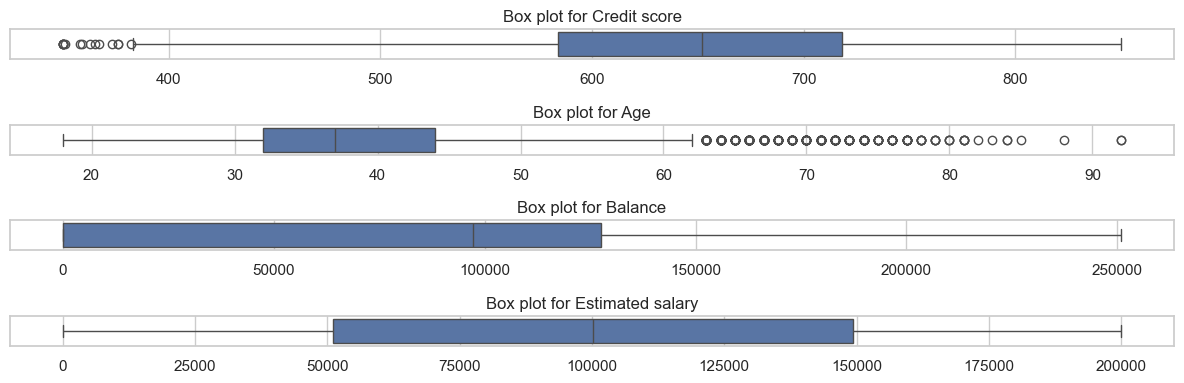

In [58]:
columns = ['credit_score', 'age', 'balance', 'estimated_salary']
column_labels = ['Credit score', 'Age', 'Balance', 'Estimated salary']

sns.set(style="whitegrid")
fig, axes = plt.subplots(len(columns), 1, figsize=(12, 4))

for ax, col, column_label in zip(axes, columns, column_labels):
    sns.boxplot(data=data_clients_new, x=col, ax=ax)
    ax.set_title(f'Box plot for {column_label}')
    ax.set_xlabel('')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

**Outlier analysis for `credit_score`, `age`, `balance`, and `estimated_salary`**

- **Credit score (`credit_score`)**
  - According to the interquartile range rule, values below approximately **380** are classified as **statistical outliers**.
  - Most observations lie between **600 and 750**, with a **median** of approximately **650**.

- **Age (`age`)**
  - According to the interquartile range rule, customers older than approximately **62 years** are classified as **statistical outliers**.
  - Most observations lie between **32 and 44 years**, with a **median age of 37**.

- **Balance (`balance`)**
  - The distribution is **heterogeneous** because of the large separate group of customers with a **zero balance**.
  - The interquartile range rule identifies **no statistical outliers**.

- **Estimated salary (`estimated_salary`)**
  - The distribution is close to **uniform**, with a **median** of approximately **100,000**.
  - **No statistical outliers were identified**.

Examine the observations classified as outliers in `credit_score`:

In [59]:
Q1 = data_clients_new['credit_score'].quantile(0.25)
Q3 = data_clients_new['credit_score'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data_clients_new[(data_clients_new['credit_score'] < lower_bound) | 
                        (data_clients_new['credit_score'] > upper_bound)]

display(outliers)
display('Number of outliers:', len(outliers))

,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,tenure_missing
7,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1,0
942,376,France,Female,46,4,0.00,1,1,0,157333.69,1,1
1193,363,Spain,Female,28,6,146098.43,3,1,0,100615.14,1,0
1405,359,France,Female,44,5,128747.69,1,1,0,146955.71,1,1
1631,350,Spain,Male,54,1,152677.48,1,1,1,191973.49,1,0
1838,350,Germany,Male,39,0,109733.20,2,0,0,123602.11,1,0
1962,358,Spain,Female,52,8,143542.36,3,1,0,141959.11,1,0
2473,351,Germany,Female,57,4,163146.46,1,1,0,169621.69,1,0
2579,365,Germany,Male,30,0,127760.07,1,1,0,81537.85,1,0
8154,367,Spain,Male,42,6,93608.28,1,1,0,168816.73,1,0


'Number of outliers:'

15

**Analysis of statistical outliers in `credit_score`**

The previous statistical analysis showed that **credit scores** range from **350 to 850 points**. All values that may appear to be outliers are close to the **minimum boundary of 350**.

Although credit scores below approximately **380** are statistical outliers, there is no reason to consider them erroneous or substantially distorting the data distribution.

In addition, all customers with a **low credit score** in this sample are marked as having **exited**. This may indicate a possible relationship between low credit scores and customer churn.

For these reasons, we **will not remove or transform these observations**.

Examine the observations classified as outliers in `age`:

In [60]:
Q1 = data_clients_new['age'].quantile(0.25)
Q3 = data_clients_new['age'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_2 = data_clients_new[(data_clients_new['age'] < lower_bound) | 
                        (data_clients_new['age'] > upper_bound)]

display(outliers_2)
display('Number of outliers:', len(outliers_2))

,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,tenure_missing
58,511,Spain,Female,66,4,0.00,1,1,0,1643.11,1,0
85,652,Spain,Female,75,3,0.00,2,1,1,114675.75,0,1
104,670,Spain,Female,65,1,0.00,1,1,1,177655.68,1,0
158,646,France,Female,73,6,97259.25,1,0,1,104719.66,0,0
181,510,France,Male,65,2,0.00,2,1,1,48071.61,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9753,656,Germany,Male,68,7,153545.11,1,1,1,186574.68,0,0
9765,445,France,Male,64,2,136770.67,1,0,1,43678.06,0,0
9832,595,Germany,Female,64,2,105736.32,1,1,1,89935.73,1,0
9894,521,France,Female,77,6,0.00,2,1,1,49054.10,0,0


'Number of outliers:'

359

**Analysis of statistical outliers in `age`**

**Most customers** are between **33 and 45 years old**, while customers **older than 62** are statistically classified as **outliers**.

Rows containing age outliers account for approximately **3.6%** of the entire dataset. However, there is no reason to consider these observations erroneous or likely to distort the subsequent analysis substantially.

Moreover, if customer age is strongly associated with churn, removing or changing these observations could reduce the accuracy of the analysis and the resulting models.

Therefore, we **will not remove or transform these data**.

<a id="section-2-3"></a>

### Target and Feature Distributions

Examine the data in more detail, including the target class balance and feature distributions:

Examine the class balance of the target feature `exited`:

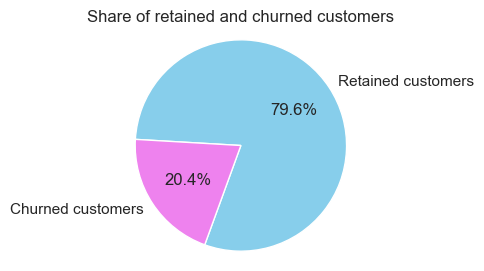

In [61]:
# Count retained and churned customers
exited_counts = data_clients_new['exited'].value_counts()

# Arrange class labels and counts in the order used in the chart
labels = ['Retained customers', 'Churned customers']
sizes = [exited_counts[0], exited_counts[1]]
colors = ['skyblue', 'violet']

# Visualize the target class balance
plt.figure(figsize=(3, 3))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=250)
plt.title('Share of retained and churned customers')
plt.axis('equal')
plt.show()

**Class distribution of `exited`**

- **80%** of customers remain with the bank.
- **20%** of customers **have left**.

**Summary:**
- The share of churned customers is substantial.
- A **substantial class imbalance** is present.

Examine the customer distribution by **gender**:

In [62]:
# Count customers in each gender category
gender_counts = data_clients_new['gender'].value_counts()
gender_counts

gender
Male      5457
Female    4543
Name: count, dtype: int64

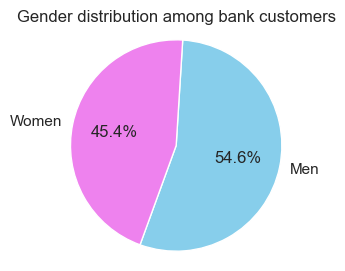

In [63]:
# Arrange gender categories in the order used in the chart
labels = ['Men', 'Women']
sizes = gender_counts.reindex(['Male', 'Female']).to_numpy()
colors = ['skyblue', 'violet']

# Visualize the overall gender composition of the customer base
plt.figure(figsize=(3, 3))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=250)
plt.title('Gender distribution among bank customers')
plt.axis('equal')
plt.show()

**Customer distribution by gender (`gender`)**

The proportions are relatively close:
- **Men** represent approximately **55%** of customers;
- **Women** represent approximately **45%**.

**Summary:**

- The share of men among bank customers is **9 percentage points** higher than the share of women.

Examine the distribution of customers by **country**:

In [64]:
# Count customers in each country
geography_counts = data_clients_new['geography'].value_counts()
geography_counts

geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

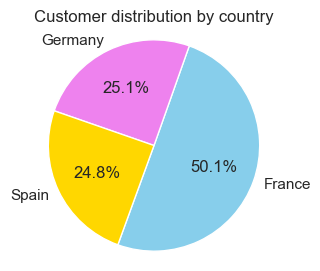

In [65]:
# Arrange countries in the order used in the chart
labels = ['France', 'Germany','Spain']
sizes = geography_counts.reindex(['France', 'Germany', 'Spain']).to_numpy()
colors = ['skyblue', 'violet', 'gold']

# Visualize the geographic composition of the customer base
plt.figure(figsize=(3, 3))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=250)
plt.title('Customer distribution by country')
plt.axis('equal')
plt.show()

**Customer distribution by country (`geography`)**

- **France**: **50%** of customers;
- **Germany**: **25%**;
- **Spain**: **25%**.

**Summary:**
- **France stands out**, accounting for **half of the observations**.

**Gender distribution by country**

Check whether the gender distribution within each country is consistent with the overall sample. This is important for the subsequent regional analysis of the relationship between gender and the target `exited`.

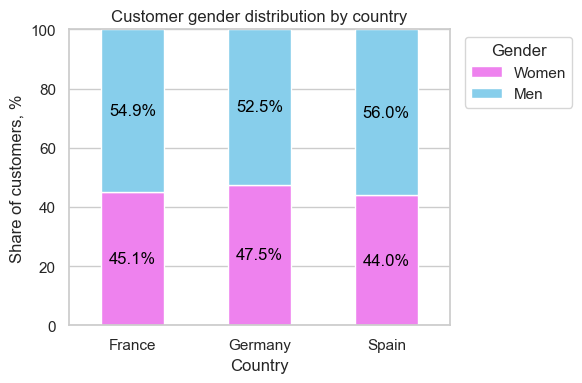

In [66]:
gender_by_country = (
    pd.crosstab(
        data_clients_new['geography'],
        data_clients_new['gender'],
        normalize='index'
    )
    .mul(100)
    .reindex(['France', 'Germany', 'Spain'])
    .rename(
        index={
            'France': 'France',
            'Germany': 'Germany',
            'Spain': 'Spain'
        },
        columns={
            'Female': 'Women',
            'Male': 'Men'
        }
    )
)

# Compare gender proportions across countries using 100% stacked bars
ax = gender_by_country.plot(
    kind='bar',
    stacked=True,
    figsize=(6, 4),
    color=['violet', 'skyblue']
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        label_type='center',
        color='black'
    )

plt.title('Customer gender distribution by country')
plt.xlabel('Country')
plt.ylabel('Share of customers, %')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Gender', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Customer distribution by gender (`gender`) across countries (`geography`)**

The gender proportions are **similar in all countries**:
- **Men** account for **52–56%**;
- **Women** account for **44–47%**.

**Summary:**

- In every country, the share of men is **5–12 percentage points** higher than the share of women.
- The gender structure of the customer base does not differ substantially across countries and is broadly consistent with the overall sample.

Examine the distribution of customers by **number of products**:

In [67]:
# Count customers by number of bank products used
num_of_products_counts = data_clients_new['num_of_products'].value_counts()
num_of_products_counts

num_of_products
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

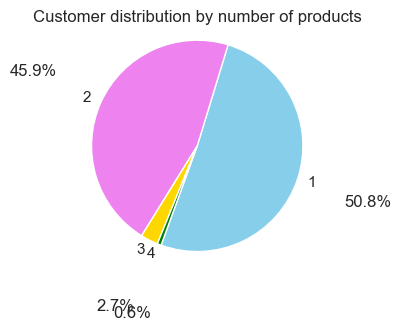

In [68]:
# Arrange product-count categories from one to four
labels = ['1', '2','3', '4']
sizes = [num_of_products_counts[1], num_of_products_counts[2], num_of_products_counts[3], num_of_products_counts[4]]
colors = ['skyblue', 'violet', 'gold', 'green']

# Visualize the customer distribution by number of products
plt.figure(figsize=(3, 3))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=250, pctdistance=1.7)
plt.title('Customer distribution by number of products')
plt.axis('equal')
plt.show()

**Customer distribution by number of products (`num_of_products`)**

- **One product**: approximately half of customers (**51%**);
- **Two products**: almost half (**46%**);
- **Three products**: almost **3%**;
- **Four products**: **less than 1%**.

**Summary:**
- Approximately **97%** of customers use **no more than two products**, while customers with **three or four products** account for only about **3%** of the sample.

Examine the proportion of customers **with and without a credit card**:

In [69]:
# Count customers with and without a credit card
has_cr_card_counts = data_clients_new['has_cr_card'].value_counts()
has_cr_card_counts

has_cr_card
1    7055
0    2945
Name: count, dtype: int64

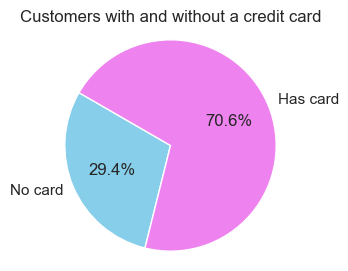

In [70]:
# Arrange credit-card categories in the order used in the chart
labels = ['No card', 'Has card']
sizes = [has_cr_card_counts[0], has_cr_card_counts[1]]
colors = ['skyblue', 'violet']

# Visualize the share of customers who own a credit card
plt.figure(figsize=(3, 3))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=150)
plt.title('Customers with and without a credit card')
plt.axis('equal')
plt.show()

**Customer distribution by credit card ownership (`has_cr_card`)**

- Approximately **71%** of customers **have a credit card**;
- approximately **29%** **do not**.

**Summary:**

- Most customers have a credit card. They outnumber customers without a card by a factor of approximately **2.4**.

Examine the proportion of **active and inactive customers**:

In [71]:
# Count active and inactive customers
is_active_member_counts = data_clients_new['is_active_member'].value_counts()
is_active_member_counts

is_active_member
1    5151
0    4849
Name: count, dtype: int64

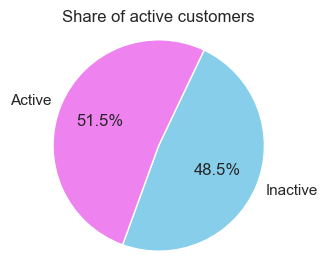

In [72]:
# Arrange activity-status categories in the order used in the chart
labels = ['Inactive', 'Active']
sizes = [is_active_member_counts[0], is_active_member_counts[1]]
colors = ['skyblue', 'violet']

# Visualize the balance between active and inactive customers
plt.figure(figsize=(3, 3))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=250)
plt.title('Share of active customers')
plt.axis('equal')
plt.show()

**Customer distribution by activity status (`is_active_member`)**

- Slightly more than half of customers are **active** (**52%**);
- **48%** are inactive.

**Summary:**

- Active and inactive customers are represented in almost equal numbers.

Examine customer **age**:

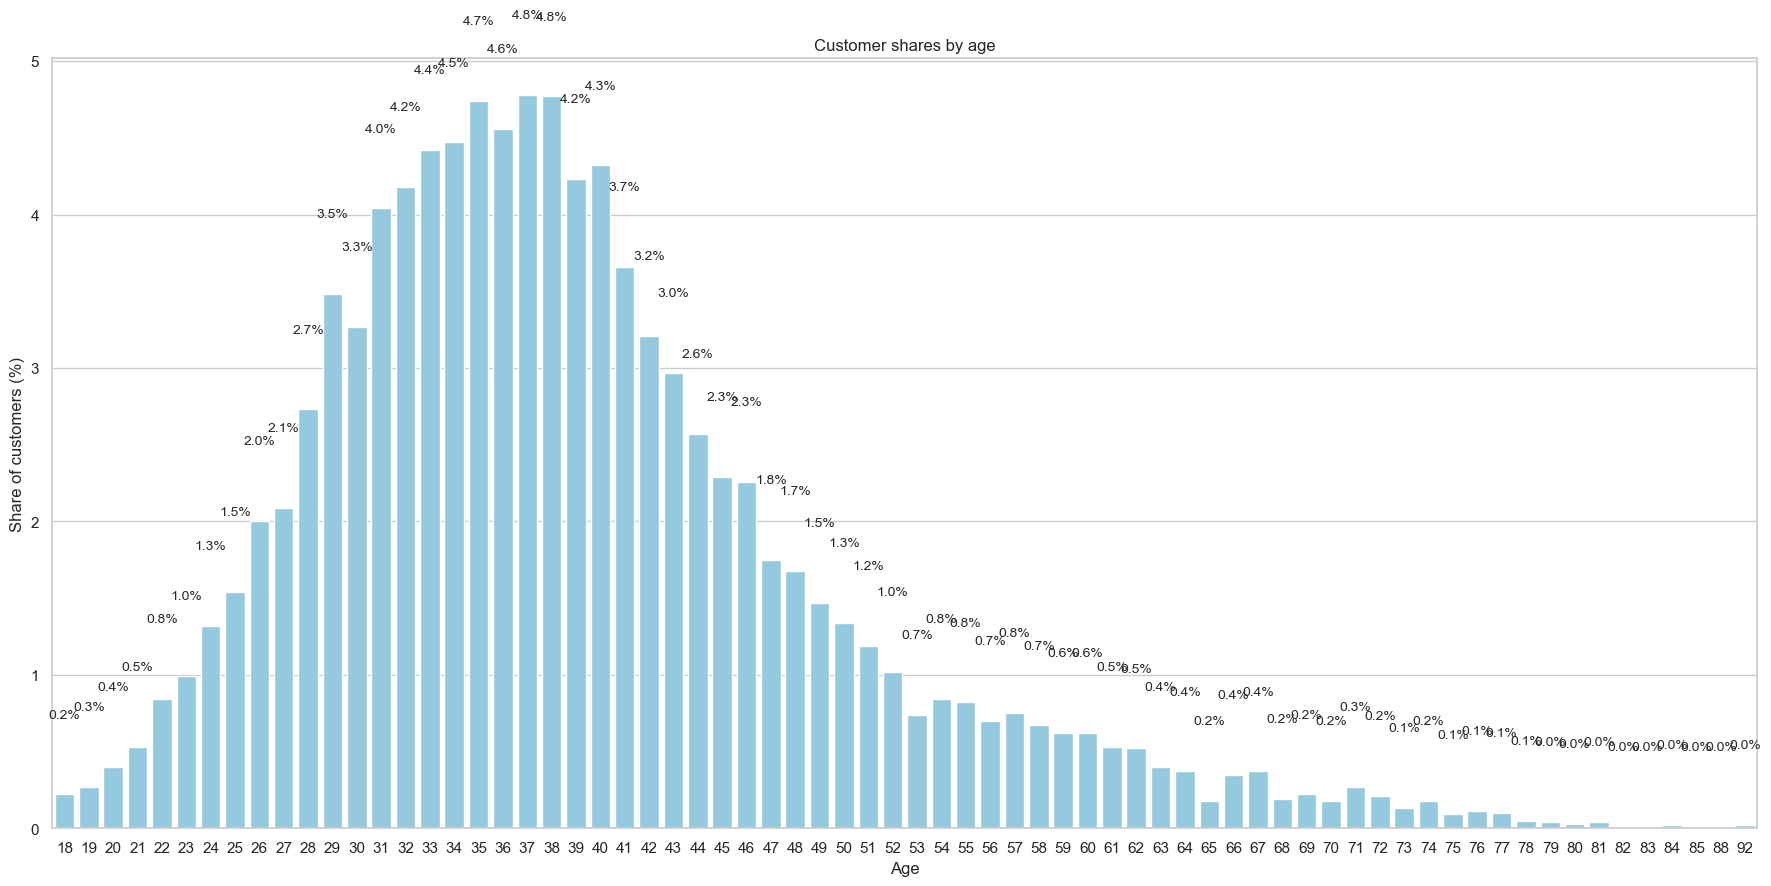

In [73]:
age_counts = data_clients_new['age'].value_counts().sort_index()

# Calculate the ages shares
age_percentage = (age_counts / age_counts.sum()) * 100

plt.figure(figsize=(22,10))
sns.barplot(x=age_percentage.index, y=age_percentage.values, color='skyblue')

# Label each bar with the corresponding customer share
for i, v in enumerate(age_percentage.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha='center', fontsize=10)

plt.xlabel('Age')
plt.ylabel('Share of customers (%)')
plt.title('Customer shares by age')
plt.xticks(rotation=0)
plt.show()

Customers aged **37 and 38** are the most numerous, each accounting for **4.7%** of the sample.

Group customers into major age intervals using a **10-year step**.

Because customers younger than 20 account for only approximately **0.5%** of the sample, combine the **under-20** and **20–29** categories into a single group: **under 30**.

In [74]:
bins = [18, 30, 40, 50, 60, 70, 101]  # Define left-closed age intervals from 18 years upward
labels = ['under 30', '30-39', '40-49', '50-59', '60-69', '70 and older']

data_clients_new['age_group'] = pd.cut(
    data_clients_new['age'], bins=bins, labels=labels, right=False
)

age_group_counts = data_clients_new['age_group'].value_counts().sort_index()

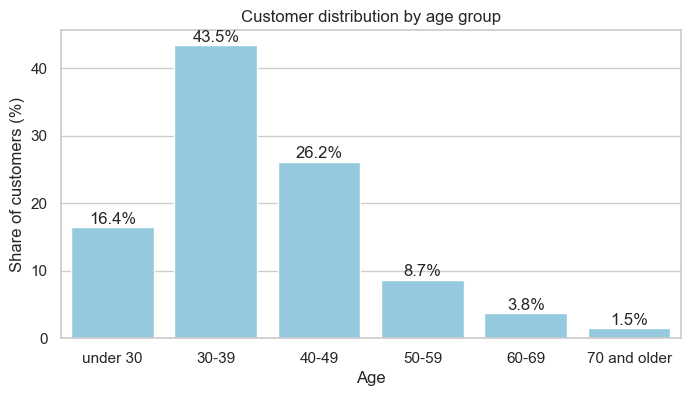

In [75]:
# Calculate the age groups shares
age_group_percentage = (age_group_counts / age_group_counts.sum()) * 100

plt.figure(figsize=(8,4))
ax = sns.barplot(x=age_group_percentage.index, y=age_group_percentage.values, color='skyblue')

# Label each age group with its share of customers
for i, v in enumerate(age_group_percentage.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha='center', fontsize=12)

plt.xlabel('Age')
plt.ylabel('Share of customers (%)')
plt.title('Customer distribution by age group')
plt.xticks(rotation=0)
plt.show()

**Customer distribution by age group (`age_group`)**

- **30–39 years**: the largest group (**43.5%**);
- **40–49 years**: slightly more than one quarter (**26.2%**);
- **under 30**: approximately **16%**;
- **50–59 years**: approximately **9%**;
- **60 and older**: approximately **5%**.

**Summary:**
- Customers **under 50** make up the majority of the sample, approximately **86%**.
- The age distribution is strongly **uneven**.

Revisit the distribution of customers by **tenure**:

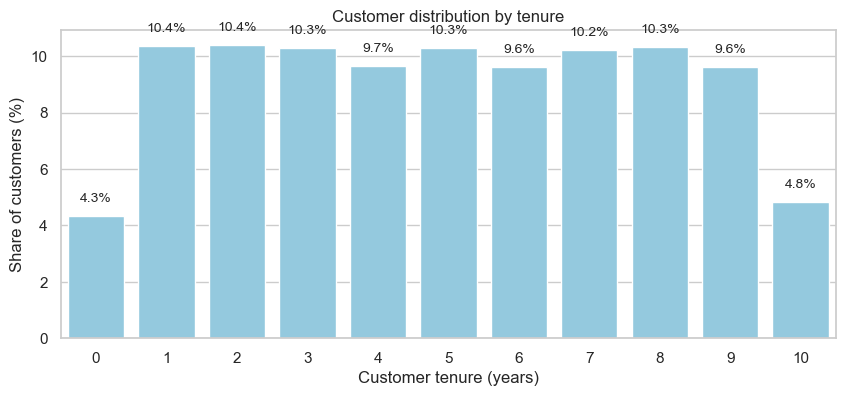

In [76]:
tenure_counts = data_clients_new['tenure'].value_counts().sort_index()

# Calculate the tenures shares
tenure_percentage = (tenure_counts / tenure_counts.sum()) * 100

plt.figure(figsize=(10,4))
sns.barplot(x=tenure_percentage.index, y=tenure_percentage.values, color='skyblue')

# Label each tenure category with its share of customers
for i, v in enumerate(tenure_percentage.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha='center', fontsize=10)

plt.xlabel('Customer tenure (years)')
plt.ylabel('Share of customers (%)')
plt.title('Customer distribution by tenure')
plt.xticks(rotation=0)
plt.show()

**Customer distribution by bank tenure (`tenure`)**

Most tenure groups contain approximately **9–10%** of customers. The boundary groups of **0 years** and **10 years** are smaller, each accounting for approximately **4–5%** of observations.

The available data do not allow us to determine reliably why the boundary groups are smaller. Filling missing values by sampling from the observed distribution subject to customer age preserves the overall shape of the `tenure` distribution and does not create an artificial spike in one category.

However, this method assumes that missingness is not systematically related to true customer tenure. For example, if customers with missing `tenure` were in fact concentrated in the **0-year** or **10-year** groups, the selected imputation method could distort the distribution.

In a real project, the tenure calculation methodology and the reasons for missing values should be clarified with the relevant colleagues. The smaller boundary groups could reflect either the customer base structure or the rules used to round and calculate completed years of service. Without additional information, these explanations remain hypotheses.

Examine customer groups by **credit score**:

Group credit scores using intervals of **50 points**:

In [77]:
bins = list(range(350, 801, 50)) + [851]
labels = [f"{i}-{i+49}" for i in range(350, 800, 50)] + ['800-850']

data_clients_new['credit_score_group'] = pd.cut(
    data_clients_new['credit_score'], bins=bins, labels=labels, right=False
)

# Count customers in each ordered credit score interval
credit_group_counts = data_clients_new['credit_score_group'].value_counts().sort_index()

In [78]:
credit_group_percentage = (credit_group_counts / credit_group_counts.sum()) * 100

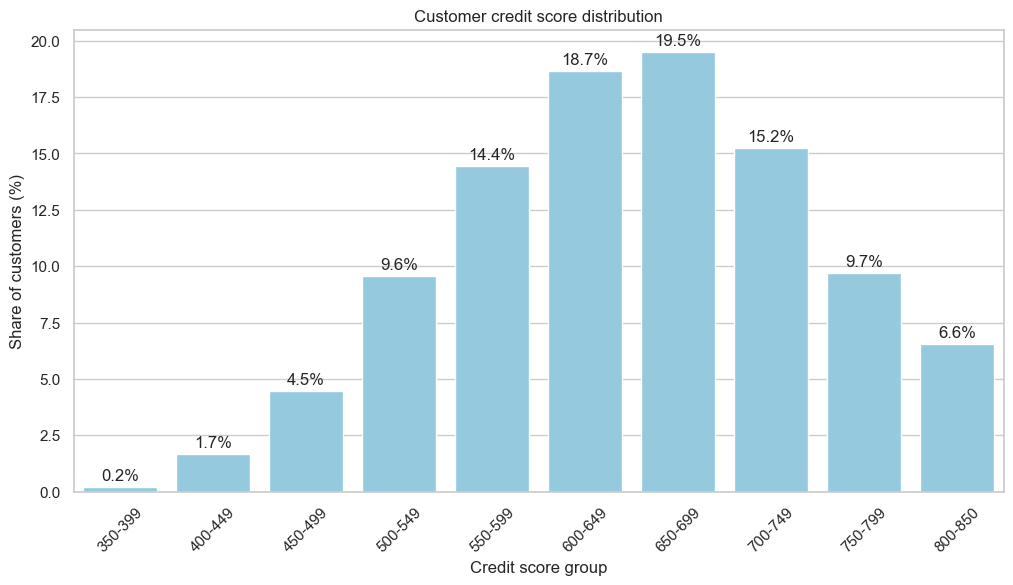

In [79]:
plt.figure(figsize=(12,6))
ax = sns.barplot(x=credit_group_percentage.index, y=credit_group_percentage.values, color='skyblue')

# Label each credit score interval with its customer share
for i, v in enumerate(credit_group_percentage.values):
    plt.text(i, v + 0.3, f"{v:.1f}%", ha='center', fontsize=12)

plt.xlabel('Credit score group')
plt.ylabel('Share of customers (%)')
plt.title('Customer credit score distribution')
plt.xticks(rotation=45)
plt.show()

**Customer distribution by credit score group (`credit_score_group`)**

**Most customers are concentrated between 550 and 749**

* The largest shares fall into **650–699 (19.5%)** and **600–649 (18.7%)**.
* The **550–599 (14.4%)** and **700–749 (15.2%)** groups also contain substantial shares of customers.
* Most observations are therefore concentrated in the central part of the available credit score range.

**The extreme groups are less common**

* Relatively few customers have scores below 500: **350–399 — 0.2%**, **400–449 — 1.7%**, and **450–499 — 4.5%**.
* The **750–799** and **800–850** groups account for **9.7%** and **6.6%**, respectively.
* Customers with extreme credit score values are therefore less common in the sample.

**Summary**

- The distribution is uneven.
- This pattern may reflect the customer base structure, the scoring scale, the sample formation process, or the bank's credit policy. Banks may consider credit score when approving and setting the terms of credit products. However, the available data do not include applications, rejections, lending terms, or reasons for churn. They therefore cannot establish why the extreme score groups are smaller or support a reliable conclusion about the bank's policy.

Examine customer groups by account balance:

Group balances into the main intervals using a **25,000-unit step**:

In [80]:
bins = [0, 1, 25000, 50000, 75000, 100000, 125000, 150000, 175000, 200000, 225000, 251000]  
labels = ['0', '1-24', '25-49', '50-74', '75-99', '100-124', 
          '125-149', '150-174', '175-199', '200-224', '225-251']  

data_clients_new['balance_group'] = pd.cut(data_clients_new['balance'], bins=bins, labels=labels, right=False)

balance_group_counts = data_clients_new['balance_group'].value_counts().sort_index()

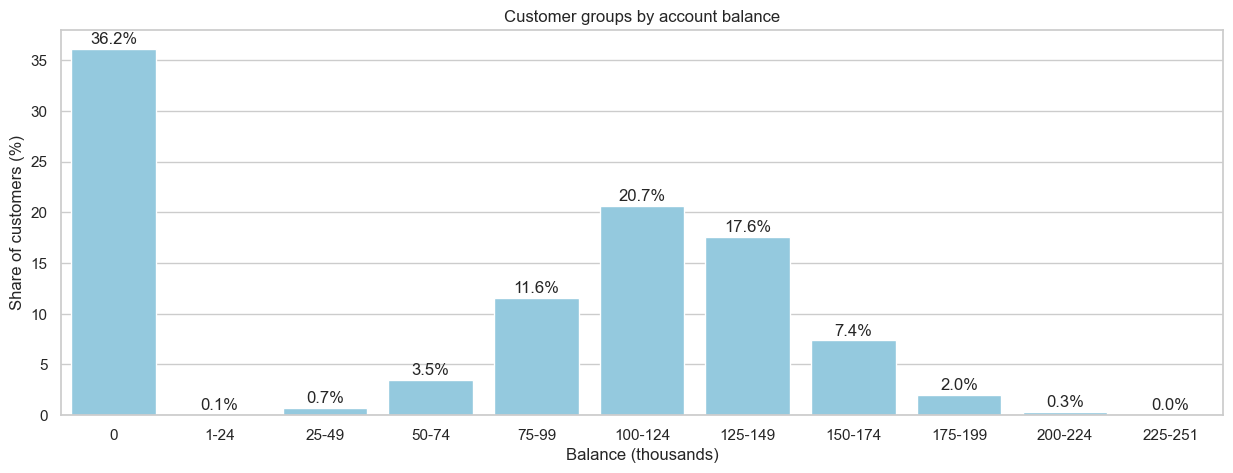

In [81]:
# Calculate the balance groups shares
balance_group_percentage = (balance_group_counts / balance_group_counts.sum()) * 100

plt.figure(figsize=(15,5))
ax = sns.barplot(x=balance_group_percentage.index, y=balance_group_percentage.values, color='skyblue')

# Label each balance interval with its customer share
for i, v in enumerate(balance_group_percentage.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha='center', fontsize=12)

plt.xlabel('Balance (thousands)')
plt.ylabel('Share of customers (%)')
plt.title('Customer groups by account balance')
plt.xticks(rotation=0)
plt.show()

**Customer distribution by account balance range (`balance_group`)**

**A substantial share of customers have a zero balance**

- The largest group, **36%** of customers, has a **zero balance**.
- A zero balance may reflect, for example, a temporary absence or withdrawal of funds. The available data do not allow the reason to be determined reliably.

**Positive balances are concentrated most heavily between 100,000 and 149,000**

- Approximately **21%** of customers fall into the **100,000–124,000** group.
- Approximately **18%** fall into the **125,000–149,000** group.
- Therefore, approximately **38%** of customers hold **100,000–150,000** in their accounts.
- Approximately **64%** of customers have a positive balance.

**The extreme intervals are small**

- Balances **below 50,000** and **above 175,000** are uncommon (**about 3%**).
- Subsequent churn results for the extreme groups should therefore be interpreted cautiously.

**Summary**
- The balance distribution is **heterogeneous**: a large separate group has a zero balance, while positive balances are concentrated mainly between **100,000 and 149,000**. The available data cannot explain zero balances, establish customer wealth, or determine the influence of bank policy. Possible explanations should therefore be treated as hypotheses requiring additional data.

Examine customer groups by **estimated salary**:

Group estimated salaries into the main intervals using a **25,000-unit step**:

In [82]:
bins = [1, 25000, 50000, 75000, 100000, 125000, 150000, 175000, 200000]  
labels = ['1-24', '25-49', '50-74', '75-99', '100-124', 
          '125-149', '150-174', '175-199']  

data_clients_new['estimated_salary_group'] = pd.cut(data_clients_new['estimated_salary'], bins=bins, labels=labels, right=False)

estimated_salary_group_counts = data_clients_new['estimated_salary_group'].value_counts().sort_index()

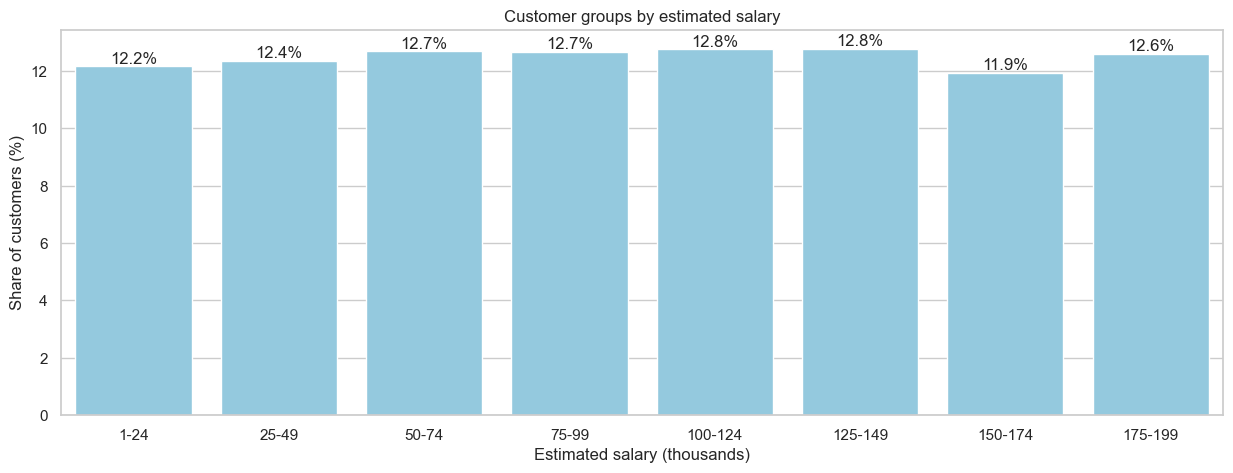

In [83]:
# Calculate the salary groups shares
estimated_salary_group_percentage = (estimated_salary_group_counts / estimated_salary_group_counts.sum()) * 100

plt.figure(figsize=(15,5))
ax = sns.barplot(x=estimated_salary_group_percentage.index, y=estimated_salary_group_percentage.values, color='skyblue')

# Label each salary interval with its customer share
for i, v in enumerate(estimated_salary_group_percentage.values):
    plt.text(i, v + 0.1, f"{v:.1f}%", ha='center', fontsize=12)

plt.xlabel('Estimated salary (thousands)')
plt.ylabel('Share of customers (%)')
plt.title('Customer groups by estimated salary')
plt.xticks(rotation=0)
plt.show()

**Customer distribution by estimated salary range (`estimated_salary_group`)**

- Customers are distributed almost **uniformly** across the eight ranges.
- Each group contains approximately **12–13%** of observations.

**Summary:**

- The sample contains comparable numbers of observations across all estimated salary ranges.
- Such a uniform income distribution appears unusual: real-world salary data are more often asymmetric. In a real project, the calculation of `estimated_salary` and the sample construction process should be clarified.
- The pattern may be related to the data generation or selection procedure. The observations may have been constructed to provide comparable representation of different income levels, but uniformity alone does not confirm this hypothesis.
- Without additional information, it is impossible to determine whether the distribution reflects the true customer base or the way the dataset was prepared. The distribution alone also does not establish the effect of salary on churn or reveal the bank's customer policy. These explanations therefore remain hypotheses.

**Target and feature distributions: conclusion**

The target `exited` has a **substantial class imbalance**: customers who left the bank are substantially less numerous than those who remained. This imbalance may cause the model to identify churn-prone customers less effectively. It should therefore be accounted for during modeling, and several treatment strategies should be compared.

The following feature distributions are also **uneven**:
- `geography`
- `num_of_products`
- `has_cr_card`
- `age`
- `tenure`
- `credit_score`
- `balance_group`

However, these patterns are **not class imbalance requiring mandatory correction**. Small categories and intervals should instead be considered when interpreting subsequent results, because their estimates may be less stable.

<a id="section-2-4"></a>

### Relationships Between Variables

<a id="section-2-4-1"></a>

#### General Overview of Relationships

Analyze the relationships between the predictor features and the target. Because the dataset contains both numerical and categorical variables, use **Phi_K**, which measures the strength of linear and nonlinear relationships between variables of different types.

Phi_K does not show the direction of a relationship. We will therefore investigate the nature of the identified patterns using proportions, medians, and visualizations.

Examine the target's relationships with both the **original numerical features** and their auxiliary **grouped versions**. Combining values into intervals may reduce random fluctuations and make nonlinear relationships more visible.

In [84]:
columns_for_phik = [
    'geography',
    'gender',
    'age',
    'age_group',
    'credit_score',
    'credit_score_group',
    'tenure',
    'tenure_missing',
    'balance',
    'balance_group',
    'num_of_products',
    'has_cr_card',
    'is_active_member',
    'estimated_salary',
    'estimated_salary_group',
    'exited'
]

data_clients_phik = data_clients_new[columns_for_phik].copy()

# Identify numerical variables that Phi_K should treat as interval features
interval_cols = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'estimated_salary'
]

In [85]:
# Calculate the Phi_K matrix for the original and grouped features
phik_matrix = data_clients_phik.phik_matrix(
    interval_cols=interval_cols,
    njobs=1
)

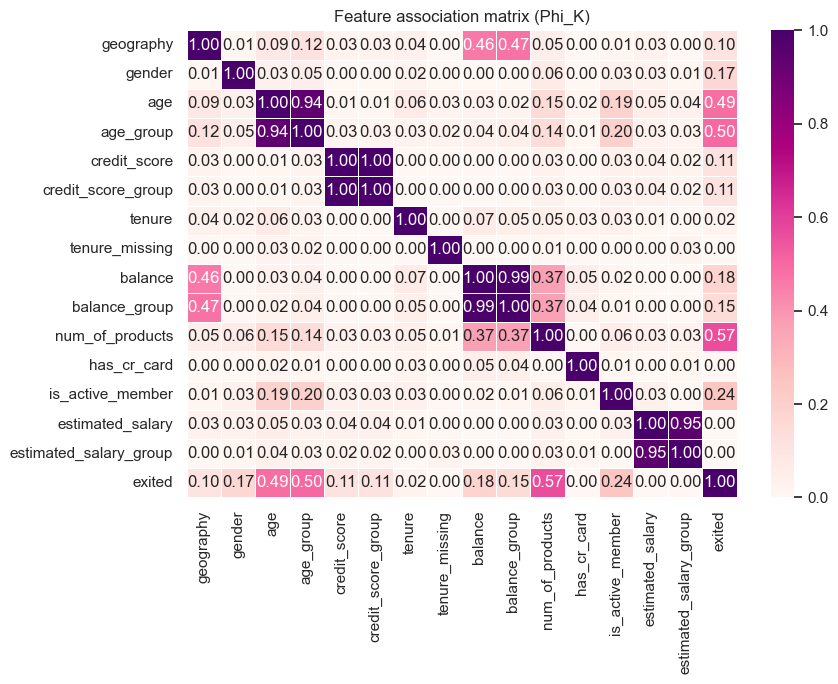

In [86]:
# Visualize association strengths across all selected variables
plt.figure(figsize=(9, 7))

sns.heatmap(
    phik_matrix,
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1,
    cmap='RdPu',
    linewidths=0.5
)

plt.title('Feature association matrix (Phi_K)')
plt.tight_layout()
plt.show()

**Overview of relationships between variables**

Off-diagonal Phi_K values range from **0 to 0.57**. Most relationships are weak, although several feature pairs show noticeable associations. The coefficients for grouped features are close to those of the corresponding original features, with differences ranging from **−0.03 to +0.02**.

The grouped features therefore provide little additional information about relationship strength. The original features will be used for subsequent Phi_K calculations and model training, while the grouped versions will be retained only for additional interpretation and visualization.

The relationships above were calculated for the complete dataset. Because their patterns may **differ across regions**, calculate separate **Phi_K matrices for each country** and identify the main differences.

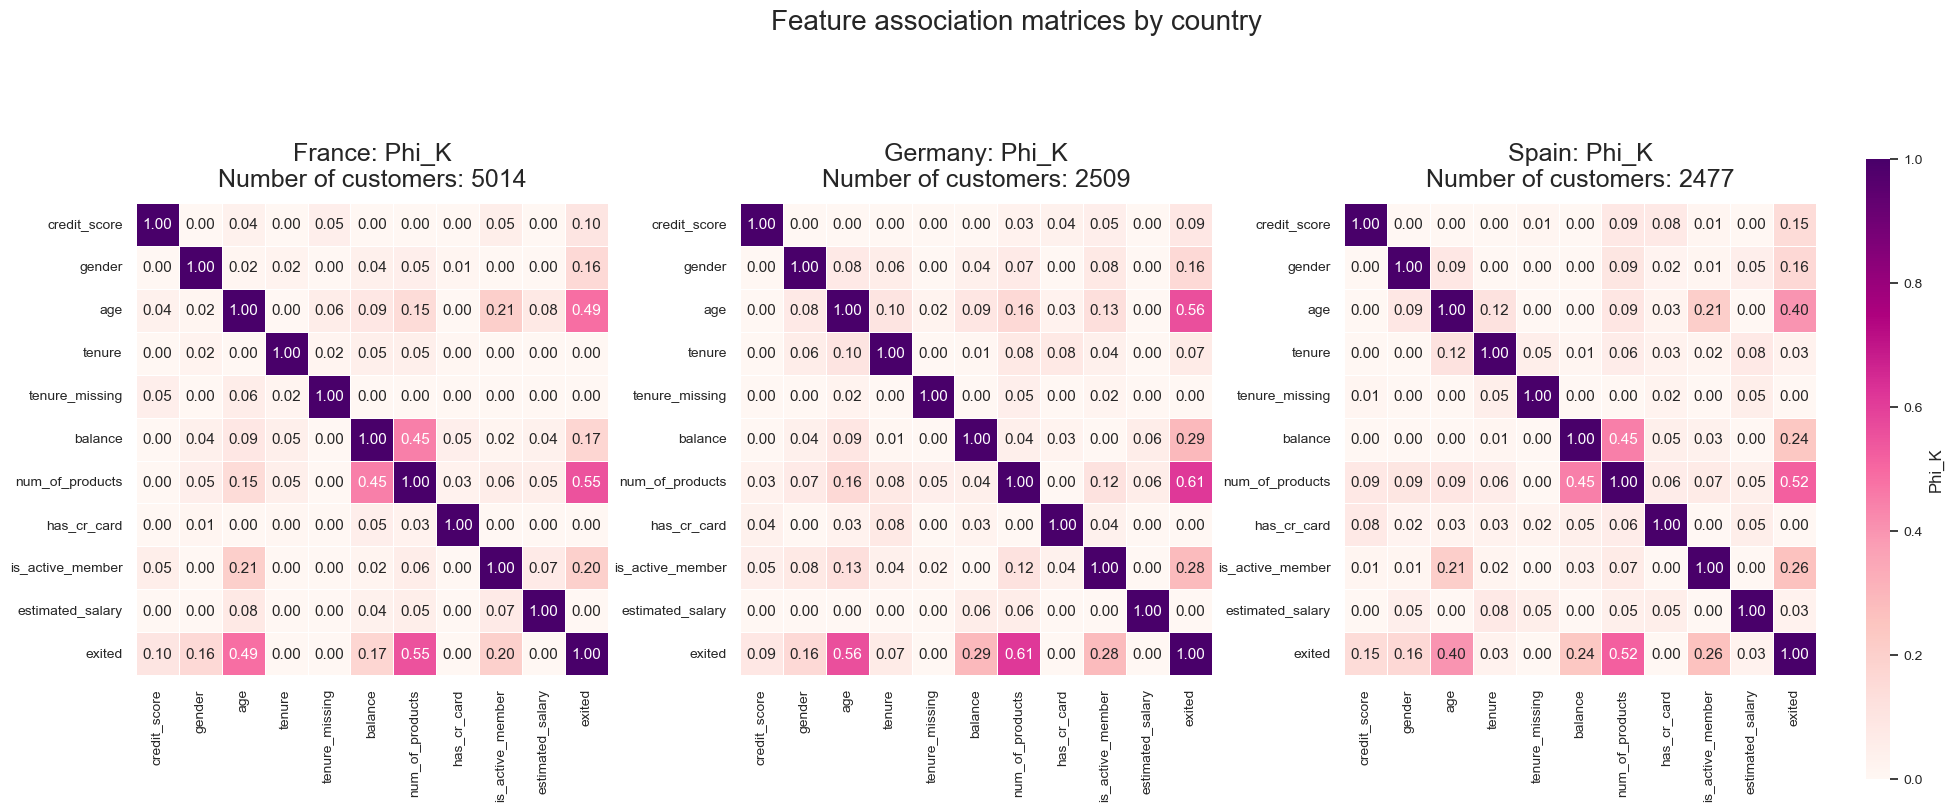

In [87]:
# Select the original features for country-level Phi_K analysis
columns_for_phik_2 = [
    'credit_score',
    'geography',
    'gender',
    'age',
    'tenure',
    'tenure_missing',
    'balance',
    'num_of_products',
    'has_cr_card',
    'is_active_member',
    'estimated_salary',
    'exited'
]


# Define the countries included in the regional comparison
country_names = {
    'France': 'France',
    'Germany': 'Germany',
    'Spain': 'Spain'
}
data_clients_phik_2 = data_clients_new[columns_for_phik_2].copy()

# Identify numerical variables that Phi_K should treat as interval features
interval_cols = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'estimated_salary'
]



phik_matrices_by_country = {}

for country in country_names:
    # Remove geography because it is constant within each country
    country_data = (
        data_clients_phik_2
        .loc[data_clients_phik_2['geography'] == country]
        .drop(columns='geography')
    )

    phik_matrices_by_country[country] = country_data.phik_matrix(
        interval_cols=interval_cols,
        njobs=1
    )

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 10)
)

fig.subplots_adjust(
    left=0.06,
    right=0.90,
    top=0.86,
    bottom=0.22,
    wspace=0.28
)

colorbar_ax = fig.add_axes([
    0.925,
    0.20,
    0.012,
    0.62
])

for index, (country, country_name) in enumerate(
    country_names.items()
):
    ax = axes[index]
    country_matrix = phik_matrices_by_country[country]

    sns.heatmap(
        country_matrix,
        annot=True,
        fmt='.2f',
        vmin=0,
        vmax=1,
        cmap='RdPu',
        linewidths=0.5,
        square=True,
        annot_kws={'fontsize': 11},

        cbar=index == len(country_names) - 1,
        cbar_ax=(
            colorbar_ax
            if index == len(country_names) - 1
            else None
        ),
        cbar_kws={'label': 'Phi_K'},
        ax=ax
    )

    client_count = (
        data_clients_phik_2['geography'] == country
    ).sum()

    ax.set_title(
        f'{country_name}: Phi_K\n'
        f'Number of customers: {client_count}',
        fontsize=18,
        pad=12
    )

    ax.tick_params(
        axis='x',
        rotation=90,
        labelsize=10
    )

    ax.tick_params(
        axis='y',
        rotation=0,
        labelsize=10
    )

colorbar_ax.tick_params(labelsize=10)
colorbar_ax.yaxis.label.set_size(12)

fig.suptitle(
    'Feature association matrices by country',
    fontsize=20,
    y=0.97
)

plt.show()

**Overview of relationships by country**

The main patterns remain similar across countries. The target `exited` has its strongest associations with the **number of products** (**0.52–0.61**) and customer **age** (**0.40–0.56**). Both are strongest in **Germany**.

Several **differences** are also present. In **France** and **Spain**, balance and number of products have a noticeable association of approximately **0.45**, while in **Germany** it is much weaker at **0.04**. The relationship between **age** and **activity status** is also weaker in Germany (**0.13**) than in France and Spain (**0.21**). Conversely, the relationship between **balance** and **churn** is stronger in Germany (**0.29**) and Spain (**0.24**) than in France (**0.17**).

**Criteria for selecting relationships for detailed analysis**

The overview table will include every pair with a **Phi_K of at least 0.10** in any sample, allowing both overall and regional signals to be seen. Relationships with the target will be examined in detail when Phi_K is at least **0.10** in the full sample. Relationships among predictor features will be examined in detail when Phi_K is at least **0.15** in the full sample. Weaker values will be noted but not interpreted in detail.

**Note:** these thresholds are exploratory guidelines rather than statistical-significance criteria. Cross-country coefficients should also be compared with country sample sizes in mind.

In [88]:
phik_threshold = 0.10

# Collect the full-sample and country-level matrices for comparison
matrices_for_comparison = {
    'All customers': phik_matrix,
    'France': phik_matrices_by_country['France'],
    'Germany': phik_matrices_by_country['Germany'],
    'Spain': phik_matrices_by_country['Spain']
}


# Extract the upper triangle so that each feature pair appears only once
def extract_phik_pairs(matrix, column_name):
    upper_triangle = np.triu(
        np.ones(matrix.shape, dtype=bool),
        k=1
    )

    phik_pairs = (
        matrix
        .where(upper_triangle)
        .stack()
        .rename(column_name)
    )

    phik_pairs.index = phik_pairs.index.set_names(
        ['feature_1', 'feature_2']
    )

    return phik_pairs


# Align Phi_K coefficients for the same feature pairs across all samples
association_series = [
    extract_phik_pairs(matrix, sample_name)
    for sample_name, matrix in matrices_for_comparison.items()
]

strong_associations = (
    pd.concat(
        association_series,
        axis=1
    )
    .reset_index()
)

phik_columns = list(matrices_for_comparison.keys())

strong_associations['max_phi_k'] = (
    strong_associations[phik_columns]
    .max(axis=1)
)

# Retain pairs that reach the exploratory threshold in at least one sample
strong_associations = (
    strong_associations[
        strong_associations['max_phi_k'] >= phik_threshold
    ]
    .sort_values(
        'max_phi_k',
        ascending=False
    )
    .drop(columns='max_phi_k')
    .reset_index(drop=True)
)

display(
    'Associations with Phi_K of at least 0.10 '
    'in at least one sample:',
    strong_associations.round(3)
)

'Associations with Phi_K of at least 0.10 in at least one sample:'

,feature_1,feature_2,All customers,France,Germany,Spain
0,credit_score,credit_score_group,1.000,NaN,NaN,NaN
1,balance,balance_group,0.995,NaN,NaN,NaN
2,estimated_salary,estimated_salary_group,0.949,NaN,NaN,NaN
3,age,age_group,0.940,NaN,NaN,NaN
4,num_of_products,exited,0.565,0.552,0.614,0.523
5,age,exited,0.487,0.486,0.561,0.400
6,age_group,exited,0.503,NaN,NaN,NaN
7,geography,balance_group,0.473,NaN,NaN,NaN
8,geography,balance,0.464,NaN,NaN,NaN
9,balance,num_of_products,0.371,0.446,0.043,0.448


**Key relationships in the full sample and by country**

In the full sample, the most noticeable associations are between `exited` and number of products (**0.565**), `exited` and age (**0.487**), geography and balance (**0.464**), and balance and number of products (**0.371**).

Number of products and age remain the two features most strongly associated with churn in all three countries. `NaN` values for pairs involving `geography` in the country columns are expected: geography is constant within each country, so the coefficient cannot be calculated.

The relationships between age and number of products (**0.145** in the full sample), number of products and activity (**0.057**), and age and tenure (**0.064**) do not reach the selected **0.15** threshold for detailed predictor-to-predictor analysis. Their maximum country values are **0.160**, **0.115**, and **0.117**, respectively, providing insufficient evidence that the regional differences are stable. The weak age–tenure relationship may also be partly affected by the age constraint applied during exploratory imputation.

<a id="section-2-4-2"></a>

#### Relationships Between the Target `exited` and Other Features

Examine the relationships in greater detail to determine their form.

Begin with the strongest relationships involving the target `exited`:

In [89]:
strong_associations.query("feature_2 == 'exited'").round(3)

,feature_1,feature_2,All customers,France,Germany,Spain
4,num_of_products,exited,0.565,0.552,0.614,0.523
5,age,exited,0.487,0.486,0.561,0.400
6,age_group,exited,0.503,NaN,NaN,NaN
11,balance,exited,0.183,0.173,0.291,0.237
12,is_active_member,exited,0.242,0.202,0.284,0.259
15,gender,exited,0.165,0.159,0.158,0.164
17,balance_group,exited,0.149,NaN,NaN,NaN
18,credit_score,exited,0.112,0.098,0.088,0.147
23,credit_score_group,exited,0.112,NaN,NaN,NaN
24,geography,exited,0.105,NaN,NaN,NaN


**Approach to analyzing relationships with `exited`**

First, calculate the proportions of customers who left and remained within each group for the full sample. Then repeat the calculations by country to determine whether the patterns persist within regions. Visualize the results. This approach shows which groups have the highest churn rates and how the relationships differ across countries.

**Relationship between `exited` and `num_of_products`**

exited                            Retained, %  Churned, %  Number of customers
Sample        Number of products                                              
All customers 1                         72.29       27.71                 5084
              2                         92.42        7.58                 4590
              3                         17.29       82.71                  266
              4                          0.00      100.00                   60
France        1                         77.57       22.43                 2514
              2                         94.30        5.70                 2367
              3                         21.15       78.85                  104
              4                          0.00      100.00                   29
Germany       1                         57.15       42.85                 1349
              2                         87.88       12.12                 1040
              3                         10.42       89.58                   96
              4                          0.00      100.00                   24
Spain         1                         78.13       21.87                 1221
              2                         92.65        7.35                 1183
              3                         21.21       78.79                   66
              4                          0.00      100.00                    7

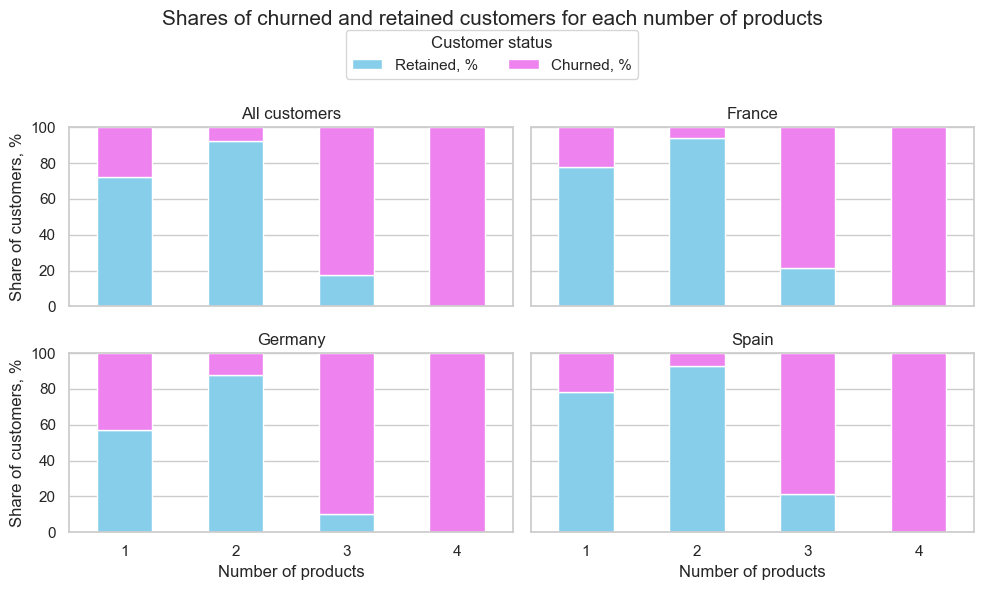

In [90]:
# Calculate retained and churned shares for each product-count category
def calculate_products_status_share(data, sample_name):
    products_share = pd.crosstab(
        data['num_of_products'],
        data['exited'],
        normalize='index'
    ).reindex(columns=[0, 1], fill_value=0).mul(100)

    products_share = products_share.rename(
        columns={
            0: 'Retained, %',
            1: 'Churned, %'
        }
    )

    products_share['Number of customers'] = (
        data
        .groupby('num_of_products')
        .size()
    )

    products_share = (
        products_share
        .round(2)
        .reset_index()
        .rename(
            columns={
                'num_of_products': 'Number of products'
            }
        )
    )

    products_share.insert(
        0,
        'Sample',
        sample_name
    )

    return products_share


# Apply the calculation to the full sample and each country
products_status_share = pd.concat(
    [
        calculate_products_status_share(
            data_clients_new,
            'All customers'
        ),
        calculate_products_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'France'
            ],
            'France'
        ),
        calculate_products_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Germany'
            ],
            'Germany'
        ),
        calculate_products_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

display(
    products_status_share.set_index(
        ['Sample', 'Number of products']
    )
)


# Compare product–churn patterns across the full sample and countries
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 6),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    sample_data = (
        products_status_share[
            products_status_share['Sample'] == sample_name
        ]
        .set_index('Number of products')
    )

    sample_data[
        ['Retained, %', 'Churned, %']
    ].plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['skyblue', 'violet'],
        legend=False
    )

    ax.set_title(sample_name)
    ax.set_xlabel('Number of products')
    ax.set_ylabel('Share of customers, %')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0)

# Add one shared legend for all subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Customer status',
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    'Shares of churned and retained customers '
    'for each number of products',
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

**Number of products (`num_of_products`) — Phi_K = 0.565.**

**Full dataset.** A strong nonlinear relationship is present between the number of products used and customer churn. The lowest churn rate occurs among customers with two products: **7.58%**. It is **27.71%** for customers with one product and rises sharply to **82.71%** and **100%** for customers with three and four products, respectively. The churn-rate pattern resembles an **asymmetric U-shaped relationship**, with a minimum at **two products**. However, the term U-shaped should be used cautiously because the feature has only **four discrete values**, and the three- and four-product groups contain only **266** and **60 customers**, respectively.

**Countries.** The same nonlinear pattern appears in every country. The lowest churn rate occurs among customers with two products: **5.70%** in France, **12.12%** in Germany, and **7.35%** in Spain. Among customers with one product, the corresponding rates are higher at **22.43%**, **42.85%**, and **21.87%**. With three products, churn rises sharply to **78.79–89.58%**, and with four products it reaches **100%** in every country. The three- and four-product groups are small. Thus, the relationship is similar across regions, although German customers with one to three products churn more often. This is consistent with Germany's higher Phi_K of **0.614**.

**Relationship between `exited` and `age` / `age_group`**

To examine the relationship between `exited` and customer age in greater detail, use the grouped feature `age_group`. Grouping individual ages reduces random fluctuation, allows churn and retention rates to be calculated within comparable age intervals, and makes possible nonlinear patterns easier to identify. Phi_K is calculated using the original `age` feature; `age_group` is used only for additional analysis and visualization.

exited                      Retained, %  Churned, %  Number of customers
Sample        Age group                                                 
All customers under 30            92.44        7.56                 1641
              30-39               89.12       10.88                 4346
              40-49               69.21       30.79                 2618
              50-59               43.96       56.04                  869
              60-69               64.80       35.20                  375
              70 and older        90.07        9.93                  151
France        under 30            94.80        5.20                  866
              30-39               91.87        8.13                 2250
              40-49               74.48       25.52                 1242
              50-59               48.43       51.57                  382
              60-69               68.37       31.63                  196
              70 and older        92.31        7.69                   78
Germany       under 30            87.37       12.63                  372
              30-39               81.14       18.86                  997
              40-49               54.86       45.14                  740
              50-59               29.96       70.04                  277
              60-69               46.43       53.57                   84
              70 and older        84.62       15.38                   39
Spain         under 30            92.06        7.94                  403
              30-39               90.72        9.28                 1099
              40-49               75.63       24.37                  636
              50-59               54.29       45.71                  210
              60-69               73.68       26.32                   95
              70 and older        91.18        8.82                   34

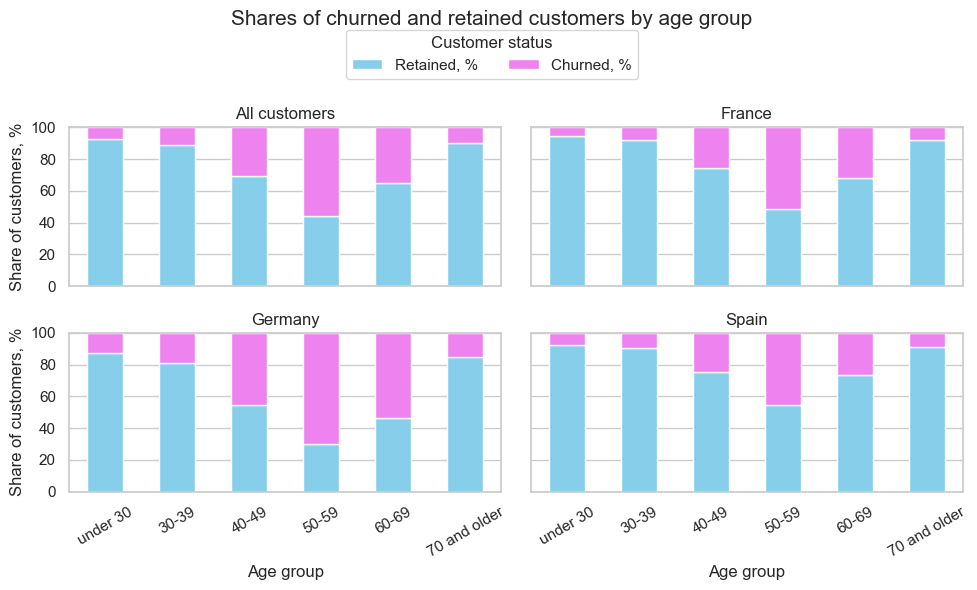

In [91]:
# Preserve the natural order of age groups in tables and charts
age_group_order = [
    'under 30',
    '30-39',
    '40-49',
    '50-59',
    '60-69',
    '70 and older'
]


# Calculate retained and churned shares within each age group
def calculate_age_status_share(data, sample_name):
    age_share = pd.crosstab(
        data['age_group'],
        data['exited'],
        normalize='index'
    ).reindex(
        index=age_group_order,
        columns=[0, 1],
        fill_value=0
    ).mul(100)

    age_share = age_share.rename(
        columns={
            0: 'Retained, %',
            1: 'Churned, %'
        }
    )

    age_share['Number of customers'] = (
        data['age_group']
        .value_counts()
        .reindex(age_group_order, fill_value=0)
    )

    age_share = (
        age_share
        .round(2)
        .reset_index()
        .rename(
            columns={
                'age_group': 'Age group'
            }
        )
    )

    age_share.insert(
        0,
        'Sample',
        sample_name
    )

    return age_share


# Apply the age-group calculation to the full sample and each country
age_group_status_share = pd.concat(
    [
        calculate_age_status_share(
            data_clients_new,
            'All customers'
        ),
        calculate_age_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'France'
            ],
            'France'
        ),
        calculate_age_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Germany'
            ],
            'Germany'
        ),
        calculate_age_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

display(
    age_group_status_share.set_index(
        ['Sample', 'Age group']
    )
)


# Compare age–churn patterns across the full sample and countries
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 6),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    sample_data = (
        age_group_status_share[
            age_group_status_share['Sample'] == sample_name
        ]
        .set_index('Age group')
        .reindex(age_group_order)
    )

    sample_data[
        ['Retained, %', 'Churned, %']
    ].plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['skyblue', 'violet'],
        legend=False
    )

    ax.set_title(sample_name)
    ax.set_xlabel('Age group')
    ax.set_ylabel('Share of customers, %')
    ax.set_ylim(0, 100)
    ax.tick_params(
        axis='x',
        rotation=30
    )

# Add one shared legend for all subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Customer status',
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    'Shares of churned and retained customers '
    'by age group',
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)
plt.show()

**Age (`age`) — Phi_K = 0.487**

**Full dataset.** Age has a pronounced nonlinear relationship with churn. The churn rate rises from **7.56%** among customers under **30** to a maximum of **56.04%** among customers aged **50–59**, then falls to **35.20%** among those aged **60–69** and **9.93%** among customers aged **70 or older**. The **churn rate** therefore resembles an **inverted U-shaped relationship**, while the **retention rate** resembles a **U-shaped relationship**. Customers aged **50–59** are the most likely to churn. Results for the older groups should be interpreted cautiously because of their smaller sample sizes, particularly the **70+** group, which contains only **151 customers**.

**Countries.** The inverted U-shaped pattern also persists in every country: churn rises through the **50–59** age group and then declines. In this group, **51.57%** of customers churned in France, **70.04%** in Germany, and **45.71%** in Spain. Germany has higher churn across all age groups and the strongest age–churn relationship, with Phi_K = **0.561**. Results for groups older than 60 should be interpreted cautiously because of their smaller sizes.

**Relationship between `exited` and `is_active_member`**

exited                         Retained, %  Churned, %  Number of customers
Sample        Activity status                                              
All customers Inactive               73.15       26.85                 4849
              Active                 85.73       14.27                 5151
France        Inactive               78.87       21.13                 2423
              Active                 88.50       11.50                 2591
Germany       Inactive               58.92       41.08                 1261
              Active                 76.28       23.72                 1248
Spain         Inactive               76.65       23.35                 1165
              Active                 89.25       10.75                 1312

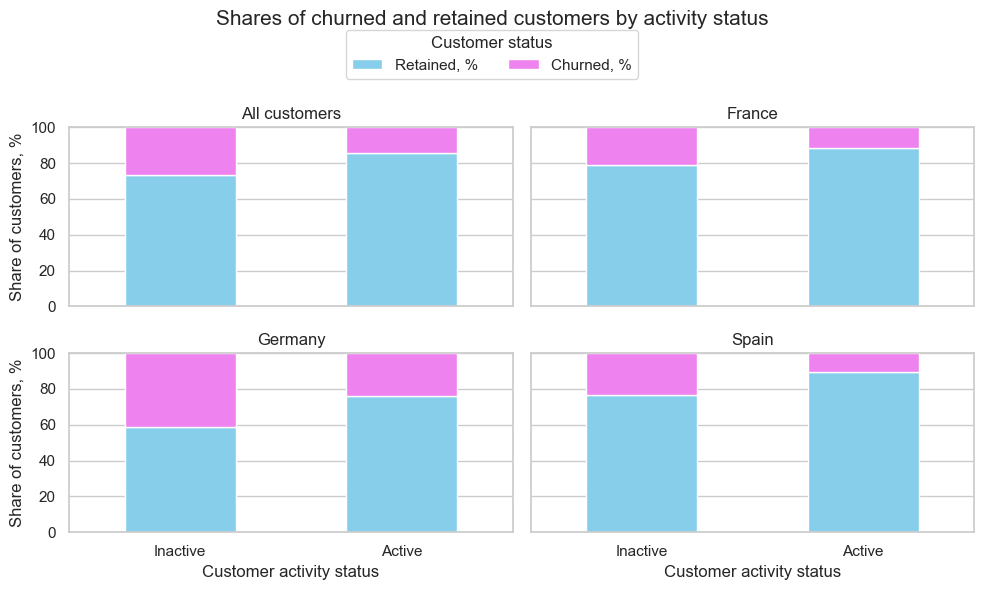

In [92]:
# Display inactive customers before active customers
activity_order = ['Inactive', 'Active']

# Calculate retained and churned shares for each activity status
def calculate_activity_status_share(data, sample_name):
    activity_share = pd.crosstab(
        data['is_active_member'],
        data['exited'],
        normalize='index'
    ).reindex(
        index=[0, 1],
        columns=[0, 1],
        fill_value=0
    ).mul(100)

    activity_share = activity_share.rename(
        columns={
            0: 'Retained, %',
            1: 'Churned, %'
        },
        index={
            0: 'Inactive',
            1: 'Active'
        }
    )

    activity_share['Number of customers'] = (
        data['is_active_member']
        .value_counts()
        .reindex([0, 1], fill_value=0)
        .rename(
            index={
                0: 'Inactive',
                1: 'Active'
            }
        )
    )

    activity_share = (
        activity_share
        .round(2)
        .reset_index()
        .rename(
            columns={
                'is_active_member': 'Activity status'
            }
        )
    )

    activity_share.insert(
        0,
        'Sample',
        sample_name
    )

    return activity_share


# Apply the activity-status calculation to the full sample and each country
is_active_member_status_share = pd.concat(
    [
        calculate_activity_status_share(
            data_clients_new,
            'All customers'
        ),
        calculate_activity_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'France'
            ],
            'France'
        ),
        calculate_activity_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Germany'
            ],
            'Germany'
        ),
        calculate_activity_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

display(
    is_active_member_status_share.set_index(
        ['Sample', 'Activity status']
    )
)


# Compare activity–churn patterns across the full sample and countries
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 6),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    sample_data = (
        is_active_member_status_share[
            is_active_member_status_share['Sample']
            == sample_name
        ]
        .set_index('Activity status')
        .reindex(activity_order)
    )

    sample_data[
        ['Retained, %', 'Churned, %']
    ].plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['skyblue', 'violet'],
        legend=False
    )

    ax.set_title(sample_name)
    ax.set_xlabel('Customer activity status')
    ax.set_ylabel('Share of customers, %')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0)

# Add one shared legend for all subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Customer status',
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    'Shares of churned and retained customers '
    'by activity status',
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)
plt.show()

**Activity (`is_active_member`) — Phi_K = 0.242.**

**Full dataset.** The churn rate is **26.85%** among inactive customers and **14.27%** among active customers. Active customers in this sample therefore leave the bank considerably less often.

**Countries.** Active customers churn less often in every country. The active versus inactive churn rates are **11.50% vs. 21.13%** in France, **23.72% vs. 41.08%** in Germany, and **10.75% vs. 23.35%** in Spain. The largest difference occurs in Germany at **17.36 percentage points**, consistent with the country's highest Phi_K of **0.284**.

**Relationship between `exited` and `balance`**

exited                                  Retained, %  Churned, %  \
Sample        Balance group, thousands                            
All customers 0                               86.18       13.82   
              1-24                            33.33       66.67   
              25-49                           68.12       31.88   
              50-74                           78.51       21.49   
              75-99                           80.60       19.40   
              100-124                         73.02       26.98   
              125-149                         75.65       24.35   
              150-174                         78.86       21.14   
              175-199                         75.13       24.87   
              200-224                         46.88       53.12   
              225-251                          0.00      100.00   
France        0                               86.06       13.94   
              1-24                            25.00       75.00   
              25-49                           54.05       45.95   
              50-74                           77.25       22.75   
              75-99                           85.00       15.00   
              100-124                         84.60       15.40   
              125-149                         83.10       16.90   
              150-174                         79.81       20.19   
              175-199                         68.69       31.31   
              200-224                         40.00       60.00   
              225-251                          0.00      100.00   
Germany       25-49                          100.00        0.00   
              50-74                           92.52        7.48   
              75-99                           76.02       23.98   
              100-124                         57.83       42.17   
              125-149                         64.75       35.25   
              150-174                         77.04       22.96   
              175-199                         98.04        1.96   
              200-224                        100.00        0.00   
Spain         0                               86.41       13.59   
              1-24                            50.00       50.00   
              25-49                           61.54       38.46   
              50-74                           61.33       38.67   
              75-99                           79.85       20.15   
              100-124                         86.39       13.61   
              125-149                         84.06       15.94   
              150-174                         79.88       20.12   
              175-199                         63.83       36.17   
              200-224                         27.27       72.73   
              225-251                          0.00      100.00   

exited                                  Number of customers  
Sample        Balance group, thousands                       
All customers 0                                        3617  
              1-24                                        6  
              25-49                                      69  
              50-74                                     349  
              75-99                                    1160  
              100-124                                  2068  
              125-149                                  1762  
              150-174                                   738  
              175-199                                   197  
              200-224                                    32  
              225-251                                     2  
France        0                                        2418  
              1-24                                        4  
              25-49                                      37  
              50-74                                     167  
              75-99                                     480  
  

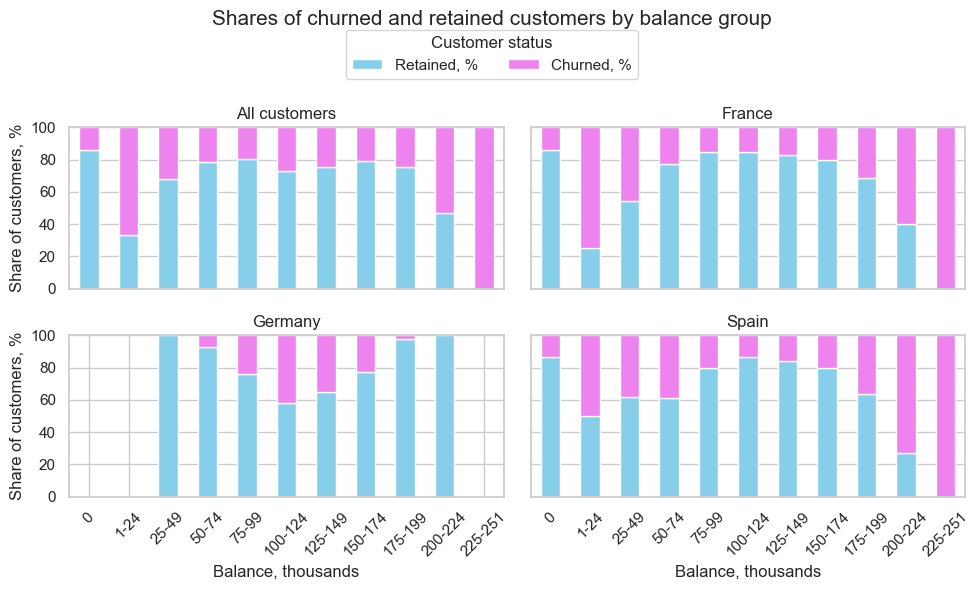

In [93]:
# Preserve the ascending order of balance intervals
balance_group_order = [
    '0',
    '1-24',
    '25-49',
    '50-74',
    '75-99',
    '100-124',
    '125-149',
    '150-174',
    '175-199',
    '200-224',
    '225-251'
]


# Calculate retained and churned shares within each balance interval
def calculate_balance_status_share(data, sample_name):
    balance_share = pd.crosstab(
        data['balance_group'],
        data['exited'],
        normalize='index'
    ).reindex(
        columns=[0, 1],
        fill_value=0
    ).mul(100)

    balance_share = balance_share.rename(
        columns={
            0: 'Retained, %',
            1: 'Churned, %'
        }
    )

    balance_share['Number of customers'] = (
        data['balance_group']
        .value_counts()
        .reindex(balance_share.index, fill_value=0)
    )

    balance_share = (
        balance_share
        .round(2)
        .reset_index()
        .rename(
            columns={
                'balance_group': 'Balance group, thousands'
            }
        )
    )

    balance_share.insert(
        0,
        'Sample',
        sample_name
    )

    return balance_share


# Apply the balance-group calculation to the full sample and each country
balance_status_share = pd.concat(
    [
        calculate_balance_status_share(
            data_clients_new,
            'All customers'
        ),
        calculate_balance_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'France'
            ],
            'France'
        ),
        calculate_balance_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Germany'
            ],
            'Germany'
        ),
        calculate_balance_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

display(
    balance_status_share.set_index(
        ['Sample', 'Balance group, thousands']
    )
)


# Compare balance–churn patterns across the full sample and countries
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 6),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    sample_data = (
        balance_status_share[
            balance_status_share['Sample'] == sample_name
        ]
        .set_index('Balance group, thousands')
        .reindex(balance_group_order)
    )

    sample_data[
        ['Retained, %', 'Churned, %']
    ].plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['skyblue', 'violet'],
        legend=False
    )

    ax.set_title(sample_name)
    ax.set_xlabel('Balance, thousands')
    ax.set_ylabel('Share of customers, %')
    ax.set_ylim(0, 100)
    ax.tick_params(
        axis='x',
        rotation=45
    )

# Add one shared legend for all subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Customer status',
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    'Shares of churned and retained customers '
    'by balance group',
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)
plt.show()

**Balance (`balance`) — Phi_K = 0.183.**

**Full dataset.** The complete sample shows no single pronounced relationship between churn rate and balance. The aggregated distribution combines different country-level patterns and therefore partially smooths them. Customers with a zero balance stand out: their churn rate is **13.82%**, lower than in the main positive-balance groups. The extreme positive-balance intervals contain few observations, so their elevated churn rates are not stable.

**Countries.** The relationship differs across countries. Among positive-balance customers in France and Spain, the churn-rate distribution resembles a **U-shaped relationship**: churn declines from low to medium balances, reaches its lowest level at approximately **75,000–149,000**, and then begins to rise. The pattern is weaker in France than in Spain.

Germany shows an **inverted U-shaped relationship**: churn rises from **7.48%** in the 50,000–74,000 group to a maximum of **42.17%** in the 100,000–124,000 group, then gradually declines. This is consistent with Germany's higher Phi_K of **0.291**, compared with **0.173** in France and **0.237** in Spain.

The balance–churn relationship is therefore **nonlinear and region-dependent**. The extreme intervals should be interpreted cautiously because of their small sample sizes, while zero-balance customers should be considered separately.

**Relationship between `exited` and `gender`**

exited                Retained, %  Churned, %  Number of customers
Sample        Gender                                              
All customers Women         74.93       25.07                 4543
              Men           83.54       16.46                 5457
France        Women         79.66       20.34                 2261
              Men           87.29       12.71                 2753
Germany       Women         62.45       37.55                 1193
              Men           72.19       27.81                 1316
Spain         Women         78.79       21.21                 1089
              Men           86.89       13.11                 1388

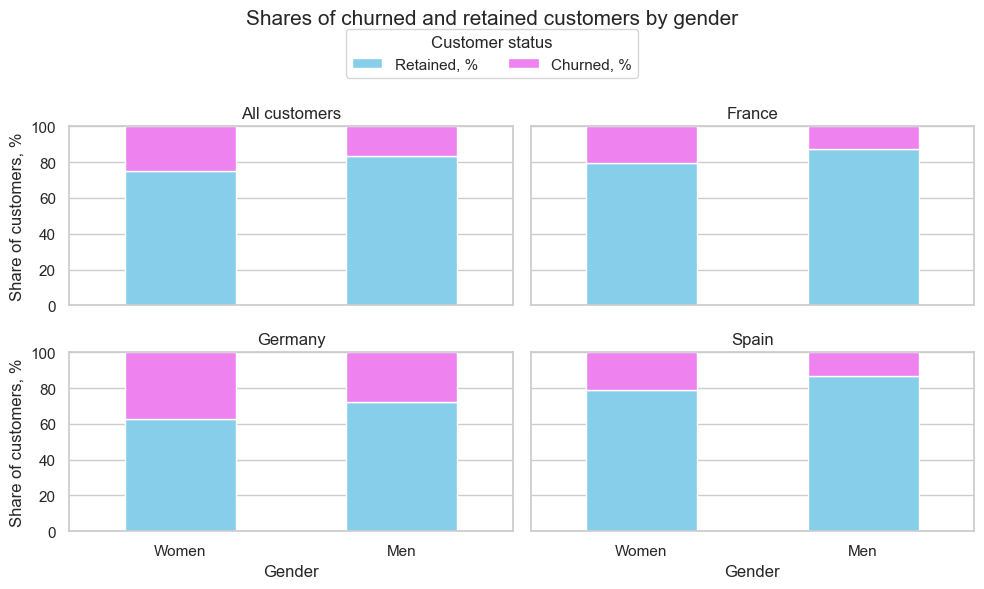

In [94]:
# Use a consistent gender order in tables and charts
gender_order = [
    'Women',
    'Men'
]


# Calculate retained and churned shares for women and men
def calculate_gender_status_share(data, sample_name):
    gender_share = pd.crosstab(
        data['gender'],
        data['exited'],
        normalize='index'
    ).reindex(
        index=['Female', 'Male'],
        columns=[0, 1],
        fill_value=0
    ).mul(100)

    gender_share = gender_share.rename(
        columns={
            0: 'Retained, %',
            1: 'Churned, %'
        },
        index={
            'Female': 'Women',
            'Male': 'Men'
        }
    )

    gender_share['Number of customers'] = (
        data['gender']
        .value_counts()
        .reindex(['Female', 'Male'], fill_value=0)
        .rename(
            index={
                'Female': 'Women',
                'Male': 'Men'
            }
        )
    )

    gender_share = (
        gender_share
        .round(2)
        .reset_index()
        .rename(
            columns={
                'gender': 'Gender'
            }
        )
    )

    gender_share.insert(
        0,
        'Sample',
        sample_name
    )

    return gender_share


# Apply the gender calculation to the full sample and each country
gender_status_share = pd.concat(
    [
        calculate_gender_status_share(
            data_clients_new,
            'All customers'
        ),
        calculate_gender_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'France'
            ],
            'France'
        ),
        calculate_gender_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Germany'
            ],
            'Germany'
        ),
        calculate_gender_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

display(
    gender_status_share.set_index(
        ['Sample', 'Gender']
    )
)


# Compare gender–churn patterns across the full sample and countries
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 6),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    sample_data = (
        gender_status_share[
            gender_status_share['Sample'] == sample_name
        ]
        .set_index('Gender')
        .reindex(gender_order)
    )

    sample_data[
        ['Retained, %', 'Churned, %']
    ].plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['skyblue', 'violet'],
        legend=False
    )

    ax.set_title(sample_name)
    ax.set_xlabel('Gender')
    ax.set_ylabel('Share of customers, %')
    ax.set_ylim(0, 100)
    ax.tick_params(
        axis='x',
        rotation=0
    )

# Add one shared legend for all subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Customer status',
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    'Shares of churned and retained customers '
    'by gender',
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)
plt.show()

**Gender (`gender`) — Phi_K = 0.165.**

**Full dataset.** The churn rate is **25.07%** among women and **16.46%** among men. Women churn more often in this sample.

**Countries.** Women churn more often than men in all three countries. The corresponding female and male churn rates are **20.34% and 12.71%** in France, **37.55% and 27.81%** in Germany, and **21.21% and 13.11%** in Spain. The difference persists across regions and is consistent with similar country-level Phi_K values of **0.158–0.164**. The higher rates for both gender groups in Germany reflect the country's higher overall churn rate.

**Relationship between `exited` and `credit_score`**

exited                            Retained, %  Churned, %  Number of customers
Sample        Credit score group                                              
All customers 350-399                    0.00      100.00                   19
              400-449                   74.70       25.30                  166
              450-499                   80.09       19.91                  447
              500-549                   77.97       22.03                  958
              550-599                   79.29       20.71                 1444
              600-649                   79.15       20.85                 1866
              650-699                   81.35       18.65                 1952
              700-749                   80.13       19.87                 1525
              750-799                   80.06       19.94                  968
              800-850                   80.46       19.54                  655
France        350-399                    0.00      100.00                    6
              400-449                   81.91       18.09                   94
              450-499                   81.94       18.06                  227
              500-549                   81.80       18.20                  500
              550-599                   84.23       15.77                  704
              600-649                   82.75       17.25                  910
              650-699                   84.38       15.62                 1005
              700-749                   85.42       14.58                  768
              750-799                   85.74       14.26                  477
              800-850                   84.52       15.48                  323
Germany       350-399                    0.00      100.00                    6
              400-449                   57.50       42.50                   40
              450-499                   69.84       30.16                  126
              500-549                   65.37       34.63                  231
              550-599                   65.55       34.45                  357
              600-649                   67.92       32.08                  480
              650-699                   71.52       28.48                  460
              700-749                   66.76       33.24                  370
              750-799                   65.78       34.22                  263
              800-850                   70.45       29.55                  176
Spain         350-399                    0.00      100.00                    7
              400-449                   75.00       25.00                   32
              450-499                   89.36       10.64                   94
              500-549                   82.38       17.62                  227
              550-599                   83.03       16.97                  383
              600-649                   83.61       16.39                  476
              650-699                   84.39       15.61                  487
              700-749                   82.43       17.57                  387
              750-799                   84.65       15.35                  228
              800-850                   83.33       16.67                  156

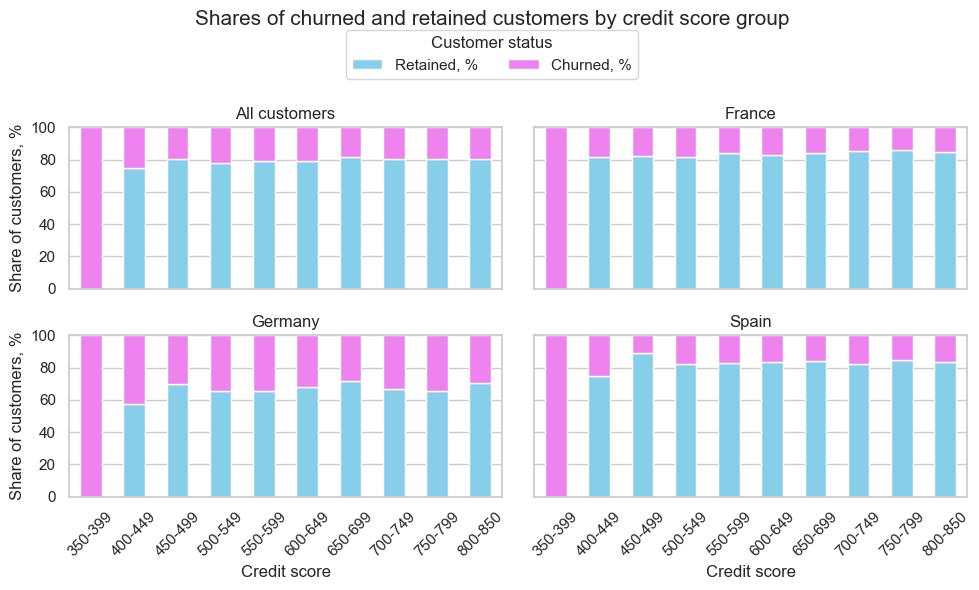

In [95]:
# Preserve the ascending order of credit score intervals
credit_score_group_order = [
    '350-399',
    '400-449',
    '450-499',
    '500-549',
    '550-599',
    '600-649',
    '650-699',
    '700-749',
    '750-799',
    '800-850'
]


# Calculate retained and churned shares within each credit score interval
def calculate_credit_score_status_share(data, sample_name):
    credit_score_share = pd.crosstab(
        data['credit_score_group'],
        data['exited'],
        normalize='index'
    ).reindex(
        columns=[0, 1],
        fill_value=0
    ).mul(100)

    credit_score_share = credit_score_share.rename(
        columns={
            0: 'Retained, %',
            1: 'Churned, %'
        }
    )

    credit_score_share['Number of customers'] = (
        data['credit_score_group']
        .value_counts()
        .reindex(credit_score_share.index, fill_value=0)
    )

    credit_score_share = (
        credit_score_share
        .round(2)
        .reset_index()
        .rename(
            columns={
                'credit_score_group':
                'Credit score group'
            }
        )
    )

    credit_score_share.insert(
        0,
        'Sample',
        sample_name
    )

    return credit_score_share


# Apply the credit-score calculation to the full sample and each country
credit_score_status_share = pd.concat(
    [
        calculate_credit_score_status_share(
            data_clients_new,
            'All customers'
        ),
        calculate_credit_score_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'France'
            ],
            'France'
        ),
        calculate_credit_score_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Germany'
            ],
            'Germany'
        ),
        calculate_credit_score_status_share(
            data_clients_new[
                data_clients_new['geography'] == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

display(
    credit_score_status_share.set_index(
        ['Sample', 'Credit score group']
    )
)


# Compare credit-score–churn patterns across the full sample and countries
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 6),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    sample_data = (
        credit_score_status_share[
            credit_score_status_share['Sample']
            == sample_name
        ]
        .set_index('Credit score group')
        .reindex(credit_score_group_order)
    )

    sample_data[
        ['Retained, %', 'Churned, %']
    ].plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['skyblue', 'violet'],
        legend=False
    )

    ax.set_title(sample_name)
    ax.set_xlabel('Credit score')
    ax.set_ylabel('Share of customers, %')
    ax.set_ylim(0, 100)
    ax.tick_params(
        axis='x',
        rotation=45
    )

# Add one shared legend for all subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Customer status',
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.96)
)

fig.suptitle(
    'Shares of churned and retained customers '
    'by credit score group',
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)
plt.show()

**Credit score (`credit_score`) — Phi_K = 0.112.**

**Full dataset.** In most sufficiently represented groups, churn rates are similar and fall approximately between **19% and 22%**. The result for the **350–399** group is unstable because it contains only **19 customers**. No pronounced relationship between credit score and churn was identified.

**Countries.** Within each country, churn rates vary only slightly across sufficiently represented score groups and show no stable increasing or decreasing pattern. They generally fall within **14–18%** in France, **28–34%** in Germany, and **15–18%** in Spain. Germany's higher values across almost all score groups primarily reflect its higher overall churn rate. Results for groups with scores below **450** are unstable because of their small sizes.

**Relationship between `exited` and `geography`**

,"Retained, %","Churned, %",Number of customers
Sample,,,
All customers,79.63,20.37,10000
France,83.85,16.15,5014
Germany,67.56,32.44,2509
Spain,83.33,16.67,2477


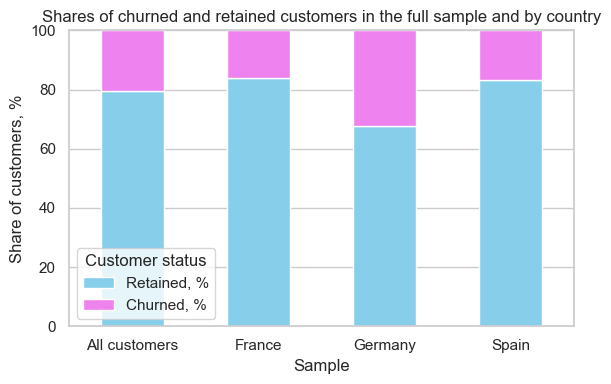

In [96]:
# Define the full sample and country subsets used in the comparison
geography_samples = {
    'All customers': data_clients_new,
    'France': data_clients_new[
        data_clients_new['geography'] == 'France'
    ],
    'Germany': data_clients_new[
        data_clients_new['geography'] == 'Germany'
    ],
    'Spain': data_clients_new[
        data_clients_new['geography'] == 'Spain'
    ]
}

geography_status_rows = []

# Calculate retained and churned shares for the full sample and each country
for sample_name, sample_data in geography_samples.items():
    status_share = (
        sample_data['exited']
        .value_counts(normalize=True)
        .reindex([0, 1], fill_value=0)
        .mul(100)
    )

    geography_status_rows.append({
        'Sample': sample_name,
        'Retained, %': status_share.loc[0],
        'Churned, %': status_share.loc[1],
        'Number of customers': len(sample_data)
    })

geography_status_share = (
    pd.DataFrame(geography_status_rows)
    .set_index('Sample')
    .round(2)
)

display(geography_status_share)


# Visualize differences in churn rates between countries
geography_status_share[
    ['Retained, %', 'Churned, %']
].plot(
    kind='bar',
    stacked=True,
    figsize=(6, 4),
    color=['skyblue', 'violet']
)

plt.title(
    'Shares of churned and retained customers '
    'in the full sample and by country'
)
plt.xlabel('Sample')
plt.ylabel('Share of customers, %')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Customer status')
plt.tight_layout()
plt.show()

**Geography (`geography`) — Phi_K = 0.105.**

**Full dataset.** The overall churn rate is **20.37%**.

**Countries.** The churn rate in Germany is **32.44%**, almost twice the rates in France (**16.15%**) and Spain (**16.67%**).

<a id="section-2-4-3"></a>

#### Relationships Between Predictor Features

Now examine relationships among the predictor features, excluding the target:

In [97]:
strong_associations.query("feature_2 != 'exited'").round(3)

,feature_1,feature_2,All customers,France,Germany,Spain
0,credit_score,credit_score_group,1.000,NaN,NaN,NaN
1,balance,balance_group,0.995,NaN,NaN,NaN
2,estimated_salary,estimated_salary_group,0.949,NaN,NaN,NaN
3,age,age_group,0.940,NaN,NaN,NaN
7,geography,balance_group,0.473,NaN,NaN,NaN
8,geography,balance,0.464,NaN,NaN,NaN
9,balance,num_of_products,0.371,0.446,0.043,0.448
10,balance_group,num_of_products,0.368,NaN,NaN,NaN
13,age,is_active_member,0.189,0.206,0.130,0.208
14,age_group,is_active_member,0.197,NaN,NaN,NaN


**Geography and balance**

To investigate the relationship, calculate the median and mean values within the relevant categories. The median is resistant to extreme values and allows the typical level in each group to be compared. Box plots will also be used.

'Mean and median balance for the full sample and by country:'

,sample,mean_balance,median_balance,client_count
0,All customers,76485.89,97198.54,10000
1,France,62092.64,62153.50,5014
2,Germany,119730.12,119703.10,2509
3,Spain,61818.15,61710.44,2477


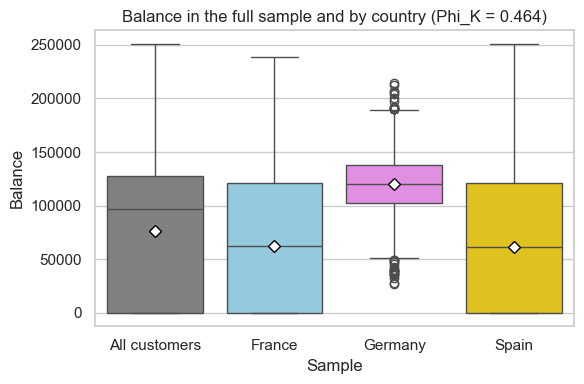

In [98]:
# Calculate balance statistics for the full sample
overall_balance_summary = pd.DataFrame({
    'sample': ['All customers'],
    'mean_balance': [
        data_clients_new['balance'].mean()
    ],
    'median_balance': [
        data_clients_new['balance'].median()
    ],
    'client_count': [
        data_clients_new['balance'].size
    ]
})


# Calculate balance statistics separately for each country
geography_balance_summary = (
    data_clients_new
    .groupby(
        'geography',
        as_index=False
    )
    .agg(
        mean_balance=('balance', 'mean'),
        median_balance=('balance', 'median'),
        client_count=('balance', 'size')
    )
    .rename(
        columns={
            'geography': 'sample'
        }
    )
)


# Combine overall and country-level balance statistics
geography_balance_summary = pd.concat(
    [
        overall_balance_summary,
        geography_balance_summary
    ],
    ignore_index=True
)

display(
    'Mean and median balance '
    'for the full sample and by country:',
    geography_balance_summary.round(2)
)


# Rename the geography column for the combined visualization
relationships_by_country = (
    data_clients_new[
        ['balance', 'geography']
    ]
    .rename(
        columns={
            'geography': 'sample'
        }
    )
)


# Create a matching block for the full-sample balance distribution
relationships_overall = (
    data_clients_new[
        ['balance']
    ]
    .assign(
        sample='All customers'
    )
)


# Combine overall and country-level observations for visualization
relationships_data = pd.concat(
    [
        relationships_overall,
        relationships_by_country
    ],
    ignore_index=True
)


# Define the display order and colors of the samples
sample_order = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

sample_palette = {
    'All customers': 'gray',
    'France': 'skyblue',
    'Germany': 'violet',
    'Spain': 'gold'
}

mean_properties = {
    'marker': 'D',
    'markerfacecolor': 'white',
    'markeredgecolor': 'black',
    'markersize': 6
}


# Compare balance distributions in the full sample and across countries
plt.figure(figsize=(6, 4))

ax = sns.boxplot(
    data=relationships_data,
    x='sample',
    y='balance',
    hue='sample',
    order=sample_order,
    hue_order=sample_order,
    palette=sample_palette,
    dodge=False,
    legend=False,
    showmeans=True,
    meanprops=mean_properties
)

ax.set_title(
    'Balance in the full sample and by country '
    '(Phi_K = 0.464)'
)
ax.set_xlabel('Sample')
ax.set_ylabel('Balance')

plt.tight_layout()
plt.show()

**Geography and balance — Phi_K = 0.464.**

The median balance of German customers is approximately **119,700**, compared with approximately **62,000** for customers in France and Spain. The means show a similar difference: **119,700** in Germany versus **62,100** in France and **61,800** in Spain. Much of this difference reflects the fact that almost half of customers in France and Spain have zero balances, whereas zero balances are absent among German customers. Within each country, the mean and median are almost identical, while they differ noticeably in the full sample at **76,500** and **97,200**, respectively. This reflects the heterogeneity of balance distributions across countries.

**Balance and number of products**

Mean balance  Median balance  \
Sample        Number of products                                 
All customers 1                       98551.87       111886.04   
              2                       51879.15            0.00   
              3                       75458.33        95973.94   
              4                       93733.14       116808.20   
France        1                       90977.88       106886.88   
              2                       31828.10            0.00   
              3                       50071.82            0.00   
              4                       71362.73        75150.34   
Germany       1                      119868.33       119961.48   
              2                      119341.25       119453.25   
              3                      121572.67       121012.65   
              4                      121442.31       118426.09   
Spain         1                       90595.37       105770.14   
              2                       32690.85            0.00   
              3                       48385.90            0.00   
              4                       91407.65       117294.12   

                                  Number of customers  
Sample        Number of products                       
All customers 1                                  5084  
              2                                  4590  
              3                                   266  
              4                                    60  
France        1                                  2514  
              2                                  2367  
              3                                   104  
              4                                    29  
Germany       1                                  1349  
              2                                  1040  
              3                                    96  
              4                                    24  
Spain         1                                  1221  
              2                                  1183  
              3                                    66  
              4                                     7

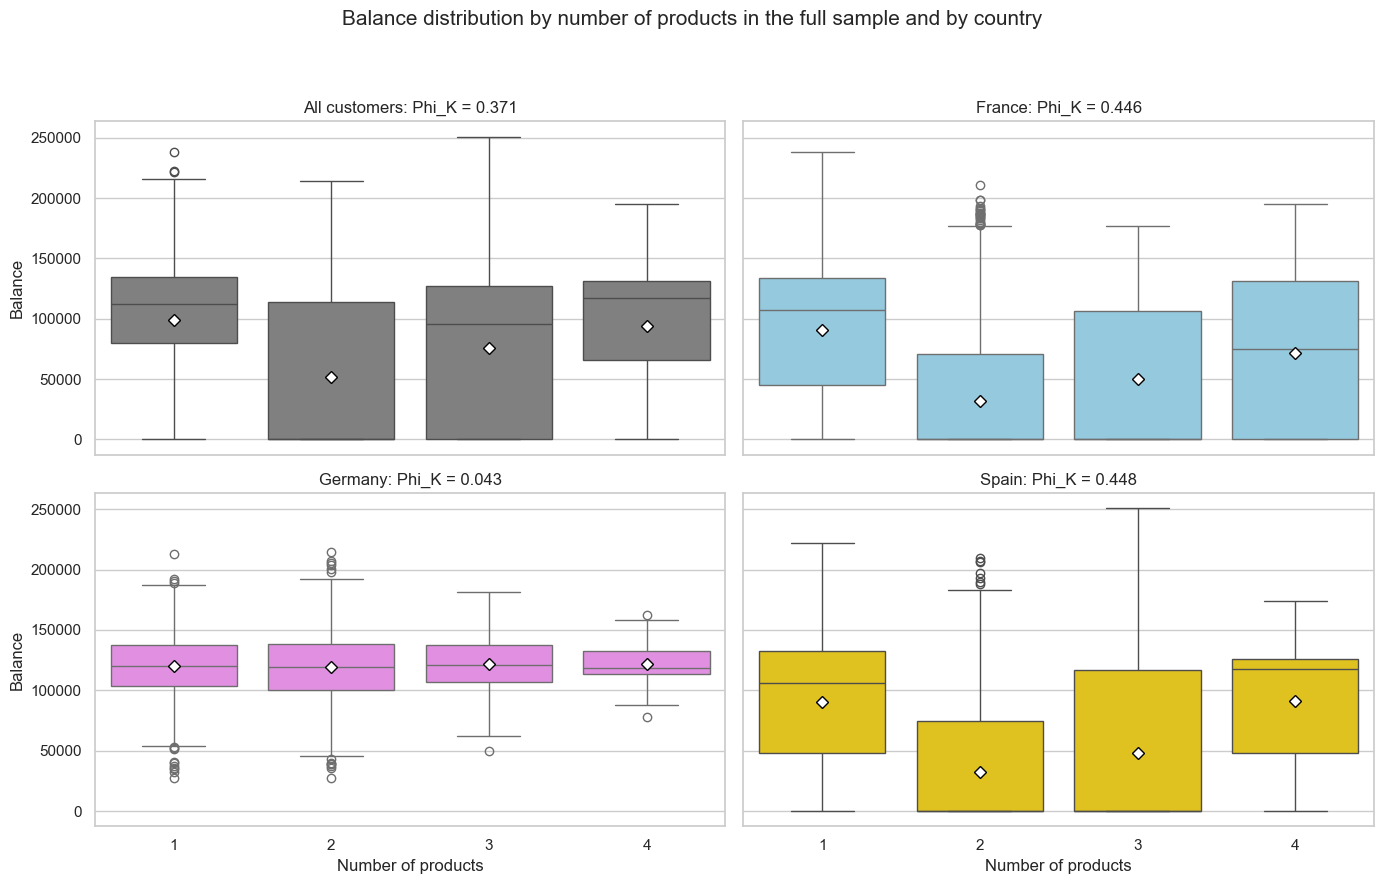

In [99]:
# Select variables needed to analyze balance by product count and country
products_balance_analysis = data_clients_new[
    [
        'num_of_products',
        'balance',
        'geography'
    ]
].copy()

# Calculate mean balance, median balance, and group size by number of products
def calculate_products_balance_summary(
    data,
    sample_name
):
    summary = (
        data
        .groupby(
            'num_of_products',
            as_index=False
        )
        .agg(
            mean_balance=('balance', 'mean'),
            median_balance=('balance', 'median'),
            client_count=('balance', 'size')
        )
    )

    summary.insert(
        0,
        'Sample',
        sample_name
    )

    return summary


# Apply the summary calculation to the full sample and each country
products_balance_summary = pd.concat(
    [
        calculate_products_balance_summary(
            products_balance_analysis,
            'All customers'
        ),
        calculate_products_balance_summary(
            products_balance_analysis[
                products_balance_analysis['geography']
                == 'France'
            ],
            'France'
        ),
        calculate_products_balance_summary(
            products_balance_analysis[
                products_balance_analysis['geography']
                == 'Germany'
            ],
            'Germany'
        ),
        calculate_products_balance_summary(
            products_balance_analysis[
                products_balance_analysis['geography']
                == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

products_balance_summary = (
    products_balance_summary
    .rename(
        columns={
            'num_of_products': 'Number of products',
            'mean_balance': 'Mean balance',
            'median_balance': 'Median balance',
            'client_count': 'Number of customers'
        }
    )
    .round(2)
)

display(
    products_balance_summary.set_index(
        ['Sample', 'Number of products']
    )
)


# Compare balance distributions across product counts and countries
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

sample_colors = {
    'All customers': 'gray',
    'France': 'skyblue',
    'Germany': 'violet',
    'Spain': 'gold'
}

products_balance_phik = {
    'All customers': 0.371,
    'France': 0.446,
    'Germany': 0.043,
    'Spain': 0.448
}

mean_properties = {
    'marker': 'D',
    'markerfacecolor': 'white',
    'markeredgecolor': 'black',
    'markersize': 6
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 9),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    if sample_name == 'All customers':
        sample_data = products_balance_analysis
    else:
        sample_data = products_balance_analysis[
            products_balance_analysis['geography']
            == sample_name
        ]

    sns.boxplot(
        data=sample_data,
        x='num_of_products',
        y='balance',
        order=[1, 2, 3, 4],
        color=sample_colors[sample_name],
        showmeans=True,
        meanprops=mean_properties,
        ax=ax
    )

    ax.set_title(
        f'{sample_name}: Phi_K = '
        f'{products_balance_phik[sample_name]:.3f}'
    )
    ax.set_xlabel('Number of products')
    ax.set_ylabel('Balance')
    ax.tick_params(axis='x', rotation=0)

fig.suptitle(
    'Balance distribution by number of products '
    'in the full sample and by country',
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)
plt.show()

num_of_products                         1 product, %  2 products, %  \
Sample        Balance group, thousands                                
All customers 0                                25.02          71.88   
              1-24                             66.67          33.33   
              25-49                            65.22          26.09   
              50-74                            62.18          34.96   
              75-99                            65.17          32.24   
              100-124                          65.86          30.51   
              125-149                          66.69          29.85   
              150-174                          64.91          31.57   
              175-199                          59.39          38.07   
              200-224                          71.88          28.12   
              225-251                          50.00           0.00   
France        0                                25.23          71.92   
              1-24                             75.00          25.00   
              25-49                            75.68          10.81   
              50-74                            69.46          27.54   
              75-99                            73.12          24.79   
              100-124                          72.98          24.54   
              125-149                          75.92          21.83   
              150-174                          71.29          26.81   
              175-199                          67.68          29.29   
              200-224                          93.33           6.67   
              225-251                         100.00           0.00   
Germany       0                                 0.00           0.00   
              1-24                              0.00           0.00   
              25-49                            36.84          57.89   
              50-74                            46.73          50.47   
              75-99                            50.60          46.04   
              100-124                          56.74          37.72   
              125-149                          55.33          40.16   
              150-174                          51.75          41.63   
              175-199                          39.22          58.82   
              200-224                          16.67          83.33   
              225-251                           0.00           0.00   
Spain         0                                24.60          71.81   
              1-24                             50.00          50.00   
              25-49                            76.92          23.08   
              50-74                            68.00          29.33   
              75-99                            73.76          23.95   
              100-124                          73.56          25.13   
              125-149                          72.19          24.06   
              150-174                          73.17          25.00   
              175-199                          63.83          34.04   
              200-224                          72.73          27.27   
              225-251                           0.00           0.00   

num_of_products                         3 products, %  4 products, %  \
Sample        Balance group, thousands                                 
All customers 0                                  2.71           0.39   
              1-24                               0.00           0.00   
              25-49                              7.25           1.45   
              50-74                              2.58           0.29   
              75-99                              2.16           0.43   
              100-124                            2.76           0.87   
              125-149                            2.61           0.85   
              150-174                            2.85           0.68   
             

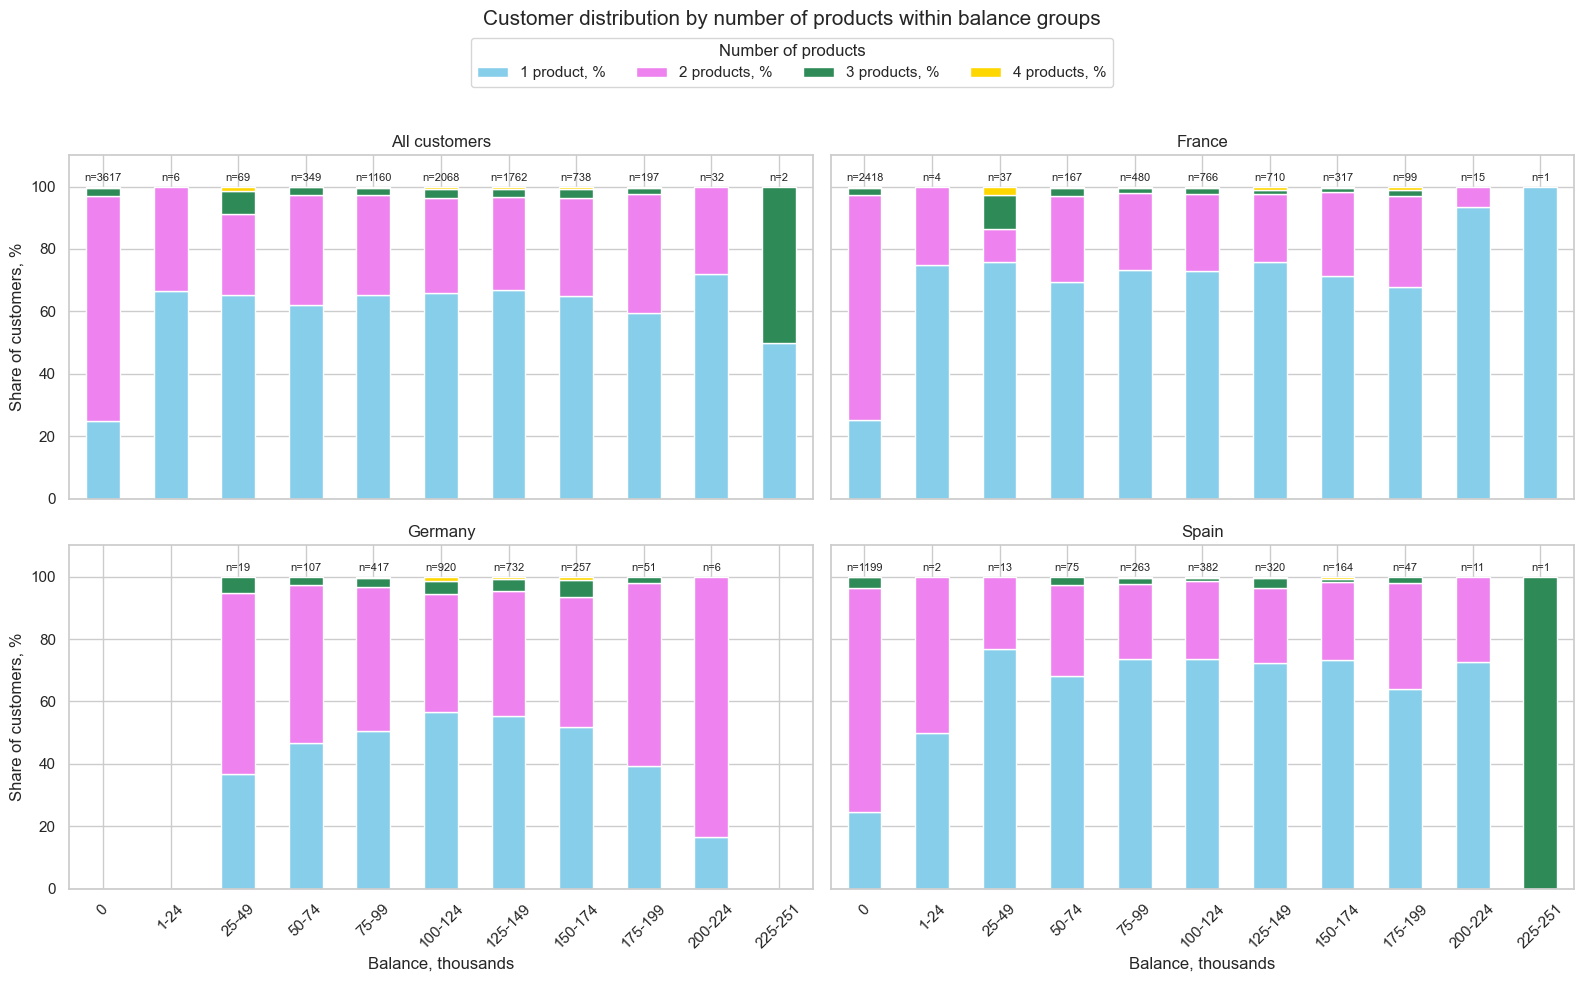

In [100]:
# Select variables needed to compare product mix across balance groups
products_balance_group_analysis = data_clients_new[
    [
        'balance_group',
        'num_of_products',
        'geography'
    ]
].copy()

# Preserve the ascending order of balance intervals
balance_group_order = [
    '0',
    '1-24',
    '25-49',
    '50-74',
    '75-99',
    '100-124',
    '125-149',
    '150-174',
    '175-199',
    '200-224',
    '225-251'
]

# Preserve the natural order of product-count categories
products_order = [1, 2, 3, 4]

products_columns = [
    '1 product, %',
    '2 products, %',
    '3 products, %',
    '4 products, %'
]


# Calculate product-count shares within each balance interval
def calculate_products_balance_share(
    data,
    sample_name
):
    products_share = pd.crosstab(
        data['balance_group'],
        data['num_of_products'],
        normalize='index'
    ).reindex(
        index=balance_group_order,
        columns=products_order,
        fill_value=0
    ).mul(100)

    products_share = products_share.rename(
        columns={
            1: '1 product, %',
            2: '2 products, %',
            3: '3 products, %',
            4: '4 products, %'
        }
    )

    # Store group sizes to identify percentages based on small samples
    products_share['Number of customers'] = (
        data['balance_group']
        .value_counts()
        .reindex(
            balance_group_order,
            fill_value=0
        )
    )

    products_share = (
        products_share
        .round(2)
        .reset_index()
        .rename(
            columns={
                'balance_group': 'Balance group, thousands'
            }
        )
    )

    products_share.insert(
        0,
        'Sample',
        sample_name
    )

    return products_share


# Apply the calculation to the full sample and each country
products_balance_group_share = pd.concat(
    [
        calculate_products_balance_share(
            products_balance_group_analysis,
            'All customers'
        ),
        calculate_products_balance_share(
            products_balance_group_analysis[
                products_balance_group_analysis['geography']
                == 'France'
            ],
            'France'
        ),
        calculate_products_balance_share(
            products_balance_group_analysis[
                products_balance_group_analysis['geography']
                == 'Germany'
            ],
            'Germany'
        ),
        calculate_products_balance_share(
            products_balance_group_analysis[
                products_balance_group_analysis['geography']
                == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

display(
    products_balance_group_share.set_index(
        ['Sample', 'Balance group, thousands']
    )
)


# Compare product mix across balance groups and countries
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

product_colors = [
    'skyblue',
    'violet',
    'seagreen',
    'gold'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    segment = (
        products_balance_group_share[
            products_balance_group_share['Sample']
            == sample_name
        ]
        .set_index('Balance group, thousands')
        .reindex(balance_group_order)
    )

    segment[
        products_columns
    ].plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=product_colors,
        legend=False
    )

    # Show the number of customers behind each percentage distribution
    for position, count in enumerate(
        segment['Number of customers']
    ):
        if count > 0:
            ax.text(
                position,
                101,
                f'n={int(count)}',
                ha='center',
                va='bottom',
                fontsize=8
            )

    ax.set_title(sample_name)
    ax.set_xlabel('Balance, thousands')
    ax.set_ylabel('Share of customers, %')
    ax.set_ylim(0, 110)
    ax.tick_params(
        axis='x',
        rotation=45
    )

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Number of products',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.96),
    ncol=4
)

fig.suptitle(
    'Customer distribution by number of products '
    'within balance groups',
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)
plt.show()

**Balance and number of products — Phi_K = 0.371.**

**Full dataset.** The median balance is **0** for customers with two products, compared with approximately **111,900**, **96,000**, and **116,800** for customers with one, three, and four products. The relationship is therefore nonlinear: balance does not consistently increase or decrease as the number of products rises.

**Countries.** The pattern differs substantially. In France and Spain, the median balance is **0** for customers with two and three products, while it is approximately **106,900** and **105,800**, respectively, for customers with one product. The median balance rises again among customers with four products, reaching **75,200** in France and **117,300** in Spain. However, these groups contain only **29** and **7 customers**, so the results are unstable.

The balance-group distribution confirms this pattern. Among zero-balance customers in France and Spain, approximately **72%** use two products, whereas their share is generally much lower in the main positive-balance groups. The relationship in these countries is therefore largely driven by the concentration of two-product customers in the zero-balance group.

In Germany, mean and median balances vary little by number of products and remain approximately **118,000–122,000** across groups. This is consistent with country-level Phi_K values of approximately **0.45** in France and Spain and only **0.04** in Germany. The overall coefficient of **0.371** therefore mainly reflects the patterns in France and Spain and differences in customer-base structure across countries.

**Customer age and activity**

Analyze the relationship between age and customer activity by comparing the shares of active and inactive customers across age groups.

In [101]:
# Select variables needed to analyze activity status by age group and country
activity_age_group_analysis = data_clients_new[
    [
        'age_group',
        'is_active_member',
        'geography'
    ]
].copy()

# Preserve the natural order of age groups
age_group_order = [
    'under 30',
    '30-39',
    '40-49',
    '50-59',
    '60-69',
    '70 and older'
]


# Calculate active and inactive customer shares within each age group
def calculate_activity_age_share(data, sample_name):
    activity_share = pd.crosstab(
        data['age_group'],
        data['is_active_member'],
        normalize='index'
    ).reindex(
        index=age_group_order,
        columns=[0, 1],
        fill_value=0
    ).mul(100)

    activity_share = activity_share.rename(
        columns={
            0: 'Inactive, %',
            1: 'Active, %'
        }
    )

    # Store age-group sizes to support cautious interpretation of small groups
    activity_share['Number of customers'] = (
        data['age_group']
        .value_counts()
        .reindex(age_group_order, fill_value=0)
    )

    activity_share = (
        activity_share
        .round(2)
        .reset_index()
        .rename(
            columns={
                'age_group': 'Age group'
            }
        )
    )

    activity_share.insert(
        0,
        'Sample',
        sample_name
    )

    return activity_share


# Apply the activity-by-age calculation to the full sample and each country
activity_age_group_share = pd.concat(
    [
        calculate_activity_age_share(
            activity_age_group_analysis,
            'All customers'
        ),
        calculate_activity_age_share(
            activity_age_group_analysis[
                activity_age_group_analysis['geography']
                == 'France'
            ],
            'France'
        ),
        calculate_activity_age_share(
            activity_age_group_analysis[
                activity_age_group_analysis['geography']
                == 'Germany'
            ],
            'Germany'
        ),
        calculate_activity_age_share(
            activity_age_group_analysis[
                activity_age_group_analysis['geography']
                == 'Spain'
            ],
            'Spain'
        )
    ],
    ignore_index=True
)

display(
    activity_age_group_share.set_index(
        ['Sample', 'Age group']
    )
)

is_active_member            Inactive, %  Active, %  Number of customers
Sample        Age group                                                
All customers under 30            48.99      51.01                 1641
              30-39               49.82      50.18                 4346
              40-49               53.32      46.68                 2618
              50-59               42.92      57.08                  869
              60-69               25.07      74.93                  375
              70 and older        11.26      88.74                  151
France        under 30            49.31      50.69                  866
              30-39               50.71      49.29                 2250
              40-49               52.33      47.67                 1242
              50-59               39.79      60.21                  382
              60-69               23.98      76.02                  196
              70 and older         7.69      92.31                   78
Germany       under 30            49.46      50.54                  372
              30-39               48.24      51.76                  997
              40-49               55.95      44.05                  740
              50-59               52.71      47.29                  277
              60-69               33.33      66.67                   84
              70 and older        20.51      79.49                   39
Spain         under 30            47.89      52.11                  403
              30-39               49.41      50.59                 1099
              40-49               52.20      47.80                  636
              50-59               35.71      64.29                  210
              60-69               20.00      80.00                   95
              70 and older         8.82      91.18                   34

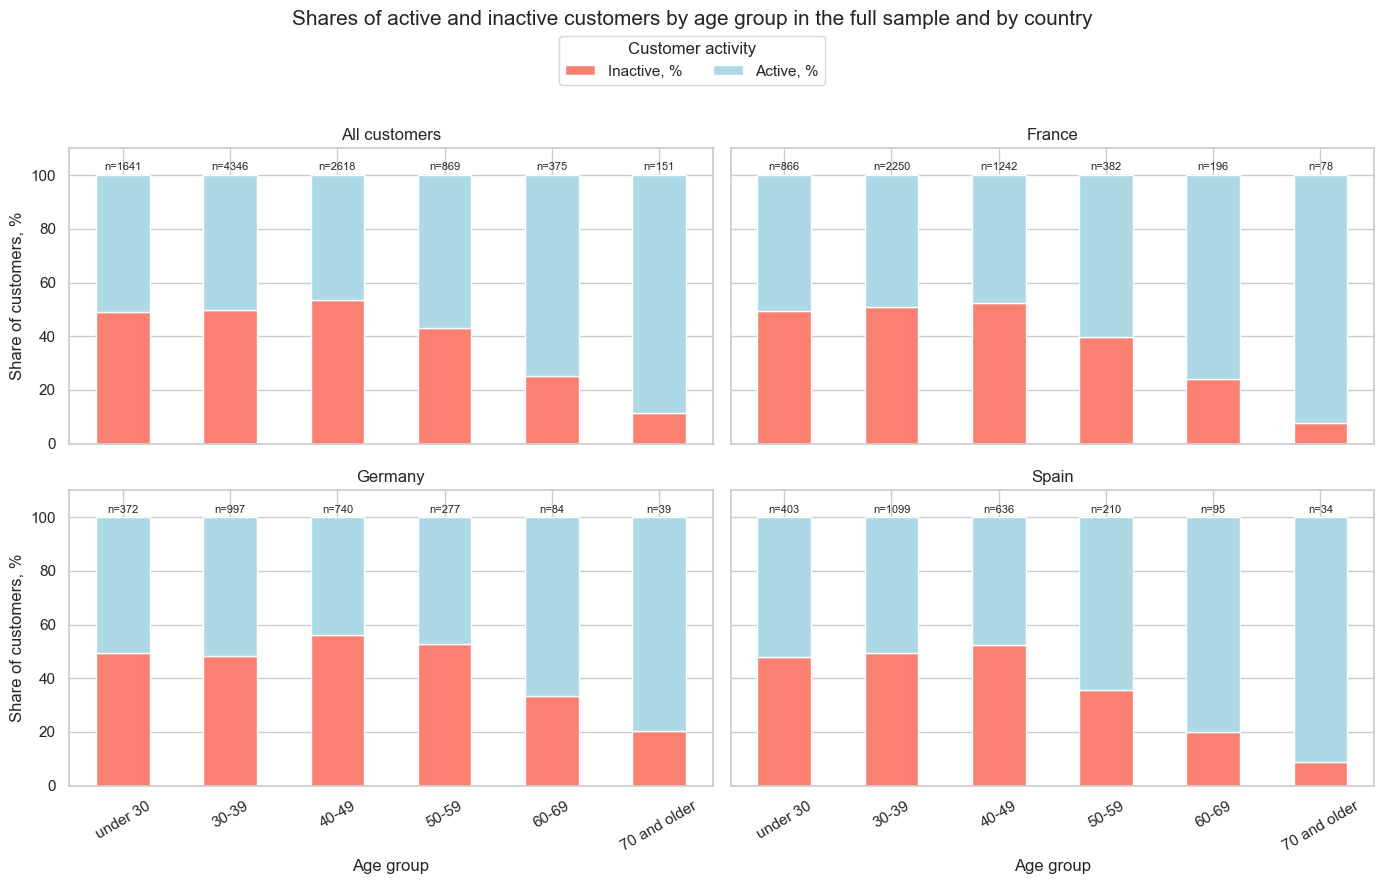

In [102]:
samples = [
    'All customers',
    'France',
    'Germany',
    'Spain'
]

# Compare age–activity patterns across the full sample and countries
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 9),
    sharex=True,
    sharey=True
)

for ax, sample_name in zip(axes.flat, samples):
    segment = (
        activity_age_group_share[
            activity_age_group_share['Sample']
            == sample_name
        ]
        .set_index('Age group')
        .reindex(age_group_order)
    )

    segment[
        ['Inactive, %', 'Active, %']
    ].plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['salmon', 'lightblue'],
        legend=False
    )

    # Show the number of customers represented by each stacked bar
    for position, count in enumerate(
        segment['Number of customers']
    ):
        ax.text(
            position,
            101,
            f'n={int(count)}',
            ha='center',
            va='bottom',
            fontsize=8
        )

    ax.set_title(sample_name)
    ax.set_xlabel('Age group')
    ax.set_ylabel('Share of customers, %')
    ax.set_ylim(0, 110)
    ax.tick_params(
        axis='x',
        rotation=30
    )

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Customer activity',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.96),
    ncol=2
)

fig.suptitle(
    'Shares of active and inactive customers '
    'by age group in the full sample and by country',
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)
plt.show()

**Age and activity (`age`, `is_active_member`) — Phi_K = 0.189.**

**Full dataset.** Among customers younger than 40, approximately **50–51%** are active. The share falls to **46.68%** among customers aged **40–49**, then rises to **57.08%** among those aged 50–59, **74.93%** among those aged 60–69, and **88.74%** among customers aged 70 or older. The relationship is nonlinear and broadly resembles a **J-shaped pattern**, with activity increasing noticeably among older age groups.

**Countries.** In France and Spain, the active share begins to rise noticeably after age 50. In France, it increases from **47.67%** among customers aged 40–49 to **60.21%**, **76.02%**, and **92.31%** in the 50–59, 60–69, and 70+ groups. The corresponding values in Spain are **47.80%**, **64.29%**, **80.00%**, and **91.18%**.

In Germany, the increase begins later. Active customers account for **44.05%** of the 40–49 group and **47.29%** of the 50–59 group, rising to **66.67%** among customers aged 60–69 and **79.49%** among those aged 70 or older. This is consistent with Germany's weaker Phi_K of **0.13**, compared with approximately **0.21** in France and Spain.

Activity therefore rises among older customers in every country, although the increase begins later and is weaker in Germany. The relationship is not solely caused by differences in the geographic structure of the full sample. Results for older groups should still be interpreted cautiously: the 70+ group contains **78 customers** in France, **39** in Germany, and **34** in Spain.

**Relationships between variables: conclusion**

Regional analysis shows that the main relationships between churn and number of products (**Phi_K = 0.565**), age (**0.487**), activity (**0.242**), and gender (**0.165**) persist across all three countries. The balance–churn relationship (**0.183** in the full sample) differs noticeably by country: Phi_K is **0.173** in France, **0.291** in Germany, and **0.237** in Spain. No stable relationship between churn and credit score was found, despite a weak association in the full sample (**Phi_K = 0.112**).

Among predictor features, the most noticeable full-sample relationships are geography and balance (**Phi_K = 0.464**), balance and number of products (**0.371**), and age and activity (**0.189**). Balance and number of products are almost unrelated in Germany (**0.04**) but noticeably associated in France and Spain (**approximately 0.45** in both). Age and activity are also less strongly associated in Germany (**0.13**) than in France and Spain (**approximately 0.21**). The weaker pairs in the overview table do not provide sufficient evidence of stable relationships.

All identified patterns are descriptive and do not in themselves establish causal relationships.

The analysis identified a substantial **target class imbalance**, **unequal representation of countries**, and **noticeable regional differences in relationships between individual features**.

To preserve the regional data structure and target distribution, the data split will use **joint stratification** by `exited` and `geography`. This preserves the country proportions, overall churn rate, and ratio of churned to retained customers within each country in every subset.

<a id="section-2-5"></a>

### Exploratory Data Analysis: Section Summary

**Statistical analysis completed:**

* The credit score distribution is close to bell-shaped, but has a pronounced peak at the upper boundary of the scale — **850 points**.
* The age distribution is right-skewed: middle-aged customers predominate in the sample.
* The balance distribution is heterogeneous because a substantial share of customers has a zero balance. Among positive values, most observations fall within the **50–150 thousand** range.
* Tenure and estimated salary are distributed uniformly or close to uniformly.
* Under the interquartile-range rule, low credit scores and ages above **62 years** were classified as potential outliers. These observations were examined and were not considered erroneous, so they were retained.

**Class and feature distributions analysed:**

* The target classes are imbalanced: **79.63%** of customers stayed and **20.37%** churned.
* France accounts for about **50%** of observations; Germany and Spain account for approximately **25%** each.
* Around **97%** of customers use one or two products.
* A credit card is held by **70.55%** of customers.
* Gender and activity status are relatively evenly represented.
* Estimated salary is distributed almost uniformly across the entire range.
* **36.17%** of customers have a zero balance.

During model training, only the class imbalance of the target variable `exited` will be addressed. An uneven distribution of individual predictors does not, by itself, require artificial balancing.

**Relationships between variables investigated:**

* The strongest associations with churn were found for number of products (**Phi_K = 0.565**) and age (**Phi_K = 0.487**). These remain the leading features in all three countries.
* The lowest churn rate is observed among customers with two products — **7.58%** in the full sample and **5.70–12.12%** by country. The groups with three and four products are small, so their high churn rates should be interpreted with caution.
* The churn rate reaches its maximum in the **50–59** age group: **51.57%** in France, **70.04%** in Germany, and **45.71%** in Spain.
* Active customers churn less often than inactive customers in every country. In the full sample, the association between activity and churn is **Phi_K = 0.242**. The share of active customers increases noticeably in older age groups.
* Women churn more often than men both in the full sample and in each country. In the full sample, the association between gender and churn is **Phi_K = 0.165**.
* The share of churned customers is **32.44%** in Germany, **16.15%** in France, and **16.67%** in Spain.
* The relationship between balance and churn is nonlinear and region-dependent. Phi_K equals **0.183** in the full sample, **0.173** in France, **0.291** in Germany, and **0.237** in Spain. Extreme balance groups are small, while customers with a zero balance should be considered separately.
* The median balance of German customers is almost twice as high as in France and Spain.
* The association between balance and number of products is **Phi_K = 0.371** in the full sample. It is noticeable in France and Spain — about **0.45** — but almost absent in Germany — **0.04**.
* The association between age and activity is **Phi_K = 0.189** in the full sample. It is weaker in Germany (**0.13**) than in France and Spain (about **0.21**).
* No stable relationship between churn and credit score was found: Phi_K is **0.112** in the full sample, while churn rates in sufficiently represented groups are similar and do not form a clear pattern.
* Weaker relationships were not interpreted as stable.
* All findings are descriptive and do not, by themselves, establish causal relationships.
* Given the target-class imbalance, different country representation, and regional differences in feature relationships, the modelling split will use **joint stratification** by `exited` and `geography`. This will preserve the country structure, the overall churn rate, and the ratio of churned to retained customers within each country across the resulting samples.

<a id="section-3"></a>

## Model Development, Training, and Architecture Selection

To achieve the **project objective** — building a model with the highest possible **F1 score** — we will compare **four classification algorithms**:

* DecisionTreeClassifier (**DTC**);
* RandomForestClassifier (**RFC**);
* LogisticRegression (**LOR**);
* CatBoostClassifier (**CBC**).

For each model, we will test **four approaches to class imbalance**:

* `baseline` — training without imbalance correction;
* `upsampled` — increasing the number of minority-class observations;
* `downsampled` — reducing the number of majority-class observations;
* `balanced` — accounting for imbalance through class weights.

Upsampling and downsampling will be performed separately within each fold and applied only to its training portion. The validation portion will retain the original class ratio. Under the `balanced` strategy, the number of observations remains unchanged: imbalance is handled with class weights during training.

**Scaling** is a common preprocessing step and will be applied under every strategy. Scaling parameters will be estimated separately within each fold using only its training portion.

Model training and hyperparameter selection will use **5-fold cross-validation**. Configurations will be compared by their **mean F1 score** across the five folds. We will also calculate the **standard deviation of F1** and metrics based on combined **OOF predictions**.

**OOF predictions** are predictions for training-sample observations produced during cross-validation. Each prediction is generated by a model that was not trained on the corresponding observation.

We will also compare several **solution architectures**:

* a **global architecture** — one model for customers from all countries;
* a **country-specific architecture** — a separate model for each country;
* a **combined regional architecture** — a separate model for Germany and one shared model for France and Spain.

First, we will select and fix the best combination of model, imbalance strategy, and hyperparameters for each dataset. The architectures will then be compared through repeated cross-validation on identical repeated CV splits.

The main candidate for final testing will be selected by mean F1 score and result stability.

<a id="section-3-1"></a>

### Feature Preparation for Modeling

The previous analysis and feature engineering produced several additional columns, but not all of them are useful for final model training. Features that may interfere with appropriate model training should be removed.

First, examine the columns remaining after the previous transformations:

In [103]:
data_clients_new.head(2)

,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,tenure_missing,age_group,credit_score_group,balance_group,estimated_salary_group
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0,40-49,600-649,0,100-124
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0,40-49,600-649,75-99,100-124


Remove the auxiliary columns created only for exploratory analysis and visualization:

- `age_group`;
- `credit_score_group`;
- `balance_group`;
- `estimated_salary_group`.

Retain the original categorical features `geography` and `gender` until the data split, then encode them using **One-Hot Encoding** fitted only on the relevant training data.

In [104]:
data_clients_new_cleaned = data_clients_new.copy()
data_clients_new_cleaned = data_clients_new_cleaned.drop(columns=
                                             ['age_group', 'credit_score_group',
                                              'balance_group', 'estimated_salary_group'],
                                             errors='ignore')

In [105]:
data_clients_new_cleaned.head(2)

,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,tenure_missing
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0


**Result**

The columns were removed successfully.

<a id="section-3-2"></a>

### Creating the Training and Test Sets

Split the data into training and test sets in an **80/20 ratio**. After the split, the **test set** will not be used for selecting the model, imbalance strategy, hyperparameters, or architecture; it is reserved for final evaluation.

Use joint stratification by `geography × exited` to preserve the regional structure and target distribution.

In [106]:
# Remove grouped features created only for exploratory analysis
modeling_data = data_clients_new.drop(
    columns=[
        'age_group',
        'credit_score_group',
        'balance_group',
        'estimated_salary_group'
    ],
    errors='ignore'
).copy()


# Restore original tenure gaps so imputation can be fitted separately within each CV fold
modeling_data.loc[
    modeling_data['tenure_missing'] == 1,
    'tenure'
] = np.nan


# Separate predictors and target
features = modeling_data.drop(columns='exited')
target = modeling_data['exited']


# Combine country and target class to preserve within-country churn rates
joint_strata = (
    features['geography'].astype(str)
    + '_'
    + target.astype(str)
)


# Split observation indices into training and untouched test sets
train_idx, test_idx = train_test_split(
    modeling_data.index,
    test_size=0.20,

    # Fix the split for reproducibility
    random_state=RANDOM_STATE,

    # Preserve every geography × exited stratum in both subsets
    stratify=joint_strata
)


# Create raw feature matrices; preprocessing will be performed inside CV
features_train_raw = features.loc[train_idx].copy()
features_test_raw = features.loc[test_idx].copy()


# Create target vectors aligned with the training and test indices
target_train = target.loc[train_idx].copy()
target_test = target.loc[test_idx].copy()


# Verify that feature matrices and target vectors have matching dimensions
display({
    'train': (
        features_train_raw.shape,
        target_train.shape
    ),
    'test': (
        features_test_raw.shape,
        target_test.shape
    )
})


# Compare overall class counts and shares in the training and test sets
class_balance = pd.DataFrame({
    'train_count': target_train.value_counts().sort_index(),
    'train_share_%': (
        target_train.value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    ),
    'test_count': target_test.value_counts().sort_index(),
    'test_share_%': (
        target_test.value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )
})

# Replace numeric target labels with readable class names
class_balance.index = [
    'Retained (0)',
    'Churned (1)'
]

display('Overall class balance:')
display(class_balance)


# Calculate retained and churned customer shares within each country
def calculate_country_class_balance(features_part, target_part):
    """
    Calculates the percentages of churned and retained customers
    separately for each country.
    """

    balance_data = pd.DataFrame({
        'geography': features_part['geography'],
        'exited': target_part
    })

    # Normalize within each country to obtain class percentages
    country_balance = pd.crosstab(
        index=balance_data['geography'],
        columns=balance_data['exited'],
        normalize='index'
    ).mul(100).round(2)

    country_balance = country_balance.rename(
        columns={
            0: 'Retained, %',
            1: 'Churned, %'
        }
    )

    return country_balance


# Compute country-level class balance for the training and test sets
train_country_balance = calculate_country_class_balance(
    features_train_raw,
    target_train
)

test_country_balance = calculate_country_class_balance(
    features_test_raw,
    target_test
)


country_class_balance = pd.concat(
    {
        'train': train_country_balance,
        'test': test_country_balance
    },
    names=['Sample', 'Country']
)

display('Class balance within countries:')
display(country_class_balance)

{'train': ((8000, 11), (8000,)), 'test': ((2000, 11), (2000,))}

'Overall class balance:'

,train_count,train_share_%,test_count,test_share_%
Retained (0),6370,79.62,1593,79.65
Churned (1),1630,20.38,407,20.35


'Class balance within countries:'

exited          Retained, %  Churned, %
Sample Country                         
train  France         83.84       16.16
       Germany        67.56       32.44
       Spain          83.30       16.70
test   France         83.85       16.15
       Germany        67.53       32.47
       Spain          83.43       16.57

**Result**

Training and test sets were created in an **80/20 ratio**.\
Their target distributions are almost **identical**, and the representation of churned and retained customers within each **country** is also **preserved**. Joint stratification by `geography × exited` was therefore performed correctly.

<a id="section-3-3"></a>

### Fold-Wise Preprocessing Within Cross-Validation

Use **5-fold cross-validation** for hyperparameter tuning and preliminary configuration evaluation. In each iteration, four folds are used for training and the remaining fold for validation.

All preprocessing steps are performed **inside cross-validation**, independently for each fold, in the following order:

1. Split the current fold into **training** and **validation** parts.
2. Use the training part to **identify the observed values** available for imputing missing `tenure` values.
3. **Impute missing values** in both parts using only values obtained from the training part.
4. **Fit `OneHotEncoder`** on the training part and apply the fitted transformation to both parts.
5. **Calculate scaling parameters** on the training part and apply them to both parts.
6. For **upsampling** or **downsampling**, change the class ratio only in the training part. For `balanced`, pass class weights to the model without changing the number of observations.
7. **Train the model** on the prepared training part.
8. **Generate predictions** and **evaluate model quality** on the original validation part, which has not been resampled.

Thus, the values used for `tenure` imputation, encoder categories, and scaling parameters are determined without access to the validation part. The validation part retains its original observations and class ratio. This procedure reduces leakage risk and provides a more objective estimate of model quality.

Next, prepare the tools required for fold-wise preprocessing: define the **number of folds**, model **hyperparameter grids**, **strategies**, and **feature lists**, and create functions for **preprocessing**, **training**, and **evaluation** within cross-validation.

In [107]:
cv_splits = CV_SPLITS

parameter_grids = {
    # DecisionTreeClassifier
    'DTC': {
        'max_depth': [3, 7, 11],
        'min_samples_split': [2, 10],
        'min_samples_leaf': [2, 8, 16]
    },
    # RandomForestClassifier
    'RFC': {
        'n_estimators': [100],
        'max_depth': [7, 13, 20],
        'min_samples_split': [2],
        'min_samples_leaf': [2, 8]
    },
    # LogisticRegression
    'LOR': {
        'C': [0.01, 0.1, 1, 10],
        'l1_ratio': [1.0, 0.0],  # 1.0 = L1, 0.0 = L2
        'solver': ['liblinear']
    },
    # CatBoostClassifier
    'CBC': {
        'depth': [6, 8],
        'learning_rate': [0.01, 0.05],
        'iterations': [300, 500]
    }
}

In [108]:
strategies = ['baseline', 'upsampled', 'downsampled', 'balanced']

ohe_features = ['geography', 'gender']

num_cols = ['credit_score', 'age', 'balance', 'estimated_salary', 'tenure', 'num_of_products']

In [109]:
def impute_tenure_from_train(
    data,
    observed_values,
    RANDOM_STATE
):
    """Imputes missing tenure values subject to the customer age constraint"""

    # Work on a copy to avoid modifying the original fold
    result = data.copy()

    # Use a fold-specific seed for reproducible random imputation
    rng = np.random.default_rng(RANDOM_STATE)

    missing_indices = result.index[result['tenure'].isna()]

    # Impute each missing value using tenure values permitted by the customer's age
    for index in missing_indices:

        max_tenure = max(0, min(10, int(result.at[index, 'age']) - 18))

        allowed_values = observed_values[observed_values <= max_tenure]

        result.at[index, 'tenure'] = (int(rng.choice(allowed_values))
            if len(allowed_values) > 0
            else 0)

    result['tenure'] = result['tenure'].astype(int)

    # Return data with fully imputed integer tenure values
    return result

In [110]:
def fit_preprocessor(X_raw, RANDOM_STATE):
    """Fits preprocessing on the training portion of a fold"""

    # Build the imputation pool from observed tenure values in the training fold only
    observed_values = X_raw.loc[
        X_raw['tenure'].notna(), 'tenure'
    ].astype(int).to_numpy()

    X_ready = impute_tenure_from_train(
        X_raw, observed_values, RANDOM_STATE
    )

    # Configure the encoder to ignore validation or test categories unseen during fitting
    encoder = OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    )

    # Learn categorical levels from the training fold
    encoder.fit(X_ready[ohe_features])

    encoded_columns = encoder.get_feature_names_out(ohe_features)

    # Encode the training fold while preserving its row indices
    encoded = pd.DataFrame(
        encoder.transform(X_ready[ohe_features]),
        columns=encoded_columns,
        index=X_ready.index
    )

    X_processed = pd.concat(
        [X_ready.drop(columns=ohe_features), encoded],
        axis=1
    )

    # Fit scaling parameters on the training fold and transform its numerical features
    scaler = StandardScaler()

    
    X_processed[num_cols] = scaler.fit_transform(
        X_processed[num_cols]
    )

    # Save fitted preprocessing objects and the output schema for later transformation
    state = {
        'observed_values': observed_values,
        'encoder': encoder,
        'encoded_columns': encoded_columns,
        'scaler': scaler,
        'columns': X_processed.columns
    }

    # Return the transformed training fold and its fitted preprocessing state
    return X_processed, state

In [111]:
def transform_with_preprocessor(X_raw, state, RANDOM_STATE):
    """Applies fitted preprocessing to a validation or test sample"""

    X_ready = impute_tenure_from_train(
        X_raw,
        state['observed_values'],
        RANDOM_STATE
    )

    encoded = pd.DataFrame(
        state['encoder'].transform(X_ready[ohe_features]),
        columns=state['encoded_columns'],
        index=X_ready.index
    )

    X_processed = pd.concat(
        [X_ready.drop(columns=ohe_features), encoded],
        axis=1
    )
    # Align encoded columns with the training-fold schema
    X_processed = X_processed.reindex(
        columns=state['columns'],
        fill_value=0
    )
    # Apply scaling parameters learned from the training fold
    X_processed[num_cols] = state['scaler'].transform(
        X_processed[num_cols]
    )

    # Return features aligned with the schema learned from the training fold
    return X_processed

In [112]:
def apply_strategy(X, y, strategy, RANDOM_STATE):
    """Applies the selected class-imbalance strategy"""

    if strategy in ('baseline', 'balanced'):
        return X.copy(), y.copy()

    # Attach the target temporarily so that features and labels are resampled together
    frame = X.copy()
    frame['_target'] = y

    # Separate majority and minority classes before resampling
    majority = frame[frame['_target'] == 0]
    minority = frame[frame['_target'] == 1]

    if strategy == 'upsampled':
        minority_changed = resample(
            minority,
            replace=True,
            n_samples=len(majority),
            random_state=RANDOM_STATE
        )
        result = pd.concat([majority, minority_changed])

    elif strategy == 'downsampled':
        majority_changed = resample(
            majority,
            replace=False,
            n_samples=len(minority),
            random_state=RANDOM_STATE
        )
        result = pd.concat([majority_changed, minority])

    else:
        raise ValueError(f'Unknown strategy: {strategy}')

    result = shuffle(result, random_state=RANDOM_STATE)

    # Remove the temporary target column and return the resampled dataset
    return result.drop(columns='_target'), result['_target']

In [113]:
def make_model(model_name, strategy, params):
    """Creates a model with the selected parameters and imbalance strategy."""

    # Enable class weights only for the balanced strategy
    balanced = strategy == 'balanced'

    # Initialize a decision tree with optional class weighting
    if model_name == 'DTC':
        model = DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            class_weight='balanced' if balanced else None
        )

    # Initialize a random forest with optional class weighting
    elif model_name == 'RFC':
        model = RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight='balanced' if balanced else None,
            n_jobs=-1
        )

    # Initialize logistic regression with optional class weighting
    elif model_name == 'LOR':
        model = LogisticRegression(
            random_state=RANDOM_STATE,
            class_weight='balanced' if balanced else None,
            max_iter=2000
        )

    # Initialize CatBoost with optional automatic class weighting
    elif model_name == 'CBC':
        model = CatBoostClassifier(
            random_seed=RANDOM_STATE,
            auto_class_weights='Balanced' if balanced else None,
            verbose=0,
            allow_writing_files=False
        )

    else:
        raise ValueError(f'Unknown model: {model_name}')

    # Apply the hyperparameters from the current grid combination
    return model.set_params(**params)

In [114]:
def metric_row(y_true, prediction, probability):
    """Calculates the main classification metrics"""

    # Return threshold-dependent and ranking metrics in a consistent format
    return {
        'F1': f1_score(y_true, prediction, zero_division=0),

        'Recall': recall_score(y_true, prediction, zero_division=0),

        'Precision': precision_score(y_true, prediction, zero_division=0),

        'Accuracy': accuracy_score(y_true, prediction),

        'AUC-ROC': roc_auc_score(y_true, probability),

        'Average Precision': average_precision_score(y_true, probability)}

In [115]:
def prepare_cv_folds(X_raw, y, strata, n_splits=cv_splits):
    """Creates stratified CV folds and performs preprocessing"""

    # Create reproducible stratified folds from the supplied strata
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    # Store preprocessed training and holdout portions for reuse across configurations
    folds = []

    # Split raw data into training and holdout portions for each fold
    for fold_number, (fit_pos, holdout_pos) in enumerate(
        cv.split(X_raw, strata),
        start=1
    ):
        X_fit_raw = X_raw.iloc[fit_pos].copy()

        X_holdout_raw = X_raw.iloc[holdout_pos].copy()

        y_fit = y.iloc[fit_pos].copy()

        y_holdout = y.iloc[holdout_pos].copy()

        # Fit imputation, encoding, and scaling on the training portion only
        X_fit, state = fit_preprocessor(
            X_fit_raw,
            RANDOM_STATE + fold_number
        )

        # Transform the holdout portion using training-fitted preprocessing
        X_holdout = transform_with_preprocessor(
            X_holdout_raw,
            state,
            RANDOM_STATE + 100 + fold_number
        )

        # Cache the same preprocessed fold partitions for all candidate configurations
        folds.append((
            X_fit,
            y_fit,
            X_holdout,
            y_holdout
        ))

    # Return prepared folds for model and strategy comparison
    return folds

In [116]:
def tune_with_cv(model_name, strategy, grid, folds):
    """Tunes model hyperparameters by mean fold F1"""

    best = None

    # Evaluate every hyperparameter combination in the supplied grid
    for params in ParameterGrid(grid):

        fold_f1 = []

        oof_prediction_parts = []
        oof_probability_parts = []

        # Train and evaluate the current configuration on every prepared fold
        for fold_number, (
            X_fit, y_fit, X_holdout, y_holdout
        ) in enumerate(folds, start=1):

            # Apply the selected imbalance strategy only to the training portion
            X_fit_mod, y_fit_mod = apply_strategy(
                X_fit,
                y_fit,
                strategy,
                RANDOM_STATE + fold_number
            )

            # Initialize the current model with the selected strategy and hyperparameters
            model = make_model(
                model_name,
                strategy,
                params
            )

            # Fit the model on the original or resampled training portion
            model.fit(X_fit_mod, y_fit_mod)

            prediction = np.asarray(
                model.predict(X_holdout)
            ).astype(int).ravel()

            probability = model.predict_proba(
                X_holdout
            )[:, 1]

            # Record fold F1 to estimate mean performance and its variability
            fold_f1.append(
                f1_score(
                    y_holdout,
                    prediction,
                    zero_division=0
                )
            )

            # Store class predictions with the original holdout indices
            oof_prediction_parts.append(
                pd.Series(
                    prediction,
                    index=y_holdout.index
                )
            )

            # Store positive-class probabilities with the original holdout indices
            oof_probability_parts.append(
                pd.Series(
                    probability,
                    index=y_holdout.index
                )
            )
            
        # Aggregate fold scores and OOF predictions for the current configuration
        candidate = {            
            'params': params,

            'cv_f1_mean': float(
                np.mean(fold_f1)
            ),

            'cv_f1_std': float(
                np.std(fold_f1, ddof=1)
            ),

            'prediction': pd.concat(
                oof_prediction_parts
            ).sort_index(),

            'probability': pd.concat(
                oof_probability_parts
            ).sort_index()
        }

        # Keep the configuration with the highest mean fold F1
        if best is None or (
            candidate['cv_f1_mean']
            > best['cv_f1_mean']
        ):
            best = candidate

    # Return the best configuration together with its OOF predictions
    return best

<a id="section-3-4"></a>

### Training Global Models

Identify the **best global model** for predicting churn regardless of country. At this stage, models are trained on the complete training set containing customers from France, Germany, and Spain.

Compare four classification algorithms:

* DecisionTreeClassifier (**DTC**);
* RandomForestClassifier (**RFC**);
* LogisticRegression (**LOR**);
* CatBoostClassifier (**CBC**).

For each model, evaluate four approaches to class imbalance:

* `baseline` — no imbalance correction;
* `upsampled` — increase the number of minority-class observations;
* `downsampled` — reduce the number of majority-class observations;
* `balanced` — account for imbalance using class weights.

Each configuration is evaluated using **5-fold cross-validation**. Missing-value imputation, categorical encoding, scaling, and any resampling are performed separately within each fold.

Select the configuration with the **highest mean F1 score** as the primary **global model candidate**. It will subsequently be compared with regional architectures before the final testing approach is selected.

In [117]:
# Combine country and target class for joint stratification of global CV folds
global_strata = (
    features_train_raw['geography'].astype(str)
    + '_'
    + target_train.astype(str)
)

# Prepare identical preprocessed folds for all global configurations
global_folds = prepare_cv_folds(
    features_train_raw,
    target_train,
    global_strata)

# Store summary metrics separately from detailed tuning outputs
global_cv_results = []
global_cv_specs = {}

# Tune every combination of model type and imbalance strategy
for strategy in strategies:
    for model_name in parameter_grids:

        result = tune_with_cv(
            model_name,
            strategy,
            parameter_grids[model_name],
            global_folds)

        # Use model and strategy names as a unique configuration key
        key = (strategy, model_name)

        # Preserve detailed tuning results for later model selection
        global_cv_specs[key] = result

        # Calculate pooled metrics from the selected configuration's OOF predictions
        metrics = metric_row(
            target_train.loc[result['prediction'].index],
            result['prediction'],
            result['probability'])

        # Add fold-level F1 statistics and pooled OOF metrics to the summary
        global_cv_results.append({
            'Strategy': strategy,
            'Model': model_name,
            'CV F1, mean': result['cv_f1_mean'],
            'CV F1, std': result['cv_f1_std'],
            **metrics})

# Rank global configurations primarily by mean CV F1 and then by AUC-ROC
global_cv_results = (
    pd.DataFrame(global_cv_results)
    .sort_values(
        ['CV F1, mean', 'AUC-ROC'],
        ascending=False
    )
    .reset_index(drop=True))

best_global_row = global_cv_results.iloc[0]

# Identify the model and imbalance strategy of the leading configuration
best_global_key = (
    best_global_row['Strategy'],
    best_global_row['Model'])

# Retrieve the selected hyperparameters and OOF predictions
best_global_spec = global_cv_specs[best_global_key]

# Display the complete ranking and the selected global configuration
display('Results of 5-fold CV for global models:')
display(global_cv_results.round(3))
display('Selected global configuration:')
display(global_cv_results.head(1).round(3))

'Results of 5-fold CV for global models:'

,Strategy,Model,"CV F1, mean","CV F1, std",F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,balanced,CBC,0.615,0.016,0.615,0.735,0.528,0.812,0.862,0.697
1,upsampled,CBC,0.613,0.018,0.613,0.704,0.543,0.819,0.860,0.696
2,upsampled,RFC,0.612,0.017,0.612,0.619,0.606,0.840,0.853,0.673
3,balanced,RFC,0.612,0.017,0.612,0.637,0.589,0.835,0.853,0.672
4,downsampled,CBC,0.603,0.022,0.603,0.756,0.501,0.797,0.863,0.698
5,downsampled,RFC,0.593,0.017,0.593,0.752,0.490,0.790,0.854,0.663
6,baseline,CBC,0.583,0.034,0.584,0.477,0.751,0.861,0.854,0.689
7,downsampled,DTC,0.573,0.011,0.573,0.756,0.461,0.770,0.841,0.628
8,upsampled,DTC,0.567,0.008,0.567,0.725,0.466,0.775,0.829,0.639
9,baseline,RFC,0.565,0.033,0.565,0.448,0.765,0.860,0.852,0.684


'Selected global configuration:'

,Strategy,Model,"CV F1, mean","CV F1, std",F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,balanced,CBC,0.615,0.016,0.615,0.735,0.528,0.812,0.862,0.697


Visualize the training results for the global model configurations:

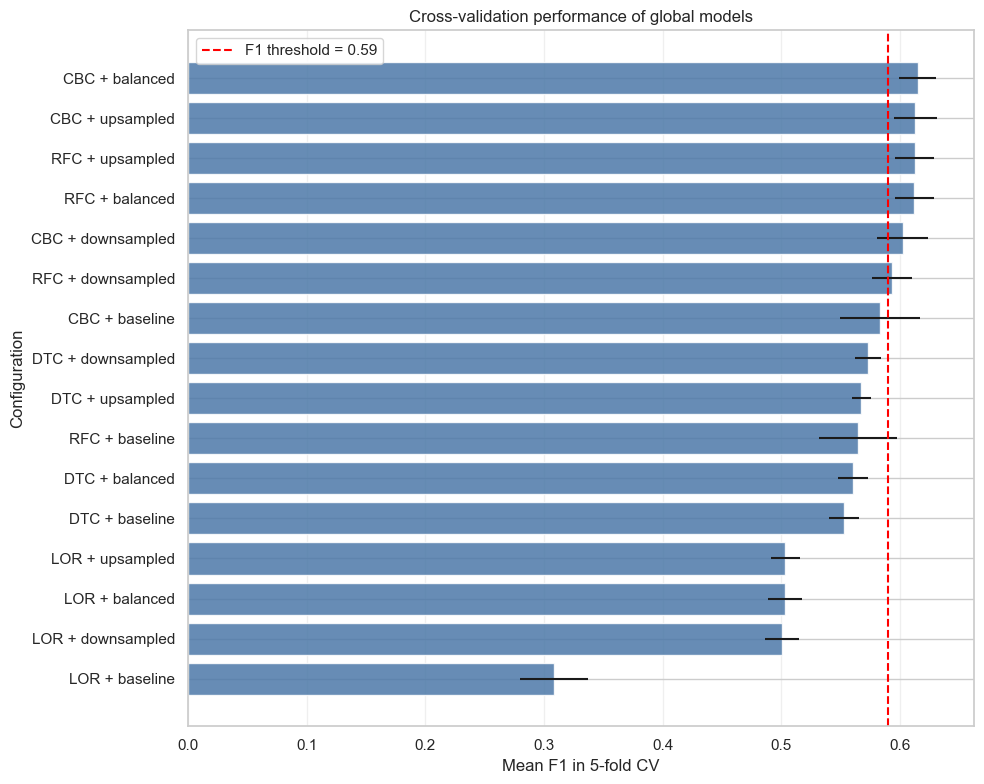

In [118]:
# Create readable configuration labels for the comparison chart
plot_data = global_cv_results.copy()

plot_data['Configuration'] = (
    plot_data['Model'] + ' + ' + plot_data['Strategy']
)

plot_data = plot_data.sort_values('CV F1, mean')

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data['Configuration'],
    plot_data['CV F1, mean'],
    xerr=plot_data['CV F1, std'],
    color='#4C78A8',
    alpha=0.85
)

# Mark the project's target F1 value as a visual reference
plt.axvline(
    0.59,
    color='red',
    linestyle='--',
    label='F1 threshold = 0.59'
)

# Label the axes and add reference elements for interpretation
plt.xlabel('Mean F1 in 5-fold CV')
plt.ylabel('Configuration')
plt.title('Cross-validation performance of global models')
plt.grid(axis='x', alpha=0.3)
plt.legend()

plt.tight_layout()

plt.show()

**Global model training results**

The highest mean **F1 score** was achieved by **CBC + balanced: 0.615 ± 0.016**.
Its pooled OOF predictions produced:
- F1 = **0.615**;
- Recall = **0.735**;
- Precision = **0.528**;
- Accuracy = **0.812**;
- AUC-ROC = **0.862**;
- Average Precision = **0.697**.

The next-best results were produced by **CBC + upsampled: 0.613 ± 0.018** and **RFC + upsampled: 0.612 ± 0.017**.\
Because mean F1 is the project's primary metric, **CBC + balanced** was selected as the global model candidate. The final decision will be made after comparison with the regional architectures.

<a id="section-3-5"></a>

### Comparing Global and Regional Architectures

The exploratory analysis revealed **differences in data structure and relationships between individual features**. Models trained on separate country samples may therefore capture regional churn patterns more effectively. Test this hypothesis by comparing global and regional architectures.

Fit **separate models** for **France**, **Germany**, and **Spain**, as well as a **joint model for France and Spain**, because these countries show similar feature relationships and the larger pooled sample may improve predictive performance. Then compare global and regional approaches on the same cross-validation folds and select an architecture for final testing.

For every regional sample, evaluate the same four models, four imbalance strategies, and hyperparameter grids used for the global approach. Within a single country, folds are stratified by `exited`; the pooled France–Spain sample is jointly stratified by `geography × exited`.

Select the configuration with the highest **F1 score** for each **country** and for the pooled **France + Spain** region:

In [119]:
regional_model_names = list(parameter_grids.keys())
regional_strategies = strategies.copy()

country_labels = {
    'France': 'France',
    'Germany': 'Germany',
    'Spain': 'Spain'
}


def tune_group(group_name, X_group, y_group, strata):
    """Selects the best model and strategy for the specified customer group."""

    folds = prepare_cv_folds(X_group, y_group, strata)

    candidates = []
    specs = {}

    # Tune every model and imbalance strategy for the current regional sample
    for strategy in regional_strategies:
        for model_name in regional_model_names:

            result = tune_with_cv(
                model_name,
                strategy,
                parameter_grids[model_name],
                folds
            )

            # Index detailed tuning results by strategy and model name
            key = (strategy, model_name)
            specs[key] = result

            # Calculate pooled metrics from the candidate's regional OOF predictions
            metrics = metric_row(
                y_group.loc[result['prediction'].index],
                result['prediction'],
                result['probability']
            )

            # Add fold-level F1 statistics and pooled OOF metrics to the regional summary
            candidates.append({
                'Group': group_name,
                'Strategy': strategy,
                'Model': model_name,
                'CV F1, mean': result['cv_f1_mean'],
                'CV F1, std': result['cv_f1_std'],
                **metrics
            })

    # Rank regional configurations by mean CV F1 and then by AUC-ROC
    table = (
        pd.DataFrame(candidates)
        .sort_values(
            ['CV F1, mean', 'AUC-ROC'],
            ascending=False
        )
        .reset_index(drop=True)
    )

    # Select the highest-ranked configuration for the current regional sample
    best_row = table.iloc[0]
    best_key = (best_row['Strategy'], best_row['Model'])

    return table, specs[best_key], best_key


country_tables = {}
country_best_specs = {}

# Tune a separate model for each country using target-stratified folds
for country, label in country_labels.items():

    mask = features_train_raw['geography'] == country
    X_country = features_train_raw.loc[mask].copy()
    y_country = target_train.loc[mask].copy()

    # Run the complete model and strategy search for the current country
    table, result, key = tune_group(
        label,
        X_country,
        y_country,
        y_country
    )

    # Preserve the complete country-level ranking
    country_tables[country] = table

    # Store the selected country configuration and its OOF predictions
    country_best_specs[country] = {
        'strategy': key[0],
        'model_name': key[1],
        'params': result['params'],
        'prediction': result['prediction'],
        'probability': result['probability']
    }


# Combine French and Spanish customers into one regional training sample
fs_mask = features_train_raw['geography'].isin(['France', 'Spain'])
X_fs = features_train_raw.loc[fs_mask].copy()
y_fs = target_train.loc[fs_mask].copy()

# Preserve both country representation and churn rates in the pooled-region folds
fs_strata = (
    X_fs['geography'].astype(str)
    + '_'
    + y_fs.astype(str)
)

# Tune one shared model on the combined France–Spain sample
fs_table, fs_result, fs_key = tune_group(
    'France + Spain',
    X_fs,
    y_fs,
    fs_strata
)

# Store the selected pooled-region configuration and its OOF predictions
fs_best_spec = {
    'strategy': fs_key[0],
    'model_name': fs_key[1],
    'params': fs_result['params'],
    'prediction': fs_result['prediction'],
    'probability': fs_result['probability']
}

regional_leaders = pd.concat(
    [
        country_tables['France'].head(1),
        country_tables['Germany'].head(1),
        country_tables['Spain'].head(1),
        fs_table.head(1)
    ],
    ignore_index=True
)

# Display the best configuration selected for every regional sample
display('Best regional configurations from 5-fold CV:')
display(regional_leaders.round(3))

'Best regional configurations from 5-fold CV:'

,Group,Strategy,Model,"CV F1, mean","CV F1, std",F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,France,balanced,RFC,0.568,0.040,0.568,0.613,0.530,0.850,0.842,0.599
1,Germany,downsampled,CBC,0.700,0.034,0.700,0.768,0.644,0.787,0.858,0.766
2,Spain,upsampled,RFC,0.550,0.045,0.552,0.586,0.522,0.841,0.825,0.581
3,France + Spain,upsampled,RFC,0.567,0.028,0.567,0.630,0.516,0.843,0.843,0.623


**Best regional configurations**

The best regional result was obtained for **Germany**: **CBC + downsampled**, with a mean F1 score of **0.700 ± 0.034**.

The best configuration for **France** was **RFC + balanced**, with a mean F1 of **0.568 ± 0.040**. For **Spain**, it was **RFC + upsampled**, with F1 = **0.550 ± 0.045**.

For the pooled **France and Spain** sample, **RFC + upsampled** was best, with a mean F1 of **0.567 ± 0.028**.

To determine whether the regional architecture is genuinely superior, it must be compared with the global model on the same cross-validation folds.

Preliminarily evaluate the **combined predictions** of the regional models across the **entire training set**:

In [120]:
global_oof_pred = best_global_spec['prediction'].reindex(target_train.index)
global_oof_proba = best_global_spec['probability'].reindex(target_train.index)

# Assemble country-model OOF predictions in the original training-set index
country_oof_pred = pd.Series(index=target_train.index, dtype='int64')
country_oof_proba = pd.Series(index=target_train.index, dtype='float64')

for country, spec in country_best_specs.items():
    country_oof_pred.loc[spec['prediction'].index] = spec['prediction']
    country_oof_proba.loc[spec['probability'].index] = spec['probability']


# Start from country-model predictions and replace France and Spain with shared-model predictions
grouped_oof_pred = country_oof_pred.copy()
grouped_oof_proba = country_oof_proba.copy()

grouped_oof_pred.loc[fs_result['prediction'].index] = (
    fs_result['prediction']
)
grouped_oof_proba.loc[fs_result['probability'].index] = (
    fs_result['probability'])


architecture_predictions = {
    'Global model': (
        global_oof_pred,
        global_oof_proba
    ),
    'Separate country models': (
        country_oof_pred.astype(int),
        country_oof_proba
    ),
    'Germany separately, France + Spain together': (
        grouped_oof_pred.astype(int),
        grouped_oof_proba
    )}

# Calculate pooled OOF metrics for each candidate architecture
architecture_cv_rows = []

for approach, (prediction, probability) in (
    architecture_predictions.items()
):
    architecture_cv_rows.append({
        'Approach': approach,
        **metric_row(target_train, prediction, probability)
    })

# Rank architectures by pooled OOF F1 and then by AUC-ROC
architecture_cv_results = (
    pd.DataFrame(architecture_cv_rows)
    .sort_values(
        ['F1', 'AUC-ROC'],
        ascending=False
    )
    .reset_index(drop=True))

# Record the preliminary OOF leader for further stability testing
preliminary_leader = architecture_cv_results.iloc[0]['Approach']

display('Architecture comparison using OOF predictions from 5-fold CV:')
display(architecture_cv_results.round(3))
display(f'Preliminary leader: {preliminary_leader}')

'Architecture comparison using OOF predictions from 5-fold CV:'

,Approach,F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,"Germany separately, France + Spain together",0.620,0.685,0.566,0.829,0.856,0.683
1,Separate country models,0.618,0.669,0.575,0.832,0.853,0.665
2,Global model,0.615,0.735,0.528,0.812,0.862,0.697


'Preliminary leader: Germany separately, France + Spain together'

**Combined performance of the regional models**

The preliminary F1 leader is the **pooled regional architecture**, consisting of a **separate model for Germany** and a **joint model for France and Spain**, with F1 = **0.620**. Three separate country models (**0.618**) and the global model (**0.615**) produce similar results.

The global model has higher AUC-ROC (**0.862**) and Average Precision (**0.697**). Because the differences between architectures are small, their **stability** should be assessed using repeated cross-validation on the same folds.

**Compare the global and regional configurations separately within each country:**

'Comparison of approaches by country using OOF predictions:'

,Country,Approach,Number of customers,F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,France,Global model,4011,0.570,0.667,0.498,0.838,0.852,0.640
1,France,Country model,4011,0.568,0.613,0.530,0.850,0.842,0.599
2,France,France + Spain model,4011,0.569,0.623,0.523,0.847,0.847,0.629
3,Germany,Global model,2007,0.680,0.845,0.569,0.742,0.861,0.778
4,Germany,Country model,2007,0.700,0.768,0.644,0.787,0.858,0.766
5,Spain,Global model,1982,0.565,0.653,0.498,0.832,0.844,0.635
6,Spain,Country model,1982,0.552,0.586,0.522,0.841,0.825,0.581
7,Spain,France + Spain model,1982,0.564,0.644,0.502,0.834,0.835,0.613


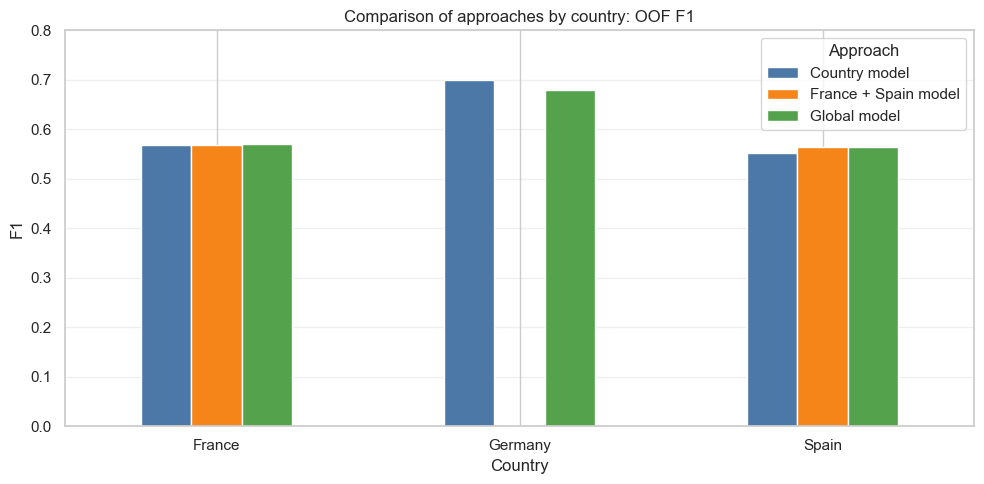

In [121]:
# Collect country-level metrics for every applicable architecture
regional_cv_rows = []

# Evaluate architecture performance separately within each country
for country, label in country_labels.items():

    mask = features_train_raw['geography'] == country
    y_part = target_train.loc[mask]

    # Include the global model and the corresponding country-specific model
    approaches = {
        'Global model': (
            global_oof_pred.loc[mask],
            global_oof_proba.loc[mask]
        ),
        'Country model': (
            country_oof_pred.loc[mask].astype(int),
            country_oof_proba.loc[mask]
        )
    }

    # Add the shared France–Spain model only where it is applicable
    if country in ('France', 'Spain'):
        approaches['France + Spain model'] = (
            fs_result['prediction'].reindex(y_part.index),
            fs_result['probability'].reindex(y_part.index)
        )

    # Calculate metrics on the same customers for every applicable approach
    for approach, (prediction, probability) in approaches.items():
        regional_cv_rows.append({
            'Country': label,
            'Approach': approach,
            'Number of customers': int(mask.sum()),
            **metric_row(y_part, prediction, probability)
        })


# Combine country-level architecture metrics into one comparison table
regional_cv_comparison = pd.DataFrame(regional_cv_rows)

display('Comparison of approaches by country using OOF predictions:')
display(regional_cv_comparison.round(3))


# Reshape country-level F1 scores for grouped-bar visualization
regional_f1_plot = regional_cv_comparison.pivot(
    index='Country',
    columns='Approach',
    values='F1'
)

ax = regional_f1_plot.plot(
    kind='bar',
    figsize=(10, 5),
    color=['#4C78A8', '#F58518', '#54A24B']
)

# Format the chart for direct comparison of architectures within countries
ax.set_title('Comparison of approaches by country: OOF F1')
ax.set_xlabel('Country')
ax.set_ylabel('F1')
ax.set_ylim(0, 0.8)
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Approach')

plt.tight_layout()
plt.show()

**Preliminary regional model-selection results**

The full search produced the following best configurations:

- France — **RFC + balanced**, CV F1 = **0.568 ± 0.040**;
- Germany — **CBC + downsampled**, CV F1 = **0.700 ± 0.034**;
- Spain — **RFC + upsampled**, CV F1 = **0.550 ± 0.045**;
- France + Spain — **RFC + upsampled**, CV F1 = **0.567 ± 0.028**.

The full search was useful: **downsampling** produced the best configuration for Germany and would have been excluded by a reduced strategy search.

Based on the initial OOF predictions, the “Germany separately, France + Spain together” architecture achieved F1 = **0.620**, the three separate country models achieved **0.618**, and the global model achieved **0.615**. These results are preliminary because the regional and global configurations were selected on different internal folds. The final comparison will be performed on the same repeated folds.

<a id="section-3-6"></a>

### Architecture Stability Check Using Repeated Cross-Validation

To assess result stability, we will fix the best configurations selected during the initial cross-validation and compare three architectures:

- one global model for all countries;
- a separate model for each country;
- a separate model for Germany and one shared model for France and Spain.

Evaluation will use **repeated 5-fold cross-validation with three repeats**. All architectures will be trained and evaluated on the same folds, formed using joint stratification by `geography × exited`. At every iteration, preprocessing and imbalance correction will be fitted anew using only the training portion of the current fold.

For each architecture, we will calculate mean F1, AUC-ROC, and Average Precision, as well as the standard deviation of F1. We will then compare the regional architectures with the global model on the same folds.

A regional architecture will be selected only if its mean F1 improvement over the global model is at least **0.01** and the lower bound of the indicative **95% interval for the improvement** is above zero. Otherwise, the simpler global model will be selected for final testing.

**Note:** this project uses a simplified protocol rather than fully nested cross-validation, because the fixed configurations were previously selected on **the same training sample**. Repeated cross-validation reduces dependence on one particular split but does not fully eliminate optimistic bias. The calculated intervals should also be treated as indicative because repeated-CV folds are not fully independent. Final performance will be evaluated on an independent test sample that was not used for configuration or architecture selection.

In [122]:
def fit_predict_fixed(
    X_fit_raw, y_fit, X_holdout_raw, spec, RANDOM_STATE
):
    """Fits a fixed configuration and returns predictions"""

    # Fit preprocessing on the training portion and apply it to the holdout portion
    X_fit, state = fit_preprocessor(X_fit_raw,RANDOM_STATE)
    X_holdout = transform_with_preprocessor(
        X_holdout_raw, state, RANDOM_STATE + 1
    )

    # Apply the fixed imbalance strategy only to the training portion
    X_fit_mod, y_fit_mod = apply_strategy(
        X_fit, y_fit, spec['strategy'], RANDOM_STATE
    )

    # Recreate the model using the previously selected hyperparameters
    model = make_model(spec['model_name'], spec['strategy'], spec['params'])
    
    # Fit the fixed configuration without additional hyperparameter tuning
    model.fit(X_fit_mod, y_fit_mod)

    prediction = np.asarray(
        model.predict(X_holdout)
    ).astype(int).ravel()
    probability = model.predict_proba(X_holdout)[:, 1]

    return prediction, probability


# Fix the configurations selected during the initial cross-validation
fixed_specs = {
    'global': {
        'strategy': best_global_key[0],
        'model_name': best_global_key[1],
        'params': best_global_spec['params']
    },

    # Add the selected configuration for each country
    **{
        country: {
            key: value
            for key, value in spec.items()
            if key in ('strategy', 'model_name', 'params')
        }
        for country, spec in country_best_specs.items()
    },

    # Add the selected configuration for the pooled France–Spain sample
    'France_Spain': {
        key: value
        for key, value in fs_best_spec.items()
        if key in ('strategy', 'model_name', 'params')
    }
}


# Create 15 repeated evaluation splits: five folds repeated three times
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE + 1000
)

# Store fold-level metrics for every candidate architecture
stability_rows = []


# Evaluate all architectures on the same repeated CV splits
for split_number, (fit_pos, holdout_pos) in enumerate(
    repeated_cv.split(features_train_raw, global_strata),
    start=1
):
    fit_idx = features_train_raw.index[fit_pos]
    holdout_idx = features_train_raw.index[holdout_pos]

    # Use identical customers for evaluating every architecture in the current fold
    X_fit = features_train_raw.loc[fit_idx]
    y_fit = target_train.loc[fit_idx]
    X_holdout = features_train_raw.loc[holdout_idx]
    y_holdout = target_train.loc[holdout_idx]

    # Collect class predictions and probabilities for each architecture
    pred_by_approach = {}
    prob_by_approach = {}


    # Train the fixed global configuration on customers from all countries
    pred, prob = fit_predict_fixed(
        X_fit,
        y_fit,
        X_holdout,
        fixed_specs['global'],
        RANDOM_STATE + split_number * 10
    )

    # Preserve holdout indices for paired architecture comparison
    pred_by_approach['Global model'] = pd.Series(pred, index=holdout_idx)
    prob_by_approach['Global model'] = pd.Series(prob, index=holdout_idx)

    # Allocate containers for combining predictions from the three country models
    country_pred = pd.Series(index=holdout_idx, dtype='int64')
    country_prob = pd.Series(index=holdout_idx, dtype='float64')

    # Train and apply the fixed configuration selected for each country
    for country in country_labels:
        fit_mask = X_fit['geography'] == country
        holdout_mask = X_holdout['geography'] == country

        pred, prob = fit_predict_fixed(
            X_fit.loc[fit_mask],
            y_fit.loc[fit_mask],
            X_holdout.loc[holdout_mask],
            fixed_specs[country],
            RANDOM_STATE + split_number * 10 + 2
        )

        # Write each country model's predictions back to the corresponding holdout rows
        group_idx = X_holdout.index[holdout_mask]
        country_pred.loc[group_idx] = pred
        country_prob.loc[group_idx] = prob

    pred_by_approach['Separate country models'] = (
        country_pred.astype(int)
    )
    prob_by_approach['Separate country models'] = country_prob


    # Select French and Spanish customers for the shared regional model
    fs_fit_mask = X_fit['geography'].isin(['France', 'Spain'])
    fs_holdout_mask = X_holdout['geography'].isin(
        ['France', 'Spain']
    )

    # Train the fixed pooled-region configuration on France and Spain
    fs_pred, fs_prob = fit_predict_fixed(
        X_fit.loc[fs_fit_mask],
        y_fit.loc[fs_fit_mask],
        X_holdout.loc[fs_holdout_mask],
        fixed_specs['France_Spain'],
        RANDOM_STATE + split_number * 10 + 4
    )

    # Keep Germany's country-model predictions and replace France and Spain with shared-model predictions
    grouped_pred = country_pred.copy()
    grouped_prob = country_prob.copy()
    fs_idx = X_holdout.index[fs_holdout_mask]
    grouped_pred.loc[fs_idx] = fs_pred
    grouped_prob.loc[fs_idx] = fs_prob

    grouped_name = 'Germany separately, France + Spain together'
    pred_by_approach[grouped_name] = grouped_pred.astype(int)
    prob_by_approach[grouped_name] = grouped_prob


    # Calculate fold-level metrics for every architecture on the same holdout customers
    for approach in pred_by_approach:
        stability_rows.append({
            'Repeat': (split_number - 1) // 5 + 1,
            'Fold': (split_number - 1) % 5 + 1,
            'Approach': approach,
            **metric_row(
                y_holdout,
                pred_by_approach[approach].reindex(holdout_idx),
                prob_by_approach[approach].reindex(holdout_idx)
            )
        })


# Combine metrics from all 15 repeated CV splits into one table
stability_results = pd.DataFrame(stability_rows)

# Summarize mean performance and F1 variability for each architecture
stability_summary = (
    stability_results
    .groupby('Approach')
    .agg(
        F1_mean=('F1', 'mean'),
        F1_std=('F1', 'std'),
        AUC_ROC_mean=('AUC-ROC', 'mean'),
        AP_mean=('Average Precision', 'mean')
    )
    .sort_values('F1_mean', ascending=False)
)

# Align architecture F1 scores by repeat and fold for paired comparison
paired = stability_results.pivot(
    index=['Repeat', 'Fold'],
    columns='Approach',
    values='F1'
)


# Compare each regional architecture with the global model on matched folds
gain_rows = []

for approach in paired.columns:
    if approach == 'Global model':
        continue

    # Calculate the paired F1 difference on every common fold
    difference = paired[approach] - paired['Global model']

    # Estimate an indicative 95% interval for the mean F1 difference
    difference_se = difference.std(ddof=1) / np.sqrt(len(difference))
    interval = (
        difference.mean() - 1.96 * difference_se,
        difference.mean() + 1.96 * difference_se
    )

    gain_rows.append({
        'Approach': approach,
        'Mean F1 improvement': difference.mean(),
        'Lower interval bound': interval[0],
        'Upper interval bound': interval[1]
    })


# Rank regional architectures by their mean F1 improvement
architecture_gains = pd.DataFrame(gain_rows).sort_values(
    'Mean F1 improvement',
    ascending=False
)

# Identify the architecture with the highest mean F1 in repeated CV
best_repeated_approach = stability_summary.index[0]

# Select a regional architecture only if its advantage is both positive and practically meaningful
if best_repeated_approach == 'Global model':
    selected_approach = 'Global model'
else:
    best_gain = architecture_gains.loc[
        architecture_gains['Approach'] == best_repeated_approach
    ].iloc[0]

    regional_gain_confirmed = (
        best_gain['Mean F1 improvement'] >= 0.01
        and best_gain['Lower interval bound'] > 0
    )

    selected_approach = (
        best_repeated_approach
        if regional_gain_confirmed
        else 'Global model'
    )


# Display architecture stability, paired improvements, and the selected approach
display('Architecture stability: 5 folds × 3 repeats')
display(stability_summary.round(3))

display('Regional architecture improvement over the global model:')
display(architecture_gains.round(3))

display(f'Recommended approach: {selected_approach}')

'Architecture stability: 5 folds × 3 repeats'

,F1_mean,F1_std,AUC_ROC_mean,AP_mean
Approach,,,,
"Germany separately, France + Spain together",0.618,0.022,0.857,0.687
Global model,0.614,0.019,0.863,0.702
Separate country models,0.610,0.022,0.852,0.677


'Regional architecture improvement over the global model:'

,Approach,Mean F1 improvement,Lower interval bound,Upper interval bound
0,"Germany separately, France + Spain together",0.004,-0.000,0.008
1,Separate country models,-0.004,-0.011,0.003


'Recommended approach: Global model'

**Interpretation of the training results**

The combined regional architecture achieved a slightly higher mean F1 score (**0.618**) than the global model (**0.614**), but the improvement was only **0.004**, and its indicative interval included zero. The global model also achieved higher AUC-ROC (**0.863**), Average Precision (**0.702**), and a lower F1 variation (**0.019**).

Thus, a stable and practically meaningful advantage of the regional architectures was not confirmed. The simpler **global model** was selected for final testing.

To compare architecture stability visually, we will plot the repeated cross-validation results. For each approach, the chart will show the **mean F1 score**, while the error bars will represent its **standard deviation** across the 15 evaluation folds.

A higher mean F1 indicates better predictive performance, while a lower standard deviation indicates a more stable result as the training and validation samples change. However, overlap between error bars is not, by itself, a formal test of statistically significant differences between architectures.

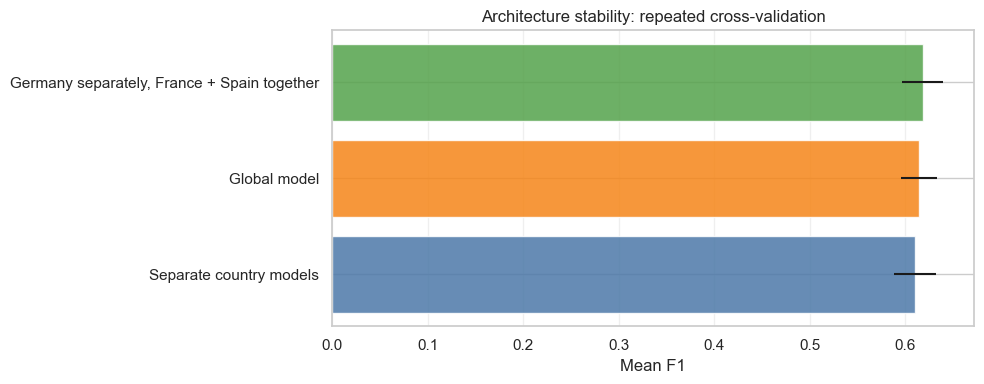

In [123]:
# Calculate mean F1 and its standard deviation across the 15 repeated CV splits
plot_stability = (
    stability_results
    .groupby('Approach')['F1']
    .agg(['mean', 'std'])
    .sort_values('mean')
)

# Visualize both average performance and variation across repeated folds
plt.figure(figsize=(10, 4))

plt.barh(
    plot_stability.index,
    plot_stability['mean'],
    xerr=plot_stability['std'],
    color=['#4C78A8', '#F58518', '#54A24B'],
    alpha=0.85
)

# Label the chart for direct comparison of architecture stability
plt.xlabel('Mean F1')
plt.title('Architecture stability: repeated cross-validation')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

**Repeated-evaluation results**

Evaluation on the same repeated CV splits produced the following results:

- “Germany separately, France + Spain together”: mean F1 = **0.618 ± 0.022**;
- global model: **0.614 ± 0.019**;
- three separate country models: **0.610 ± 0.022**.

The mean F1 improvement of the combined regional architecture over the global model was only **+0.004**, with an indicative 95% interval of **[−0.000; +0.008]**. For the three separate models, the mean difference was **−0.004**, with an interval of **[−0.011; +0.003]**.

Because the training portions of repeated folds overlap, these intervals are used as diagnostic guidance rather than as a formal significance test. The results do not confirm a stable practical advantage of the regional architectures.

**Architecture Selection for Final Testing**

The **global CBC + balanced model** was selected for final testing.

Although the “Germany separately, France + Spain together” architecture achieved a slightly higher mean F1, its advantage was only **0.004**, did not reach the practical threshold of **0.01**, and its interval included zero. The simpler single-model solution was therefore preferred.

<a id="section-3-7"></a>

### Model Development, Training, and Architecture Selection: Section Summary

**The model-training and comparison framework was defined:**

- Four classification algorithms were considered: DecisionTreeClassifier (**DTC**), RandomForestClassifier (**RFC**), LogisticRegression (**LOR**), and CatBoostClassifier (**CBC**).
- Four approaches to class imbalance were tested for each algorithm: `baseline`, `upsampled`, `downsampled`, and `balanced`.
- Training and hyperparameter selection used **5-fold cross-validation**, with mean F1 as the primary criterion. F1 standard deviation and metrics from combined OOF predictions were also calculated.
- Three solution architectures were considered: a **global** model for all countries, **country-specific** models, and a **combined regional** architecture with a separate German model and one shared model for France and Spain.

---

**Data prepared for modelling:**

- Auxiliary categorical features created for exploratory analysis — `age_group`, `credit_score_group`, `balance_group`, and `estimated_salary_group` — were removed.
- Original missing values in `tenure` were restored using `tenure_missing` so that imputation could be performed separately within each fold.
- The data was divided into training and test samples in an **80/20** ratio.
- Joint stratification by `geography × exited` preserved country representation and the target-class ratio within each country.
- The test sample was excluded from model, imbalance-strategy, hyperparameter, and architecture selection and reserved solely for final evaluation.

---

**Preprocessing organised within cross-validation:**

1. Split the current fold into training and validation portions.
2. Determine the observed values used to impute missing `tenure` from the training portion.
3. Impute both portions using information from the training portion only.
4. Fit `OneHotEncoder` on the training portion and apply it to both portions.
5. Estimate scaling parameters from the training portion and apply them to both portions.
6. Apply upsampling or downsampling only to the training portion; under `balanced`, pass class weights to the model without changing the number of observations.
7. Fit the model on the prepared training portion.
8. Generate predictions and evaluate performance on the original, unbalanced validation portion.

The required fold count, hyperparameter grids, strategy and feature lists, and preprocessing, training, and evaluation functions were prepared.

---

**Global and regional models trained and compared:**

- The same algorithms, imbalance strategies, and hyperparameter grids were tested for the global and all regional samples.
- The best global configuration was **CBC + balanced**, with mean F1 = **0.615 ± 0.016**. Combined OOF predictions yielded Recall = **0.735**, Precision = **0.528**, AUC-ROC = **0.862**, and Average Precision = **0.697**.
- The best configuration for France was **RFC + balanced**, F1 = **0.568 ± 0.040**.
- For Germany, it was **CBC + downsampled**, F1 = **0.700 ± 0.034**.
- For Spain, it was **RFC + upsampled**, F1 = **0.550 ± 0.045**.
- For the combined France-and-Spain sample, it was **RFC + upsampled**, F1 = **0.567 ± 0.028**.
- The German country model achieved a strong result, but metrics calculated on different regional samples cannot directly prove that a regional architecture is superior.

---

**Global and regional architectures compared:**

- The preliminary OOF comparison showed a small advantage for the combined regional architecture: F1 = **0.620**, versus **0.618** for separate country models and **0.615** for the global model.
- Stability was then checked using **repeated 5-fold cross-validation with three repeats** on identical folds.
- The combined regional architecture achieved F1 = **0.618 ± 0.022**, the global model **0.614 ± 0.019**, and separate country models **0.610 ± 0.022**.
- The combined regional architecture improved F1 over the global model by only **0.004**, with an indicative interval of **[−0.000; 0.008]**, which included zero.
- The global model achieved higher AUC-ROC (**0.863**) and Average Precision (**0.702**) and a lower F1 standard deviation (**0.019**).
- No stable and practically meaningful advantage of the regional architectures was confirmed. The simpler **global CBC + balanced architecture** was therefore selected for final testing.
- Repeated cross-validation was used as a simplified educational protocol because the configurations had already been selected on the same training sample. Final performance will be assessed on the independent test sample.

<a id="section-4"></a>

## Testing the Selected Architecture

<a id="section-4-1"></a>

### Training the Final Architecture on the Full Training Sample

After selecting the architecture and fixing the model, imbalance strategy, and hyperparameters, we will retrain the final model on the **entire training sample**.

During cross-validation, each model was trained on only four of the five folds, while the remaining fold was used for evaluation. Once selection is complete, splitting the training data into folds is no longer necessary. Using the full training sample allows the model to learn from more observations and obtain a more complete view of churn patterns.

All preprocessing steps — `tenure` imputation, fitting `OneHotEncoder`, and estimating scaling parameters — will be fitted again using only the full training sample. The fixed imbalance strategy will then be applied, and the model will be trained with the previously selected hyperparameters.

The test sample will not be used to select the model, strategy, hyperparameters, architecture, or classification threshold. It will be transformed using preprocessing fitted on the training data and used **once** for the final evaluation on unseen observations.

In [124]:
def fit_final_model(X_raw, y, spec, RANDOM_STATE):
    """Fits the final model on the full available training sample"""

    # Refit the complete preprocessing pipeline on all available training data
    X_processed, state = fit_preprocessor(X_raw, RANDOM_STATE)

    # Apply the selected imbalance strategy to the full processed training sample
    X_mod, y_mod = apply_strategy(
        X_processed, y, spec['strategy'], RANDOM_STATE
    )

    # Recreate the selected model using the fixed hyperparameters
    model = make_model(
        spec['model_name'], spec['strategy'], spec['params']
    )

    # Retrain the selected configuration on the full training sample
    model.fit(X_mod, y_mod)

    # Return both the fitted model and the preprocessing state required for inference
    return model, state


def predict_final(model, state, X_raw, RANDOM_STATE):
    """Generates final-model predictions for new data"""

    # Transform new observations using preprocessing fitted on the training data
    X_processed = transform_with_preprocessor(X_raw, state, RANDOM_STATE)

    prediction = np.asarray(
        model.predict(X_processed)
    ).astype(int).ravel()
    probability = model.predict_proba(X_processed)[:, 1]

    # Return indexed predictions, probabilities, and processed features
    return (
        pd.Series(prediction, index=X_raw.index),
        pd.Series(probability, index=X_raw.index),
        X_processed
    )

# Store fitted models, preprocessing states, and processed test subsets
final_models = {}
final_states = {}
final_processed_parts = {}

# Allocate indexed containers for predictions across the complete test sample
final_prediction = pd.Series(index=target_test.index,  dtype='int64')
final_probability = pd.Series(index=target_test.index, dtype='float64')


def fit_and_store(group_name, train_mask, test_mask, spec, seed):
    """Fits a group model and stores its test predictions."""

    # Fit the selected group configuration on its complete training subset
    model, state = fit_final_model(
        features_train_raw.loc[train_mask],
        target_train.loc[train_mask],
        spec,
        seed
    )

    # Generate predictions for the corresponding test subset
    pred, prob, processed = predict_final(
        model,
        state,
        features_test_raw.loc[test_mask],
        seed + 1
    )

    # Write group predictions back to their original test-set indices
    final_prediction.loc[pred.index] = pred
    final_probability.loc[prob.index] = prob

    # Preserve fitted objects and processed features for later interpretation
    final_models[group_name] = model
    final_states[group_name] = state
    final_processed_parts[group_name] = processed


# Fit one model on all training observations for the global architecture
if selected_approach == 'Global model':
    all_train = pd.Series(True, index=features_train_raw.index)
    all_test = pd.Series(True, index=features_test_raw.index)

    fit_and_store(
        'Full sample',
        all_train,
        all_test,
        fixed_specs['global'],
        RANDOM_STATE
    )


# Fit and apply a separate model for each country
elif selected_approach == 'Separate country models':
    for offset, (country, label) in enumerate(
        country_labels.items()
    ):
        fit_and_store(
            label,
            features_train_raw['geography'] == country,
            features_test_raw['geography'] == country,
            fixed_specs[country],
            RANDOM_STATE + offset * 10
        )


# Fit Germany separately and use one shared model for France and Spain
else:
    fit_and_store(
        'Germany',
        features_train_raw['geography'] == 'Germany',
        features_test_raw['geography'] == 'Germany',
        fixed_specs['Germany'],
        RANDOM_STATE
    )

    fit_and_store(
        'France + Spain',
        features_train_raw['geography'].isin(['France', 'Spain']),
        features_test_raw['geography'].isin(['France', 'Spain']),
        fixed_specs['France_Spain'],
        RANDOM_STATE + 10
    )

# Verify that every test observation received both a class and a probability
assert final_prediction.notna().all()
assert final_probability.notna().all()

# Calculate overall test metrics for the selected architecture
final_test_metrics = pd.DataFrame([{
    'Approach': selected_approach,
    **metric_row(
        target_test,
        final_prediction,
        final_probability
    )
}])

In [125]:
display('Selected architecture performance on the test sample:')
display(final_test_metrics.round(3))

'Selected architecture performance on the test sample:'

,Approach,F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,Global model,0.611,0.769,0.506,0.8,0.881,0.717


Point estimates depend on the particular composition of the test sample and do not reflect **estimation uncertainty**, that is, the possible deviation of the calculated metric from its true value in the full customer population. We will therefore additionally calculate **95% bootstrap confidence intervals** for F1 and AUC-ROC.

We will create **1,000 bootstrap samples** of the same size by randomly drawing test observations with replacement. Metrics will be recalculated from the final model's existing predictions, and interval bounds will be defined by the **2.5th and 97.5th percentiles** of the resulting distributions.

The minimum and maximum are not used because they are overly sensitive to isolated extreme resamples. Percentiles identify the main range of metric variability while excluding the rarest extreme results.

These intervals show how test metrics may vary as the sample composition changes. The model is not retrained during bootstrapping, so the intervals reflect uncertainty associated with the test sample composition, but not variability from model training or configuration selection.

In [126]:
# Use a seeded generator to make bootstrap resampling reproducible
rng = np.random.default_rng(RANDOM_STATE)

# Represent test observations by positional indices for bootstrap sampling
positions = np.arange(len(target_test))

# Store F1 and AUC-ROC values from valid bootstrap samples
bootstrap_f1 = []
bootstrap_auc = []


# Generate 1,000 test-sized samples by drawing observations with replacement
for _ in range(1000):

    sample_pos = rng.choice(
        positions,
        size=len(positions),
        replace=True
    )

    # Extract the target values corresponding to the sampled positions
    y_sample = target_test.iloc[sample_pos]

    # Skip samples containing one class because AUC-ROC is undefined for them
    if y_sample.nunique() < 2:
        continue

    # Recalculate F1 using the fixed predictions for the sampled observations
    bootstrap_f1.append(
        f1_score(
            y_sample,
            final_prediction.iloc[sample_pos],
            zero_division=0
        )
    )

    # Recalculate AUC-ROC using the fixed probabilities for the sampled observations
    bootstrap_auc.append(
        roc_auc_score(
            y_sample,
            final_probability.iloc[sample_pos]
        )
    )


# Combine point estimates with percentile-based 95% bootstrap intervals
metric_intervals = pd.DataFrame({
    'Metric': ['F1', 'AUC-ROC'],

    # Point estimates calculated on the complete test sample
    'Estimate': [
        f1_score(target_test, final_prediction),
        roc_auc_score(target_test, final_probability)
    ],

    # 2.5th percentiles of the bootstrap distributions
    'Lower 95% CI bound': [
        np.quantile(bootstrap_f1, 0.025),
        np.quantile(bootstrap_auc, 0.025)
    ],

    # 97.5th percentiles of the bootstrap distributions
    'Upper 95% CI bound': [
        np.quantile(bootstrap_f1, 0.975),
        np.quantile(bootstrap_auc, 0.975)
    ]
})

# Display test estimates together with their uncertainty intervals
display(metric_intervals.round(3))

,Metric,Estimate,Lower 95% CI bound,Upper 95% CI bound
0,F1,0.611,0.576,0.646
1,AUC-ROC,0.881,0.862,0.900


**Final Model Performance and Stability of Test Metrics**

On the test sample, the final model achieved F1 = **0.611**, with a 95% bootstrap interval of **[0.576; 0.646]**. The point estimate exceeds the required threshold of **0.59**, but the lower interval bound falls below it. Therefore, exceeding the threshold cannot be considered fully robust to changes in test-sample composition.

AUC-ROC is **0.881**, with a 95% interval of **[0.862; 0.900]**. This indicates consistently strong ability to rank customers by churn risk.

Thus, the model meets the project requirement based on the point F1 estimate and demonstrates good ranking performance, but F1 uncertainty should be considered when interpreting and monitoring the model.

<a id="section-4-2"></a>

### Performance by Country and Gender

Overall metrics describe performance on the full test sample, but may conceal differences between customer groups. We will therefore also evaluate the final model **by country and gender**.

For each group, we will calculate the number of customers, actual churn rate, F1, Recall, Precision, Accuracy, AUC-ROC, and Average Precision. This will show how consistently the model performs across countries and for women and men.

Group metrics are used only for **diagnostics and future monitoring**, not to reselect the model after inspecting the test sample. Differences should be interpreted in light of group size and positive-class prevalence. Gender differences alone do not prove unfair treatment, but they require attention because `gender` is used as a predictor.

In [127]:
def grouped_quality(group_feature, labels):
    """Calculates model performance separately for each group"""

    groups = features_test_raw[group_feature]
    rows = []

    # Evaluate the model independently within each observed group
    for value in groups.dropna().unique():
        mask = groups == value

        # Record group size, churn prevalence, and predictive-performance metrics
        rows.append({
            'Group': labels.get(value, value),
            'Count': int(mask.sum()),
            'Churn rate, %': target_test.loc[mask].mean() * 100,
            **metric_row(
                target_test.loc[mask],
                final_prediction.loc[mask],
                final_probability.loc[mask]
            )
        })

    # Return one row of diagnostic metrics for each group
    return pd.DataFrame(rows)


# Calculate descriptive performance metrics separately by country
quality_by_country = grouped_quality(
    'geography',
    {
        'France': 'France',
        'Germany': 'Germany',
        'Spain': 'Spain'
    }
)

# Calculate descriptive performance metrics separately for women and men
quality_by_gender = grouped_quality(
    'gender',
    {
        'Female': 'Women',
        'Male': 'Men'
    }
)

# Display country-level diagnostic metrics
display('Performance by country:')
display(quality_by_country.round(3))

# Display gender-level diagnostic metrics
display('Performance by gender:')
display(quality_by_gender.round(3))

'Performance by country:'

,Group,Count,"Churn rate, %",F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,Germany,502,32.470,0.656,0.853,0.533,0.709,0.852,0.748
1,France,1003,16.152,0.593,0.747,0.492,0.834,0.883,0.724
2,Spain,495,16.566,0.549,0.646,0.477,0.824,0.872,0.651


'Performance by gender:'

,Group,Count,"Churn rate, %",F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,Women,912,24.342,0.625,0.815,0.507,0.762,0.867,0.725
1,Men,1088,17.004,0.592,0.714,0.506,0.833,0.891,0.714


**Model performance by country**

The highest F1 score was obtained for customers in **Germany — 0.656**. This group also has the highest Recall (**0.853**), meaning that the model identifies about **85.3%** of churned customers. Accuracy is lower than in the other countries (**0.709**), partly because Germany has a higher churn rate — **32.47%**.

F1 equals **0.593** in France and **0.549** in Spain. Spain has the lowest Recall (**0.646**) and Precision (**0.477**), so at the standard classification threshold the model performs somewhat worse for this country. Nevertheless, AUC-ROC remains high in every country — from **0.852** to **0.883** — indicating good risk-ranking ability.

Regional metrics should be compared cautiously because the countries differ in sample size and actual churn prevalence. This is especially important for Germany and Spain, whose test groups contain about 500 customers each.

**Model performance by gender**

For women, the model achieved higher F1 (**0.625**) and Recall (**0.815**) than for men — **0.592** and **0.714**, respectively. Thus, it detects a larger share of churned customers among women. Precision is almost identical in the two groups: **0.507** for women and **0.506** for men.

AUC-ROC is higher for men — **0.891** versus **0.867** for women — so the model ranks male customers somewhat better by churn probability. Lower Accuracy for women (**0.762** versus **0.833**) should be interpreted in light of their higher actual churn rate: **24.34%** versus **17.00%**.

These differences do not, by themselves, demonstrate model unfairness. Such a conclusion would require a separate analysis of the stability of differences and error patterns between groups.

<a id="section-4-3"></a>

### Precision–Recall Analysis and Confusion Matrix

Because the target class is imbalanced and churned customers account for about **20%** of the sample, we will additionally assess the model using the **Precision–Recall curve** and **Average Precision**. Unlike Accuracy and AUC-ROC, this analysis focuses more directly on recognition of the positive, less represented class — churned customers.

The Precision–Recall curve shows the trade-off between:

- **Recall** — the share of churned customers detected by the model;
- **Precision** — the share of actual churned customers among all customers flagged as at risk.

Each point on the curve corresponds to a classification threshold. The positive-class share in the test sample is used as the baseline: for a model without ranking ability, expected Precision is approximately equal to the churn rate. **Average Precision** summarizes ranking quality across the whole curve; the farther it is above the baseline, the better the model identifies high-risk customers.

We will also build a **confusion matrix** for predictions at the standard threshold of **0.5**. It will show the numbers of correctly and incorrectly classified retained and churned customers. A production threshold should be selected separately using cross-validation predictions and the costs of missed churn and false alerts, not tuned on the test sample.

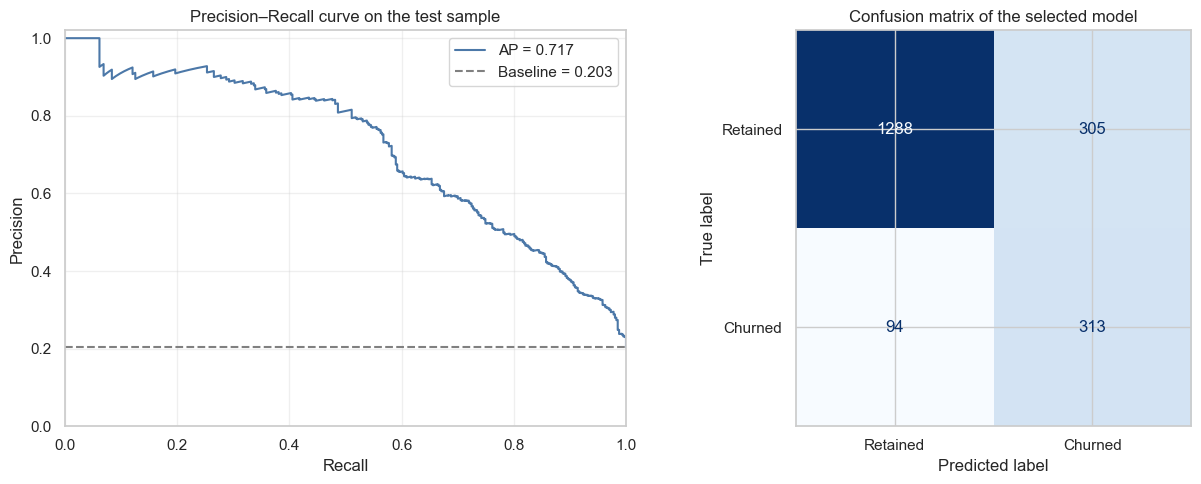

In [128]:
# Summarize precision–recall ranking quality across all thresholds
final_average_precision = average_precision_score(target_test, final_probability)

# Use the positive-class prevalence as the no-skill Precision baseline
positive_class_share = target_test.mean()

# Calculate Precision and Recall across all possible probability thresholds
pr_precision, pr_recall, _ = precision_recall_curve(
    target_test,
    final_probability
)


# Place the PR curve and confusion matrix side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot the trade-off between Precision and Recall across thresholds
axes[0].plot(
    pr_recall,
    pr_precision,
    color='#4C78A8',
    label=f'AP = {final_average_precision:.3f}'
)

# Mark the Precision expected from a model without ranking ability
axes[0].axhline(
    positive_class_share,
    color='gray',
    linestyle='--',
    label=f'Baseline = {positive_class_share:.3f}'
)

# Set axis limits and descriptive labels for the Precision–Recall plot
axes[0].set(
    title='Precision–Recall curve on the test sample',
    xlabel='Recall',
    ylabel='Precision',
    xlim=(0, 1),
    ylim=(0, 1.02)
)
axes[0].grid(alpha=0.3)
axes[0].legend()

# Show classification outcomes at the model's default threshold of 0.5
ConfusionMatrixDisplay.from_predictions(
    target_test,
    final_prediction,
    display_labels=['Retained', 'Churned'],
    cmap='Blues',
    colorbar=False,
    ax=axes[1]
)

# Label the threshold-dependent error matrix
axes[1].set_title('Confusion matrix of the selected model')

plt.tight_layout()
plt.show()

**Precision–Recall analysis results**

The final model's Average Precision is **0.717**, substantially above the baseline equal to the share of churned customers (**0.203**). The model therefore identifies high-risk customers considerably better than random ranking.

At the standard classification threshold of **0.5**, the model:

- correctly identified **313 of 407** churned customers;
- missed **94** churned customers;
- correctly classified **1,288** retained customers;
- incorrectly flagged **305** retained customers as at risk.

Recall is **0.769**: the model identifies about **76.9%** of churned customers and misses approximately **23.1%**. Precision is **0.506**, so about half of the customers flagged as likely to churn actually did so, while the remaining alerts are false positives.

Thus, the model detects most churned customers at the cost of a noticeable number of false alerts. Before practical use, the working threshold should be selected from cross-validation predictions while considering the cost of a retention offer and the losses caused by missed churn, without using the test sample for this purpose.

<a id="section-4-4"></a>

### Final Model Interpretation

To understand which features contribute most to final-model performance, we will calculate **permutation feature importance** on the test sample.

For each feature, its values will be randomly shuffled while the other features remain unchanged. AUC-ROC will then be recalculated:

- a substantial decrease means that the feature is important for predictive performance;
- a value close to zero indicates little additional contribution;
- a negative value means that the metric happened to improve slightly after shuffling and generally indicates no stable positive contribution.

To reduce random variation, each feature will be shuffled **20 times**, after which the mean change in AUC-ROC and its standard deviation will be calculated.

Permutation importance describes a feature's contribution to the performance of this particular trained model, but it does not show the direction of its effect or establish causality. Importance can also be shared among correlated features, so the results should be interpreted together with the exploratory analysis.

,Model / group,Feature,Mean decrease in AUC-ROC,Standard deviation
4,Full sample,num_of_products,0.1352,0.0099
1,Full sample,age,0.1240,0.0077
3,Full sample,balance,0.0365,0.0039
6,Full sample,is_active_member,0.0268,0.0033
9,Full sample,geography_Germany,0.0227,0.0037
11,Full sample,gender_Male,0.0059,0.0021
0,Full sample,credit_score,0.0011,0.0008
7,Full sample,estimated_salary,0.0007,0.0006
2,Full sample,tenure,0.0001,0.0007
10,Full sample,geography_Spain,-0.0000,0.0008


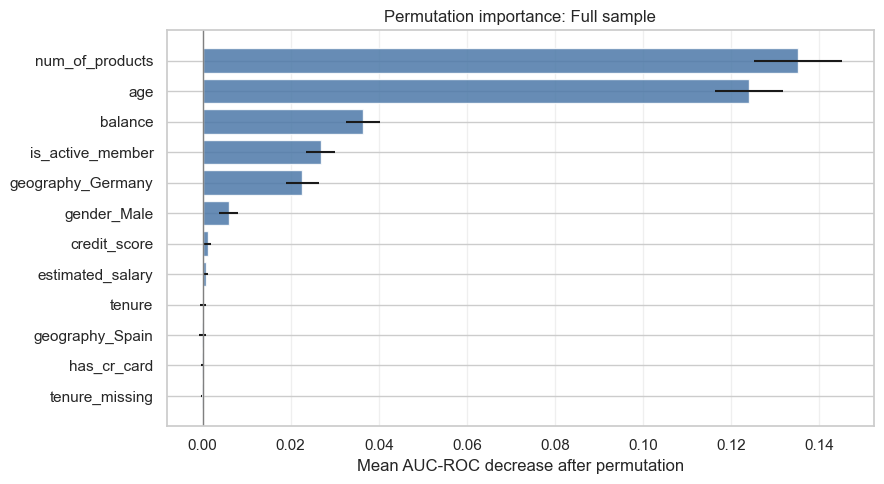

In [129]:
# Collect permutation-importance results from all models in the selected architecture
importance_parts = []

# Measure feature importance separately for each fitted final model
for group_name, model in final_models.items():

    # Select the processed test observations evaluated by the current model
    processed = final_processed_parts[group_name]

    # Measure how much AUC-ROC decreases when each feature is randomly permuted
    result = permutation_importance(
        model,
        processed,
        target_test.loc[processed.index],
        scoring='roc_auc',
        n_repeats=20,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    # Store the mean importance and its variation across permutation repeats
    importance_parts.append(pd.DataFrame({
        'Model / group': group_name,
        'Feature': processed.columns,
        'Mean decrease in AUC-ROC': result.importances_mean,
        'Standard deviation': result.importances_std
    }))

# Combine model-level results and rank features by mean AUC-ROC decrease
feature_importance = pd.concat(
    importance_parts,
    ignore_index=True
).sort_values(
    ['Model / group', 'Mean decrease in AUC-ROC'],
    ascending=[True, False]
)

# Display numerical importance estimates for all evaluated features
display(feature_importance.round(4))

# Visualize feature importance separately for each model in the architecture
for group_name in feature_importance['Model / group'].unique():

    # Order features from the smallest to the largest importance for horizontal plotting
    plot_data = feature_importance[
        feature_importance['Model / group'] == group_name
    ].sort_values('Mean decrease in AUC-ROC')

    plt.figure(figsize=(9, 5))
    plt.barh(
        plot_data['Feature'],
        plot_data['Mean decrease in AUC-ROC'],
        xerr=plot_data['Standard deviation'],
        color='#4C78A8',
        alpha=0.85
    )

    # Mark zero importance: permutation does not reduce model performance
    plt.axvline(0, color='gray', linewidth=1)

    # Label the chart using AUC-ROC decrease as the importance measure
    plt.title(f'Permutation importance: {group_name}')
    plt.xlabel('Mean AUC-ROC decrease after permutation')
    plt.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

**Model interpretation results**

The largest AUC-ROC decreases after shuffling are observed for number of products (**0.1352**) and age (**0.1240**). These are followed by balance (**0.0365**), activity status (**0.0268**), and being a customer from Germany (**0.0227**).

The contribution of the remaining features is considerably lower. Permutation importance reflects contribution to the performance of this specific model, but it does not show the direction of influence or establish causality.

Permutation importance reflects a feature's additional contribution to the performance of a specific model, but it is not a causal effect. When features are correlated, importance may be redistributed among them.

<a id="section-4-5"></a>

### Comparison with a Naive Model

To assess whether the final model is adequate, we will compare it with a **naive strategy** that does not use customer information.

The baseline is a `DummyClassifier` with the `most_frequent` strategy. Because most customers in the training sample did not leave the bank, this model always predicts the most frequent class — “customer stays.” A dummy feature with no useful information is supplied for fitting and prediction.

Both models will be compared on the same test sample using F1, Recall, Precision, Accuracy, AUC-ROC, and Average Precision. Because of class imbalance, the naive model may achieve relatively high Accuracy, so the main emphasis is placed on F1, AUC-ROC, and Average Precision. A clear advantage over `DummyClassifier` would confirm that the final model captures meaningful patterns rather than merely benefiting from the prevalence of retained customers.

In [130]:
# Create a naive baseline that always predicts the most frequent class
dummy_model = DummyClassifier(strategy='most_frequent')

# Fit the baseline using a dummy feature that contains no predictive information
dummy_model.fit(
    np.zeros((len(target_train), 1)),
    target_train
)

# Predict the majority class for every test observation
dummy_pred = dummy_model.predict(
    np.zeros((len(target_test), 1))
)

# Obtain constant positive-class probabilities for ranking metrics
dummy_proba = dummy_model.predict_proba(
    np.zeros((len(target_test), 1))
)[:, 1]


# Compare the final architecture and naive baseline on the same test observations
comparison_with_dummy = pd.DataFrame([
    {
        'Model': selected_approach,
        **metric_row(
            target_test,
            final_prediction,
            final_probability
        )
    },
    {
        'Model': 'DummyClassifier',
        **metric_row(
            target_test,
            dummy_pred,
            dummy_proba
        )
    }
])

# Display the adequacy check across threshold-dependent and ranking metrics
display(comparison_with_dummy.round(3))

,Model,F1,Recall,Precision,Accuracy,AUC-ROC,Average Precision
0,Global model,0.611,0.769,0.506,0.800,0.881,0.717
1,DummyClassifier,0.000,0.000,0.000,0.796,0.500,0.204


**Comparison of the final global model with `DummyClassifier`**

The final global model substantially outperforms `DummyClassifier` on metrics that account for recognition of the positive class:

- F1: **0.611** versus **0.000**;
- AUC-ROC: **0.881** versus **0.500**;
- Average Precision: **0.717** versus **0.204**;
- Recall: **0.769** versus **0.000**.

The Accuracy values are almost identical — **0.800** and **0.796** — because `DummyClassifier` always predicts the prevailing “customer stays” class. This confirms that Accuracy is insufficiently informative under the current class imbalance.

The final model therefore passes the adequacy check: it captures churn patterns and identifies churned customers substantially better than the naive strategy.

<a id="section-4-6"></a>

### Testing the Selected Architecture: Section Summary

**The final model was trained and tested:**

- The global **CBC + balanced** configuration was selected for final testing.
- After selection, the model was retrained on the full training sample using the fixed hyperparameters.
- `tenure` imputation, categorical encoding, and scaling were fitted again using only the training data.
- The test sample was not used to select the model, imbalance strategy, hyperparameters, architecture, or classification threshold.
- Test metrics were: F1 = **0.611**, Recall = **0.769**, Precision = **0.506**, Accuracy = **0.800**, AUC-ROC = **0.881**, and Average Precision = **0.717**.
- The point F1 estimate exceeds the project threshold of **0.59**.

---

**Test-metric uncertainty assessed:**

- 95% intervals were calculated from 1,000 bootstrap samples.
- The F1 interval was **[0.576; 0.646]**, and the AUC-ROC interval was **[0.862; 0.900]**.
- Because the lower F1 bound is below **0.59**, exceeding the threshold is not fully robust to changes in the test-sample composition.
- The AUC-ROC interval nevertheless confirms consistently strong risk-ranking ability.
- These intervals reflect uncertainty in the test-sample composition, but not variability from retraining or configuration selection.

---

**Performance analysed across customer groups:**

- Germany achieved the highest F1 — **0.656** — and Recall of **0.853**.
- F1 was **0.593** in France and **0.549** in Spain.
- AUC-ROC remained high in every country, ranging from **0.852** to **0.883**.
- For women, F1 = **0.625** and Recall = **0.815**; for men, F1 = **0.592** and Recall = **0.714**.
- Precision was almost identical for women and men — **0.507** and **0.506**.
- Group metrics are intended for diagnostics and monitoring, not for reselecting the model, and must be interpreted in light of group size and churn prevalence.

---

**Precision–Recall analysis and error structure examined:**

- Average Precision was **0.717**, well above the positive-class baseline of **0.203**.
- At threshold **0.5**, the model correctly detected **313 of 407** churned customers and missed **94**; it correctly classified **1,288** retained customers and incorrectly flagged **305** as at risk.
- Recall = **0.769** means that the model detects about **76.9%** of churned customers.
- Precision = **0.506** means that roughly half of the customers flagged as likely to churn actually did so.
- Before deployment, the working threshold should be selected using cross-validation predictions and the costs of retention actions, missed churn, and campaign capacity.

---

**The final model was interpreted:**

- Permutation importance identified the largest contributions to AUC-ROC from number of products (**0.1352**), age (**0.1240**), balance (**0.0365**), activity status (**0.0268**), and being a customer from Germany (**0.0227**).
- The remaining features made considerably smaller or near-zero contributions.
- The results are broadly consistent with the exploratory analysis.
- Permutation importance describes contribution to this model's performance, but neither the direction of influence nor causality.

---

**Model adequacy checked:**

- The final model was compared with a `DummyClassifier` that always predicts the most frequent class.
- `DummyClassifier` achieved F1 = **0.000**, Recall = **0.000**, AUC-ROC = **0.500**, and Average Precision = **0.204**.
- The final model substantially outperformed the naive strategy on all metrics related to detection of churned customers.
- Accuracy was similar — **0.800** versus **0.796** — confirming its limited informativeness under the current class imbalance.
- The final model therefore passes the adequacy check and identifies churn patterns unavailable to the naive strategy.

<a id="section-5"></a>

## Overall Conclusion

**Selecting the Architecture and Main Candidate for the Business Task**

To achieve the project's primary objective — **identifying customers at high risk of churn** — a machine-learning model was developed to predict churn probability from historical data.

Three architectures were compared:

- a **global architecture** — one model for customers from all countries;
- a **country-specific architecture** — a separate model for each country;
- a **combined regional architecture** — a separate model for **Germany** and one shared model for **France and Spain**.

The same classification algorithms, imbalance strategies, and hyperparameter grids were evaluated for the global and every regional sample, allowing the architectures to be compared under consistent conditions.

---
**Preliminary architecture comparison**

The preliminary comparison used OOF predictions from the initial 5-fold cross-validation. Delta is calculated as:

**delta = combined regional architecture − global model**.

| Metric | Combined regional architecture | Global model | Delta |
|---|---:|---:|---:|
| F1 | **0.620** | 0.615 | **+0.005** |
| AUC-ROC | 0.856 | **0.862** | −0.006 |
| Average Precision | 0.683 | **0.697** | −0.014 |
| Recall | 0.685 | **0.735** | −0.050 |
| Precision | **0.566** | 0.528 | **+0.038** |
| Accuracy | **0.829** | 0.812 | **+0.017** |

The combined regional architecture slightly outperformed the global model in F1, Precision, and Accuracy, but underperformed in Recall, AUC-ROC, and Average Precision. Its advantage was therefore not unambiguous.

**F1 comparison by country**

| Country | Model in the regional architecture | Regional architecture | Global model | Delta |
|---|---|---:|---:|---:|
| Germany | `CBC + downsampled` | **0.700** | 0.680 | **+0.020** |
| France | `RFC + upsampled` for France and Spain | 0.569 | **0.570** | −0.001 |
| Spain | `RFC + upsampled` for France and Spain | 0.564 | **0.565** | −0.001 |

A noticeable regional advantage appears only in Germany. Results for France and Spain are practically identical between the global and combined regional models.

---
**Architecture stability check**

The initial OOF predictions gave the combined regional architecture an F1 of **0.620**, versus **0.615** for the global model. However, evaluation on **15 common repeated-cross-validation folds** reduced the difference to **0.618** versus **0.614**.

The mean F1 improvement was only **0.004**, below the practical threshold of **0.01**. The lower bound of the indicative interval was effectively zero after rounding (**[−0.000; 0.008]**), so a stable regional advantage was not confirmed.

The simpler global **CBC + balanced** configuration was therefore selected for final testing.

---
<u>**Final model performance**</u>

On the test sample, the global model achieved:

- F1 — **0.611**;
- AUC-ROC — **0.881**;
- Average Precision — **0.717**;
- Recall — **0.769**;
- Precision — **0.506**;
- Accuracy — **0.800**.

At threshold **0.5**, the model detects about **76.9%** of churned customers. Precision = **0.506** means that about **49.4%** of positive predictions are false alerts. This should be considered when defining campaign capacity and the cost of retention measures.

<u>**Global-model performance by country**</u>

| Country | F1 |
|---|---:|
| Germany | **0.656** |
| France | **0.593** |
| Spain | **0.549** |

Germany has the highest F1 and Spain the lowest. The regional architecture should be reconsidered after more data is collected if its added complexity is supported by a stable performance gain.

---
**Uncertainty of the test estimate**

The 95% bootstrap interval for F1 is **[0.576; 0.646]**. The point estimate exceeds the required **0.59**, but the lower bound falls below it, so this exceedance is not fully robust to changes in the test-sample composition.

The 95% AUC-ROC interval is **[0.862; 0.900]**, indicating consistently strong ranking performance.

**Precision–Recall analysis and error structure**

Average Precision is **0.717**, against a baseline of **0.203**. At threshold **0.5**, the model correctly identifies **313 of 407** churned customers, misses **94**, correctly classifies **1,288** retained customers, and incorrectly flags **305** retained customers as at risk.

The model detects most churned customers, but at the cost of a noticeable number of false alerts.

---
**Model interpretation**

Permutation importance indicates that the main contributions to predictive performance come from number of products, age, balance, activity status, and being a customer from Germany.

These findings are consistent with the exploratory analysis but do not establish causality. Permutation importance describes contribution to this model's performance and does not determine the direction of influence on churn probability.

---
**Adequacy check**

The final model was compared with a naive `DummyClassifier` that always predicts the most frequent class. The global model substantially outperformed it in F1 (**0.611 vs 0.000**), AUC-ROC (**0.881 vs 0.500**), Average Precision (**0.717 vs 0.204**), and Recall (**0.769 vs 0.000**).

The final model therefore passes the adequacy check and identifies churn patterns unavailable to the naive strategy.

---
<u>**Final recommendation**</u>

The global **CBC + balanced** configuration is selected as the main candidate for the business task.

Before deployment, the classification threshold should be selected from cross-validation predictions while considering the cost of retention measures, losses from missed churn, and allowable campaign volume. After deployment, performance should be monitored both overall and separately by country.

<a id="section-6"></a>

## Appendix: Additional Materials

**Parameters of the Selected Configurations**

In [131]:
# Display the global configuration selected during the initial cross-validation
display('Global configuration:', fixed_specs['global'])

# Display the configuration selected independently for each country
display(
    'Country configurations:',
    {
        country_labels[country]: fixed_specs[country]
        for country in country_labels
    }
)

# Display the configuration selected for the pooled France–Spain sample
display('France + Spain configuration:', fixed_specs['France_Spain'])

'Global configuration:'

{'strategy': 'balanced',
 'model_name': 'CBC',
 'params': {'depth': 8, 'iterations': 300, 'learning_rate': 0.01}}

'Country configurations:'

{'France': {'strategy': 'balanced',
  'model_name': 'RFC',
  'params': {'max_depth': 13,
   'min_samples_leaf': 2,
   'min_samples_split': 2,
   'n_estimators': 100}},
 'Germany': {'strategy': 'downsampled',
  'model_name': 'CBC',
  'params': {'depth': 6, 'iterations': 300, 'learning_rate': 0.01}},
 'Spain': {'strategy': 'upsampled',
  'model_name': 'RFC',
  'params': {'max_depth': 13,
   'min_samples_leaf': 8,
   'min_samples_split': 2,
   'n_estimators': 100}}}

'France + Spain configuration:'

{'strategy': 'upsampled',
 'model_name': 'RFC',
 'params': {'max_depth': 20,
  'min_samples_leaf': 8,
  'min_samples_split': 2,
  'n_estimators': 100}}